In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

%matplotlib inline

# Loading and organizing data

## Responses

In [2]:
khill = {
    "exp1": 27.894550,
    "exp2": 7.103950,
    "exp3": 7.396630,
    "exp4": 6.151780,
    "exp5": 6.833150,
    "exp6": 6.120310,
    "exp7": 15.875280,
    "exp8": 6.716190,
    "exp9": 20.822250,
    "exp10": 11.099050,
    "exp11": 21.174400,
    "exp12": 9.865350,
    "exp13": 28.860850,
    "exp14": 11.641970,
    "exp15": 15.230040,
    "exp16": 9.788540,
    "exp17": 7.990270,
    "exp18": 10.316170,
    "exp19": 14.666230,
}

Gplateau = {
    "exp1": 983.0307273,
    "exp2": 25.44690318,
    "exp3": 6772.514071,
    "exp4": 1878.008374,
    "exp5": 150.7226034,
    "exp6": 20.97343486,
    "exp7": 7355.910581,
    "exp8": 1710.294468,
    "exp9": 529.769924,
    "exp10": 329.1800059,
    "exp11": 6917.811992,
    "exp12": 3079.60916,
    "exp13": 1411.199687,
    "exp14": 5.2,
    "exp15": 6563.626698,
    "exp16": 3637.139238,
    "exp17": 694.1269481,
    "exp18": 1184.477921,
    "exp19": 1380.54511,
}

Gstab = {
    "exp1": 0.9950,
    "exp2": 0.1854,
    "exp3": 1.2860,
    "exp4": 0.7452,
    "exp5": 0.4403,
    "exp6": 0.0969,
    "exp7": 0.8901,
    "exp8": 0.4362,
    "exp9": 0.9861,
    "exp10": 0.5489,
    "exp11": 0.9849,
    "exp12": 0.7191,
    "exp13": 0.9578,
    "exp14": 0.0735,
    "exp15": 0.8923,
    "exp16": 0.6413,
    "exp17": 0.5828,
    "exp18": 0.4829,
    "exp19": 0.6309,
}

Gmax = {
    "exp1": 987.974,
    "exp2": 137.241,
    "exp3": 5266.443,
    "exp4": 2520.263,
    "exp5": 342.327,
    "exp6": 216.507,
    "exp7": 8264.495,
    "exp8": 3920.821,
    "exp9": 537.223,
    "exp10": 599.755,
    "exp11": 7023.727,
    "exp12": 4282.850,
    "exp13": 1473.325,
    "exp14": 70.755,
    "exp15": 7355.858,
    "exp16": 5671.890,
    "exp17": 1190.920,
    "exp18": 2452.692,
    "exp19": 2188.253,
}

tNMR = {
    "exp1": 23.7000,
    "exp2": 10.9667,
    "exp3": 30.4333,
    "exp4": 11.2500,
    "exp5": 13.0500,
    "exp6": 8.2000,
    "exp7": 19.7667,
    "exp8": 4.2667,
    "exp9": 18.9000,
    "exp10": 5.3000,
    "exp11": 21.6000,
    "exp12": 14.6833,
    "exp13": 15.8000,
    "exp14": 10.8667,
    "exp15": 28.7500,
    "exp16": 16.7167,
    "exp17": 15.5500,
    "exp18": 17.6000,
    "exp19": 11.0000,
}

In [3]:
responses = pd.DataFrame(
    data=({"khill": khill, "Gplateau": Gplateau, "Gstab": Gstab, "Gmax": Gmax, "tNMR": tNMR})
)

## Standard deviations

In [4]:
sigma_khill = 11.48354579
sigma_Gplat = 125009.3854
sigma_Gstab = 0.005697299
sigma_Gmax = 442778.4507
sigma_tNMR = 11.41083333

## Loading the complete variable matrix

In [5]:
XX = [
    [1, -1, -1, -1, -1, 1, 1, 1, 1, -1, 1, 1, -1, 1, -1, -1],
    [1, 1, -1, -1, -1, -1, -1, -1, -1, -1, 1, 1, 1, 1, 1, 1],
    [1, -1, 1, -1, -1, -1, -1, 1, 1, 1, -1, -1, -1, 1, 1, 1],
    [1, 1, 1, -1, -1, 1, 1, -1, -1, 1, -1, -1, 1, 1, -1, -1],
    [1, -1, -1, 1, -1, -1, 1, -1, 1, 1, -1, 1, 1, -1, -1, 1],
    [1, 1, -1, 1, -1, 1, -1, 1, -1, 1, -1, 1, -1, -1, 1, -1],
    [1, -1, 1, 1, -1, 1, -1, -1, 1, -1, 1, -1, 1, -1, 1, -1],
    [1, 1, 1, 1, -1, -1, 1, 1, -1, -1, 1, -1, -1, -1, -1, 1],
    [1, -1, -1, -1, 1, -1, 1, 1, -1, 1, 1, -1, 1, -1, 1, -1],
    [1, 1, -1, -1, 1, 1, -1, -1, 1, 1, 1, -1, -1, -1, -1, 1],
    [1, -1, 1, -1, 1, 1, -1, 1, -1, -1, -1, 1, 1, -1, -1, 1],
    [1, 1, 1, -1, 1, -1, 1, -1, 1, -1, -1, 1, -1, -1, 1, -1],
    [1, -1, -1, 1, 1, 1, 1, -1, -1, -1, -1, -1, -1, 1, 1, 1],
    [1, 1, -1, 1, 1, -1, -1, 1, 1, -1, -1, -1, 1, 1, -1, -1],
    [1, -1, 1, 1, 1, -1, -1, -1, -1, 1, 1, 1, -1, 1, -1, -1],
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
]
XX = pd.DataFrame(
    XX,
    columns=[
        "0",
        "1",
        "2",
        "3",
        "4",
        "5",
        "1v2",
        "1v3",
        "1v4",
        "1v5",
        "2v3",
        "2v4",
        "2v5",
        "3v4",
        "3v5",
        "4v5",
    ],
)
XX.index = list(range(1, 20))

In [6]:
factor_names = {"0": "Intercept", "1": "pH", "2": "AA", "3": "APS", "4": "CMC", "5": "Cr3+"}
factor_units = {"0": "", "1": "", "2": " (%)", "3": " (ppm)", "4": " (ppm)", "5": " (ppm)"}
factor_levels_min = {"1": 5, "2": 5, "3": 1000, "4": 2000, "5": 3500}
factor_levels_max = {"1": 9, "2": 15.3, "3": 2000, "4": 6275, "5": 7100}

# Defining regressions

## Defining functions

In [7]:
def calc_cov(X, sigma):
    return np.linalg.inv(X.T @ X) * sigma

In [8]:
def regression(X, y):
    return np.linalg.inv(X.T @ X) @ X.T @ y

In [9]:
def predict(X, b):
    return np.array(X) @ np.array(b)

In [10]:
def calc_SqR(predictions, measurements):
    average = np.mean(measurements)
    return ((predictions - average) ** 2).sum()

In [11]:
def calc_Sqr(predictions, measurements):
    return ((predictions - measurements) ** 2).sum()

In [12]:
def calc_R2(SqR, Sqr):
    return SqR / (SqR + Sqr)

In [13]:
def calc_Sqfaj(replicates, replicate_predictions):
    average = np.mean(replicates)
    return ((replicate_predictions - average)**2).sum()

In [14]:
def calc_Sqep(replicates):
    average = np.mean(replicates)
    return ((replicates - average) ** 2).sum()

In [15]:
def calc_SqT(predictions, measurements):
    return calc_Sqr(predictions, measurements) + calc_SqR(predictions, measurements)

In [16]:
def calc_R2max(SqT, Sqep):
    return (SqT - Sqep) / SqT

In [17]:
def calc_MqR(SqR, p):
    return SqR / (p-1)

In [18]:
def calc_Mqr(Sqr, p, n):
    return Sqr / (n - p)

In [19]:
def calc_Mqfaj(Sqfaj, p, m):
    return Sqfaj / (m - p)

In [20]:
def calc_Mqep(Sqep, n, m):
    return Sqep / (n - m)

In [21]:
def calc_Ffaj(Mqfaj, Mqep):
    return Mqfaj / Mqep

In [22]:
def calc_FR(MqR, Mqr):
    return MqR / Mqr

In [23]:
def perform_ANOVA(measurements, predictions, replicates, replicate_predictions, num_parameters_p, num_observations_n, num_levels_m, confidence=0.95):
    SqR = calc_SqR(predictions, measurements)
    Sqr = calc_Sqr(predictions, measurements)
    Sqfaj = calc_Sqfaj(replicates, replicate_predictions)
    Sqep = calc_Sqep(replicates)
    SqT = calc_SqT(predictions, measurements)
    
    R2 = calc_R2(SqR, Sqr)
    R2max = calc_R2max(SqT, Sqep)
    
    p = num_parameters_p
    n = num_observations_n
    m = num_levels_m
    
    MqR = calc_MqR(SqR, p)
    Mqr = calc_Mqr(Sqr, p, n)
    Mqfaj = calc_Mqfaj(Sqfaj, p, m)
    Mqep = calc_Mqep(Sqep, n, m)
    
    Ffaj = calc_Ffaj(Mqfaj, Mqep)
    FR = calc_FR(MqR, Mqr)
    
    
    Ftab_faj = stats.f.isf(1-confidence, m-p, n-m)
    Ftab_R = stats.f.isf(1-confidence, p-1, n-p)
    
    from collections import namedtuple
    anova = namedtuple('ANOVA', ['SqR', 'Sqr', 'Sqfaj', 'Sqep', 'SqT', 'R2', 'R2max', 'num_parameters_p', 'num_observations_n', 'num_levels_m', 'MqR', 'Mqr', 'Mqfaj', 'Mqep', 'Ffaj', 'FR', 'Ftab_faj', 'Ftab_R', 'passed_Ffaj', 'passed_FR'])
    result = anova(SqR, Sqr, Sqfaj, Sqep, SqT, R2, R2max, p, n, m, MqR, Mqr, Mqfaj, Mqep, Ffaj, FR, Ftab_faj, Ftab_R, Ffaj < Ftab_faj, FR > Ftab_R)
    return result


In [24]:
def calculate_errors(X, sigma):
    cov = calc_cov(X, sigma)
    errs = np.sqrt(np.diag(cov))
    return errs

def calculate_interval(errors, df, confidence=0.95):
    import scipy.stats as stats
    t_val = stats.t.isf((1-confidence)/2, df)
    return errors * t_val

In [25]:
def determine_valid_coeffs(labels, coeffs, errors):
    assert len(labels) == len(coeffs)
    assert len(coeffs) == len(errors)
    for i in range(len(labels)):
        print(f'{labels[i]}: {coeffs[i]:.3f} +/- {errors[i]:.3f}: {np.abs(coeffs[i]) > np.abs(errors[i])}')
    valids = []
    invalids = []
    for i in range(len(labels)):
        if (np.abs(coeffs[i]) > np.abs(errors[i])) or (len(labels[i]) == 1):
            valids.append(labels[i])
        else:
            invalids.append(labels[i])
    print("Valids:", valids)
    print("Invalids:", invalids)

In [26]:
def convert_codified_to_uncodified(min_val, max_val, code):
    return code * (max_val - min_val) / 2 + (max_val + min_val) / 2

# Actual calculations

In [27]:
anovas = {}
coefficients = {}

## khills

### Unadjusted

In [28]:
khills_coeffs_unadj = regression(XX.to_numpy(), responses['khill'])

In [29]:
khills_predictions_unadj = predict(XX.to_numpy(), khills_coeffs_unadj)

In [30]:
anova = perform_ANOVA(
    responses["khill"],
    khills_predictions_unadj,
    responses["khill"][["exp17", "exp18", "exp19"]],
    khills_predictions_unadj[-3:],
    16,
    19,
    17,
    confidence=0.95,
)
anovas['khills_unadj'] = anova

In [31]:
khills_errors_unadj = calculate_errors(XX, sigma_khill)

In [32]:
determine_valid_coeffs(XX.columns, khills_coeffs_unadj, khills_errors_unadj)

0: 12.924 +/- 0.777: True
1: -4.725 +/- 0.847: True
2: -1.761 +/- 0.847: True
3: -0.653 +/- 0.847: False
4: 2.774 +/- 0.847: True
5: 2.585 +/- 0.847: True
1v2: 1.331 +/- 0.847: True
1v3: 0.658 +/- 0.847: False
1v4: -0.737 +/- 0.847: False
1v5: -2.856 +/- 0.847: True
2v3: 1.030 +/- 0.847: True
2v4: -0.285 +/- 0.847: False
2v5: -0.862 +/- 0.847: True
3v4: 0.973 +/- 0.847: True
3v5: -0.057 +/- 0.847: False
4v5: -0.914 +/- 0.847: True
Valids: ['0', '1', '2', '3', '4', '5', '1v2', '1v5', '2v3', '2v5', '3v4', '4v5']
Invalids: ['1v3', '1v4', '2v4', '3v5']


### Adjusted

In [33]:
cols = ['0', '1', '2', '3', '4', '5', '1v2', '1v5', '2v3', '2v5', '3v4', '4v5']
khills_coeffs_adj = regression(XX[cols].to_numpy(), responses['khill'])
coefficients['khills'] = cols

In [34]:
khills_predictions_adj = predict(XX[cols].to_numpy(), khills_coeffs_adj)

In [35]:
anova = perform_ANOVA(
    responses["khill"],
    khills_predictions_adj,
    responses["khill"][["exp17", "exp18", "exp19"]],
    khills_predictions_adj[-3:],
    12,
    19,
    17,
    confidence=0.95,
)
anovas['khills_adj'] = anova

In [36]:
khills_errors_adj = calculate_errors(XX[cols], sigma_khill)

In [37]:
khills_intervals_adj = calculate_interval(khills_errors_adj, 2, 0.95)

In [38]:
determine_valid_coeffs(XX[cols].columns, khills_coeffs_adj, khills_errors_adj)

0: 12.924 +/- 0.777: True
1: -4.725 +/- 0.847: True
2: -1.761 +/- 0.847: True
3: -0.653 +/- 0.847: False
4: 2.774 +/- 0.847: True
5: 2.585 +/- 0.847: True
1v2: 1.331 +/- 0.847: True
1v5: -2.856 +/- 0.847: True
2v3: 1.030 +/- 0.847: True
2v5: -0.862 +/- 0.847: True
3v4: 0.973 +/- 0.847: True
4v5: -0.914 +/- 0.847: True
Valids: ['0', '1', '2', '3', '4', '5', '1v2', '1v5', '2v3', '2v5', '3v4', '4v5']
Invalids: []


### Visualize surfaces - 1-2

Factors will have fixed values of the same sign as their exponents

#### Plotting settings

In [39]:
plt.style.use(
    {
        "figure.figsize": [3.6, 2.8],
        "figure.dpi": 300,
        "font.size": 12,
        "xtick.major.size": 8,
        "xtick.minor.size": 4,
        "ytick.major.size": 8,
        "ytick.minor.size": 4,
        "xtick.major.width": 1,
        "xtick.minor.width": 1,
        "ytick.major.width": 1,
        "ytick.minor.width": 1,
        
        'lines.linewidth': 1,
    }
)

In [40]:
vmax = 31
vmin = 5
cbar_ticks = [5, 10, 15, 20, 25, 30]

-1 1 1


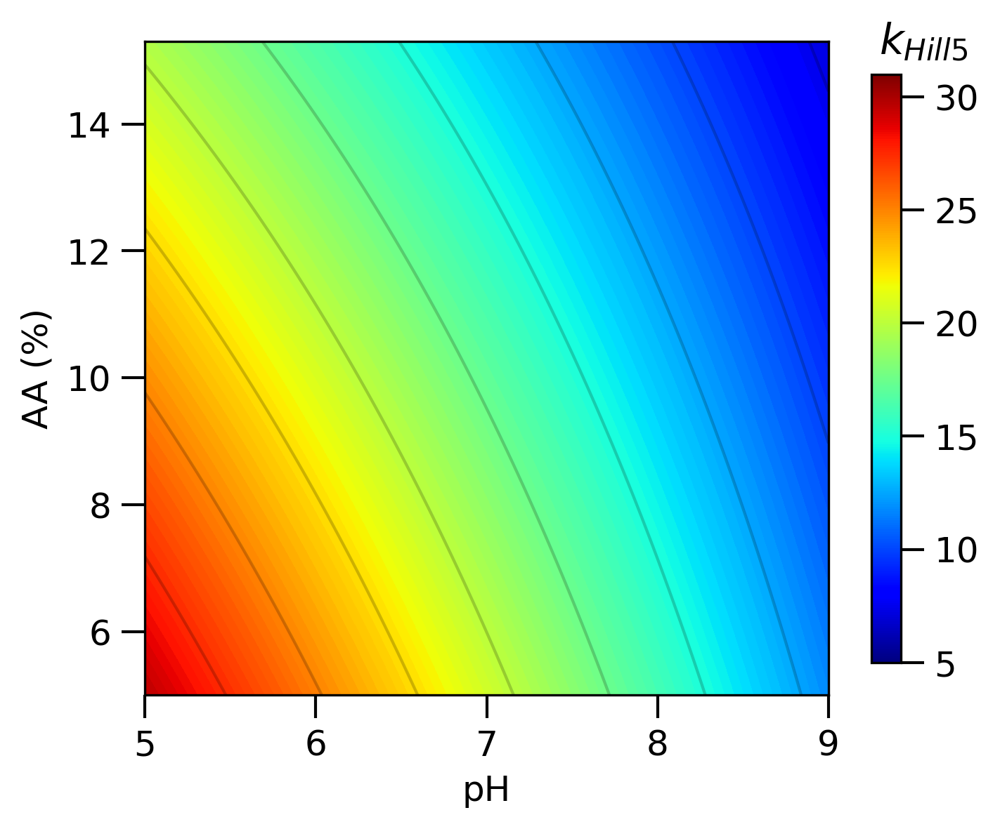

In [41]:
num = 100
coeffs = khills_coeffs_unadj 
factor_3 = -1 if coeffs[3] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1
print(factor_3, factor_4, factor_5)

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_2 = np.linspace(-1, 1, num=num)

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['2'] + factor_units['2']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_2 in enumerate(range_factor_2):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
#             + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
#             + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmax=vmax, vmin=vmin)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2, )
plt.xlabel(xlabel)
plt.ylabel(ylabel)
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)


fig.text(0.85, 0.94, r'$k_{Hill5}$', fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/khills/{factor_names["1"]}_{factor_names["2"]}.png', dpi=300)

### Visualize surfaces - 1-3

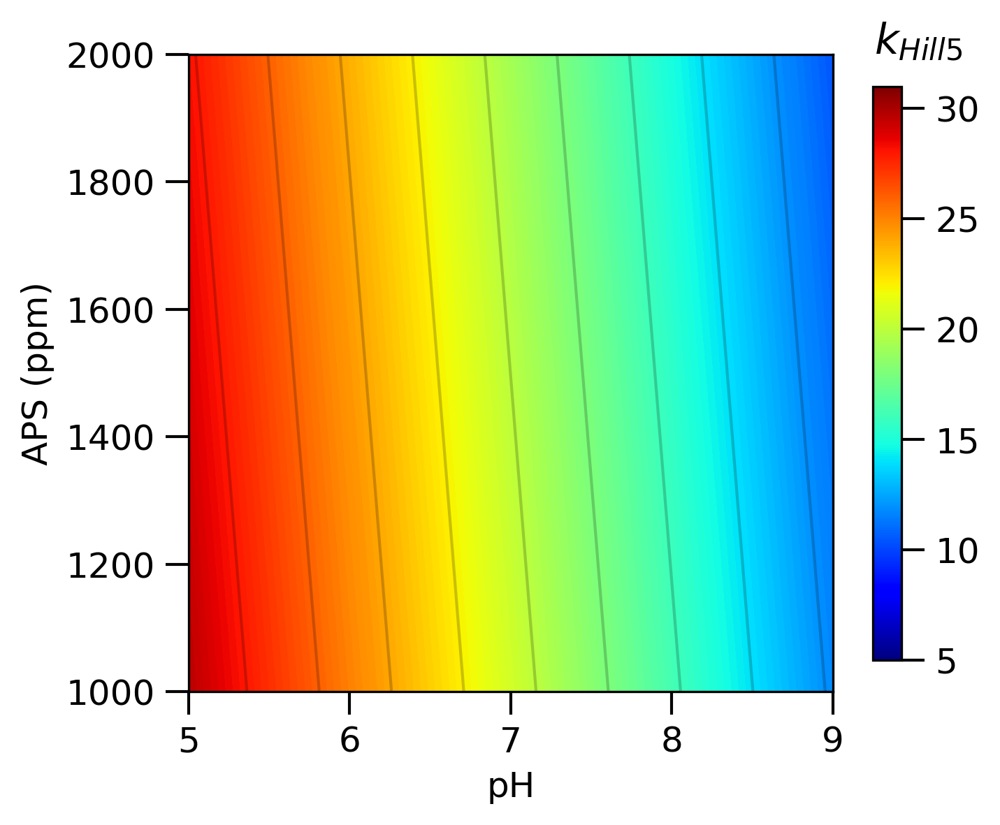

In [42]:
num = 100
coeffs = khills_coeffs_unadj

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_3 = np.linspace(-1, 1, num=num)

factor_2 = -1
factor_4 = 1
factor_5 = 1

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['3'] + factor_units['3']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_3 in enumerate(range_factor_3):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
#             + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
#             + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r'$k_{Hill5}$', fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/khills/{factor_names["1"]}_{factor_names["3"]}.png', dpi=300)

### Visualize Srfaces - 1-4

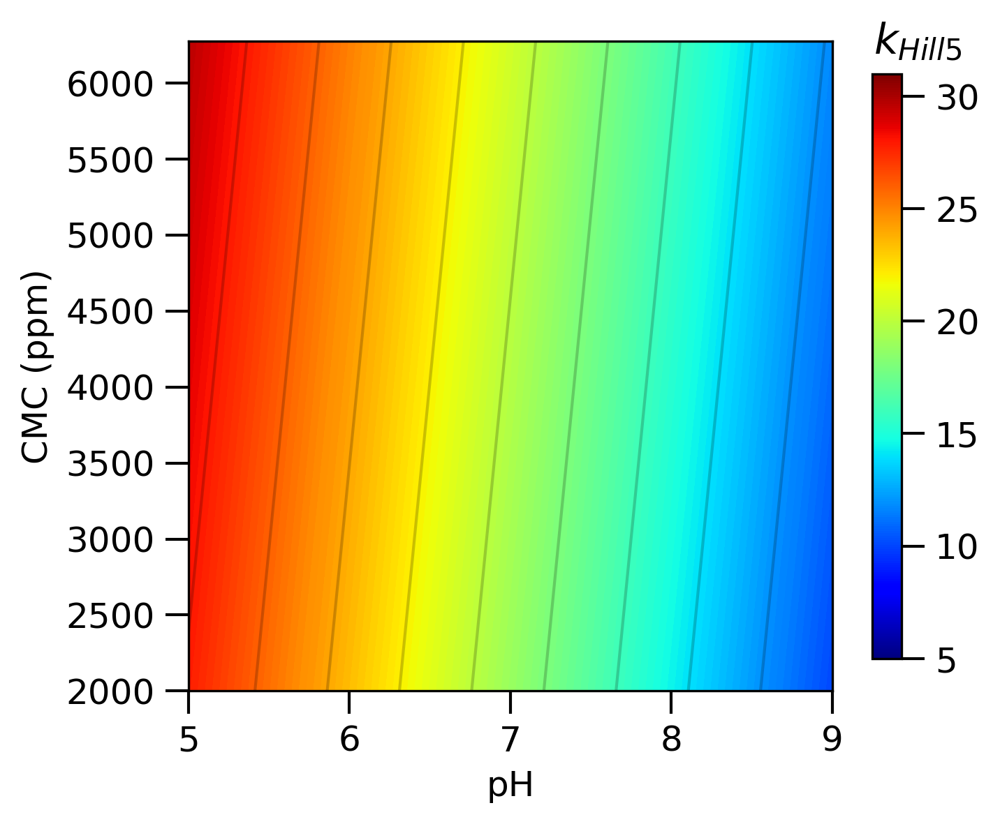

In [43]:
num = 100
coeffs = khills_coeffs_unadj

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_4 = np.linspace(-1, 1, num=num)

factor_2 = -1
factor_3 = -1
factor_5 = 1

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['4'] + factor_units['4']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_4 in enumerate(range_factor_4):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
#             + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
#             + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, ticks=cbar_ticks)
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r'$k_{Hill5}$', fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/khills/{factor_names["1"]}_{factor_names["4"]}.png', dpi=300)

### Visualize Surfaces - 1-5

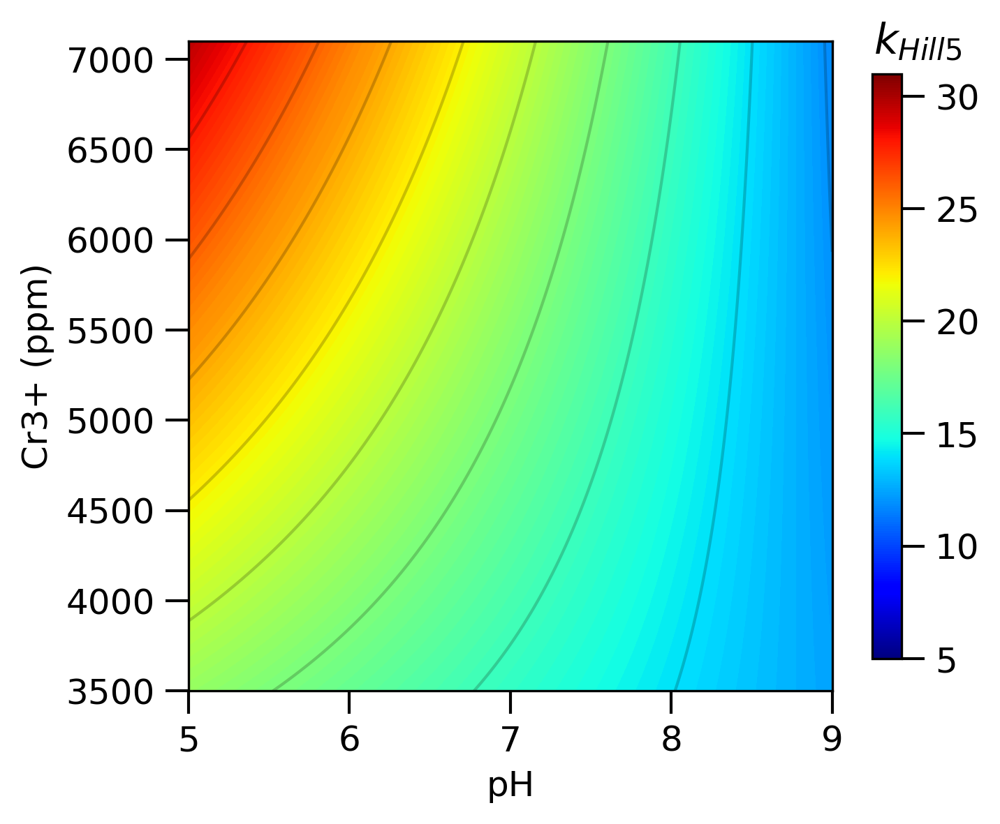

In [44]:
num = 100
coeffs = khills_coeffs_unadj

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_2 = -1
factor_3 = -1
factor_4 = 1

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
#             + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
#             + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, ticks=cbar_ticks)
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r'$k_{Hill5}$', fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/khills/{factor_names["1"]}_{factor_names["5"]}.png', dpi=300)

### Visualize surfaces - 2-3

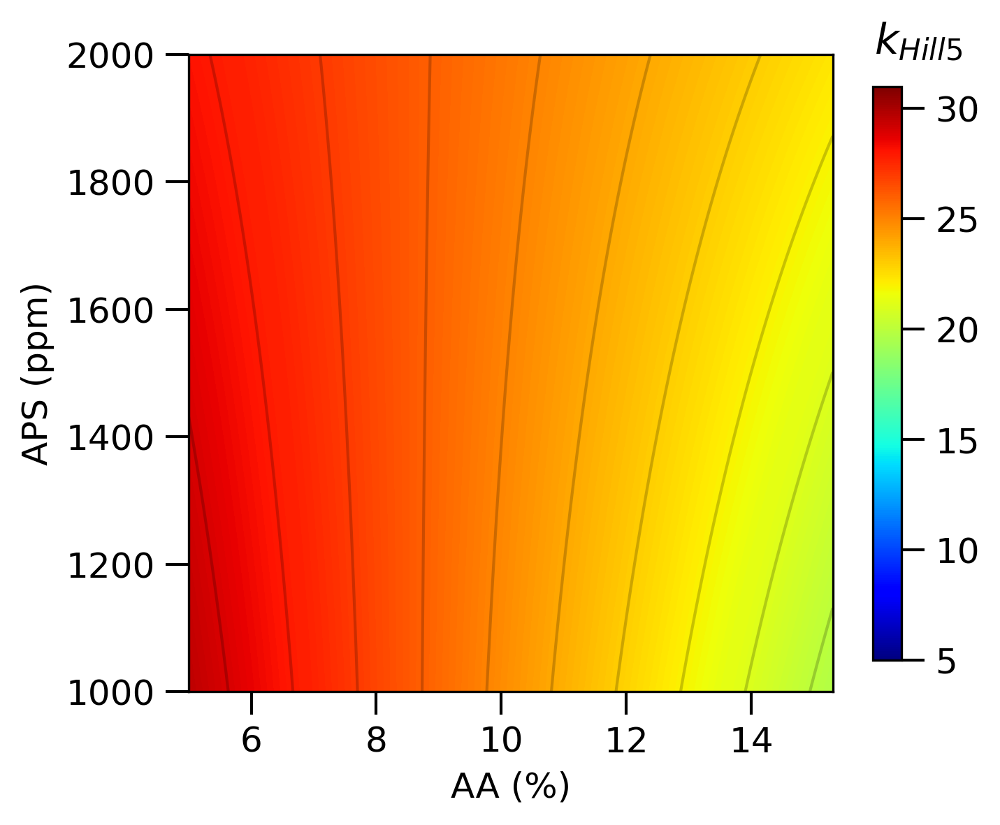

In [45]:
num = 100
coeffs = khills_coeffs_unadj

range_factor_2 = np.linspace(-1, 1, num=num)
range_factor_3 = np.linspace(-1, 1, num=num)

factor_1 = -1
factor_4 = 1
factor_5 = 1

xlabel = factor_names['2'] + factor_units['2']
ylabel = factor_names['3'] + factor_units['3']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_2 in enumerate(range_factor_2):
    for j, factor_3 in enumerate(range_factor_3):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
#             + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
#             + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, ticks=cbar_ticks)
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r'$k_{Hill5}$', fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/khills/{factor_names["2"]}_{factor_names["3"]}.png', dpi=300)

### Visualize Surfaces - 2-4

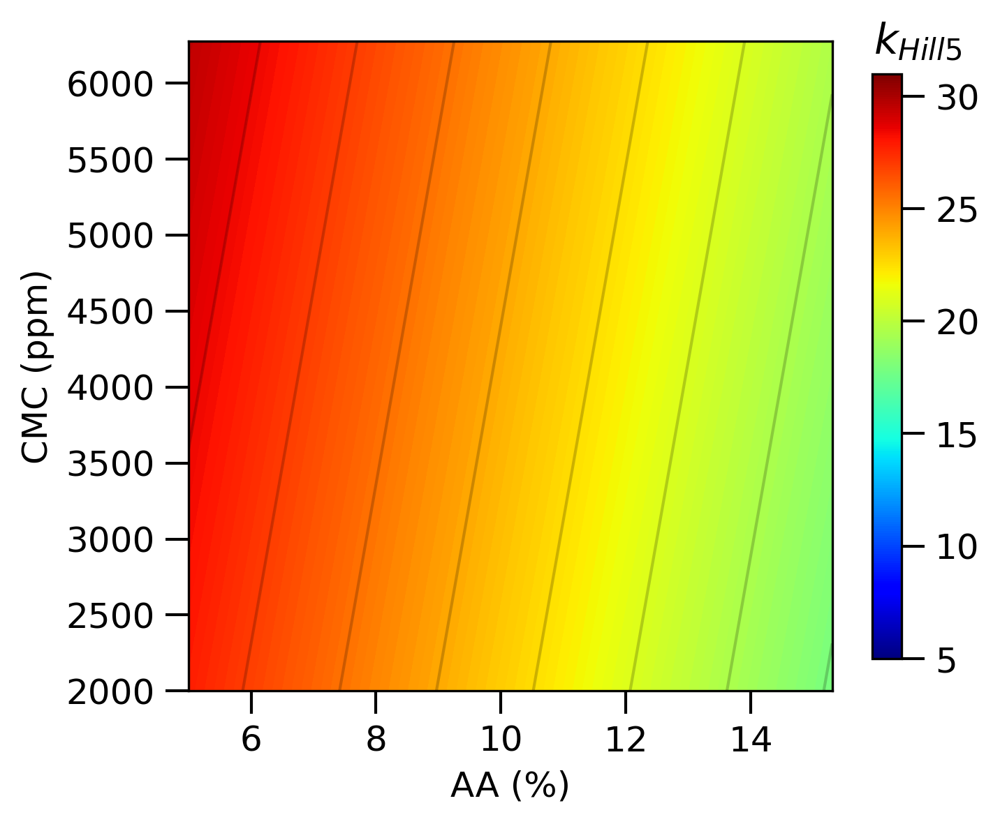

In [46]:
num = 100
coeffs = khills_coeffs_unadj

range_factor_2 = np.linspace(-1, 1, num=num)
range_factor_4 = np.linspace(-1, 1, num=num)

factor_1 = -1
factor_3 = -1
factor_5 = 1

xlabel = factor_names['2'] + factor_units['2']
ylabel = factor_names['4'] + factor_units['4']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_2 in enumerate(range_factor_2):
    for j, factor_4 in enumerate(range_factor_4):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
#             + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
#             + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, ticks=cbar_ticks)
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r'$k_{Hill5}$', fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/khills/{factor_names["2"]}_{factor_names["4"]}.png', dpi=300)

### Visualize surfaces - 2-5

-1 -1 1


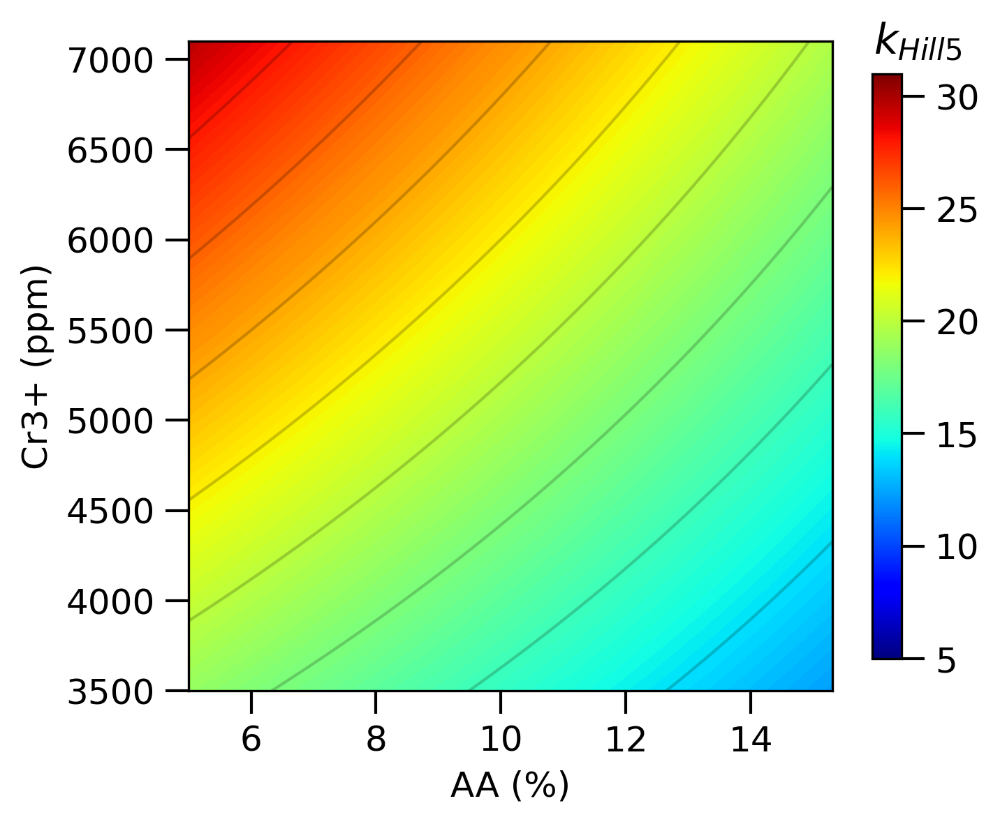

In [47]:
num = 100
coeffs = khills_coeffs_unadj

range_factor_2 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
print(factor_1, factor_3, factor_4)

xlabel = factor_names['2'] + factor_units['2']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_2 in enumerate(range_factor_2):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
#             + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
#             + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, ticks=cbar_ticks)
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r'$k_{Hill5}$', fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/khills/{factor_names["2"]}_{factor_names["5"]}.png', dpi=300)

### Visualize surfaces - 3-4

-1 -1 1


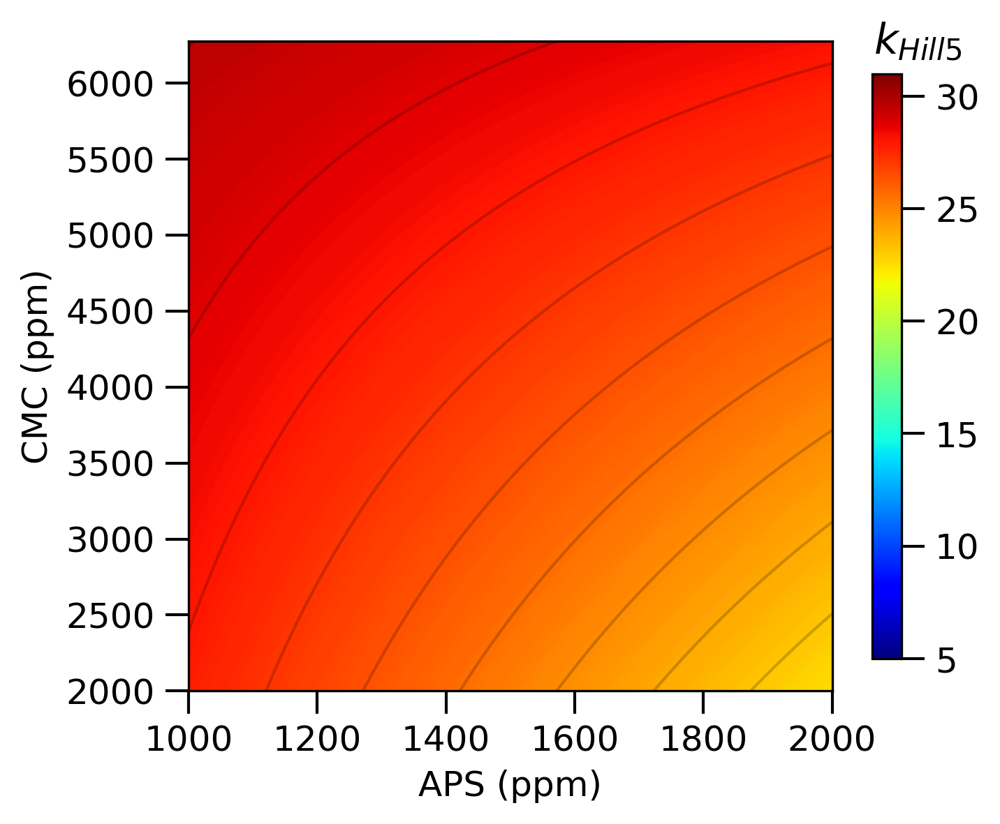

In [48]:
num = 100
coeffs = khills_coeffs_unadj

range_factor_3 = np.linspace(-1, 1, num=num)
range_factor_4 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_2 = -1 if coeffs[2] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1
print(factor_1, factor_2, factor_5)

xlabel = factor_names['3'] + factor_units['3']
ylabel = factor_names['4'] + factor_units['4']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_3 in enumerate(range_factor_3):
    for j, factor_4 in enumerate(range_factor_4):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
#             + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
#             + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, ticks=cbar_ticks)
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r'$k_{Hill5}$', fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/khills/{factor_names["3"]}_{factor_names["4"]}.png', dpi=300)

### Visualize surfaces - 3-5

-1 -1 1


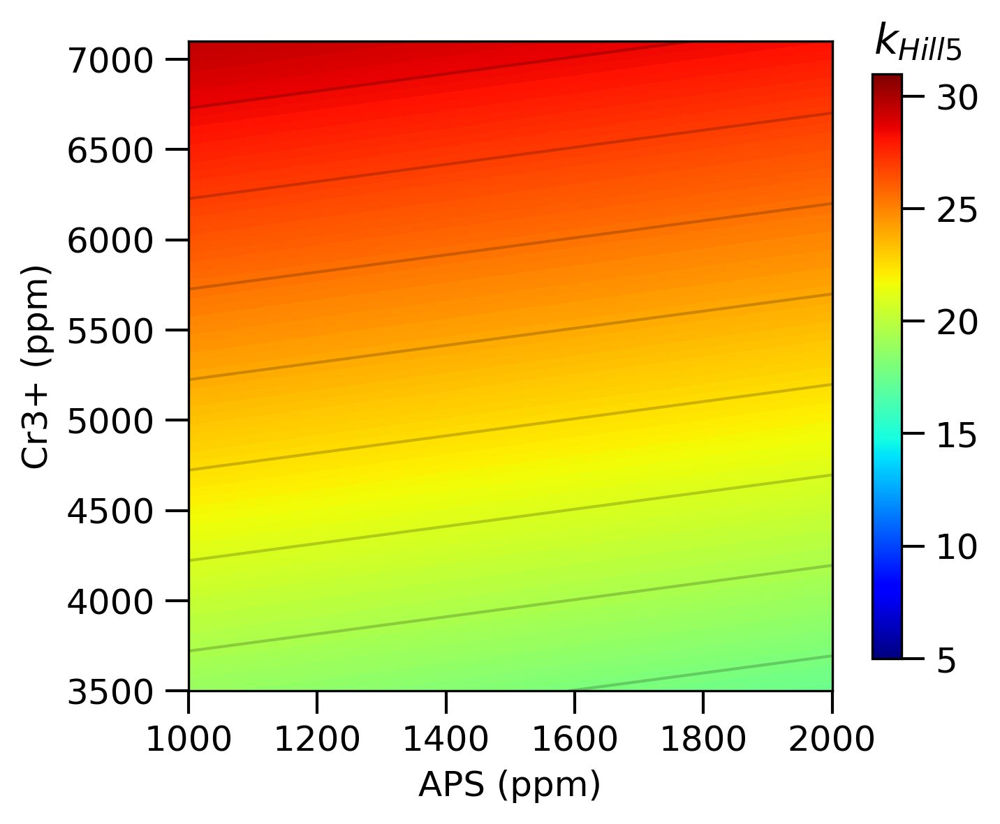

In [49]:
num = 100
coeffs = khills_coeffs_unadj

range_factor_3 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_2 = -1 if coeffs[2] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
print(factor_1, factor_2, factor_4)

xlabel = factor_names['3'] + factor_units['3']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_3 in enumerate(range_factor_3):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
#             + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
#             + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9)
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r'$k_{Hill5}$', fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/khills/{factor_names["3"]}_{factor_names["5"]}.png', dpi=300)

### Visualize surfaces - 4-5

-1 -1 -1


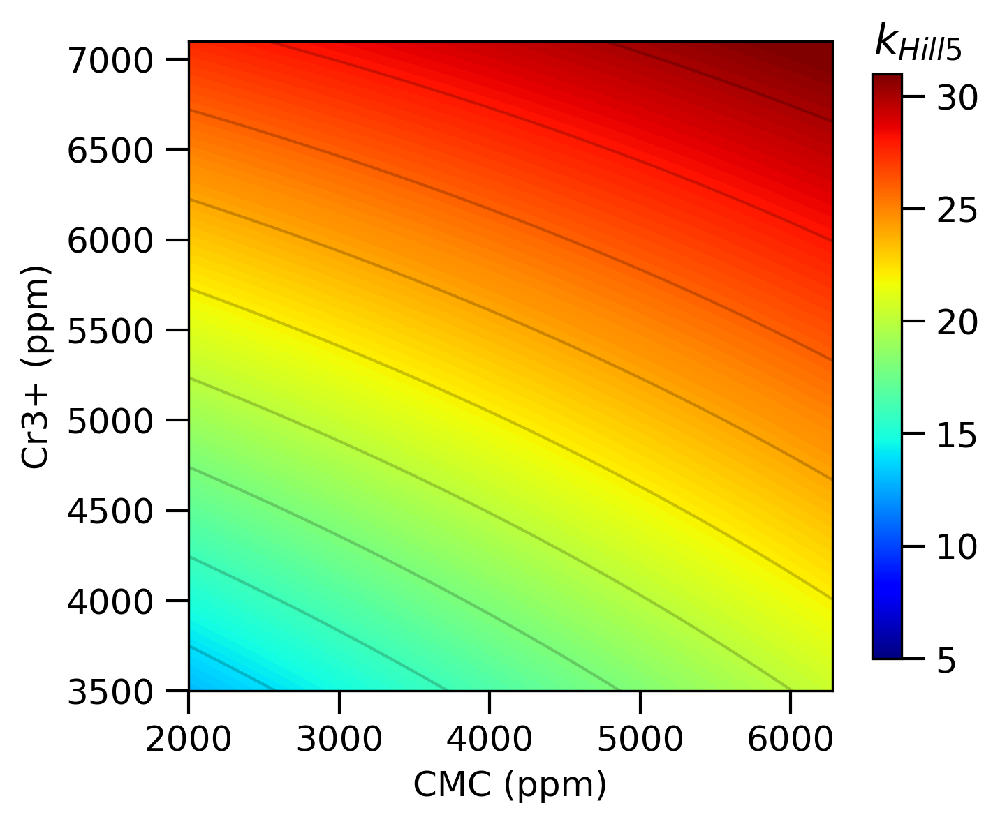

In [50]:
num = 100
coeffs = khills_coeffs_unadj

range_factor_4 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_2 = -1 if coeffs[2] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
print(factor_1, factor_2, factor_3)

xlabel = factor_names['4'] + factor_units['4']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_4 in enumerate(range_factor_4):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
            + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, ticks=cbar_ticks)
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r'$k_{Hill5}$', fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/khills/{factor_names["4"]}_{factor_names["5"]}.png', dpi=300)

## G0

### Unadjusted

In [51]:
Gplateau_coeffs_unadj = regression(XX.to_numpy(), responses['Gplateau'])

In [52]:
Gplateau_predictions_unadj = predict(XX.to_numpy(), Gplateau_coeffs_unadj)

In [53]:
anova = perform_ANOVA(
    responses["Gplateau"],
    Gplateau_predictions_unadj,
    responses["Gplateau"][["exp17", "exp18", "exp19"]],
    Gplateau_predictions_unadj[-3:],
    16,
    19,
    17,
    confidence=0.95,
)
anovas['Gplateau_unadj'] = anova

In [54]:
Gplateau_errors_unadj = calculate_errors(XX, sigma_Gplat)

In [55]:
determine_valid_coeffs(XX.columns, Gplateau_coeffs_unadj, Gplateau_errors_unadj)

0: 2348.926 +/- 81.114: True
1: -1249.921 +/- 88.392: True
2: 2153.712 +/- 88.392: True
3: 21.231 +/- 88.392: False
4: 223.540 +/- 88.392: True
5: 231.004 +/- 88.392: True
1v2: -913.181 +/- 88.392: True
1v3: -13.561 +/- 88.392: False
1v4: 203.511 +/- 88.392: True
1v5: -100.411 +/- 88.392: True
2v3: 56.147 +/- 88.392: False
2v4: 86.643 +/- 88.392: False
2v5: -23.151 +/- 88.392: False
3v4: 73.868 +/- 88.392: False
3v5: 268.418 +/- 88.392: True
4v5: 33.636 +/- 88.392: False
Valids: ['0', '1', '2', '3', '4', '5', '1v2', '1v4', '1v5', '3v5']
Invalids: ['1v3', '2v3', '2v4', '2v5', '3v4', '4v5']


### Adjusted

In [56]:
cols = ['0', '1', '2', '3', '4', '5', '1v2', '1v4', '3v5']
Gplateau_coeffs_adj = regression(XX[cols].to_numpy(), responses['Gplateau'])
coefficients['Gplateau'] = cols

In [57]:
Gplateau_predictions_adj = predict(XX[cols].to_numpy(), Gplateau_coeffs_adj)
Gplateau_predictions_adj

array([ 453.28066313, -552.39460976, 6661.89300295, 1853.84087451,
         33.73383068,  -47.92388909, 7166.36372362, 1434.29404206,
        568.16548245,  226.87945646, 6627.12334278, 2782.76942022,
       1072.63620312, -192.66737599, 6207.57651033, 3287.24014089,
       2348.92567614, 2348.92567614, 2348.92567614])

In [58]:
anova = perform_ANOVA(
    responses["Gplateau"],
    Gplateau_predictions_adj,
    responses["Gplateau"][["exp17", "exp18", "exp19"]],
    Gplateau_predictions_adj[-3:],
    10,
    19,
    17,
    confidence=0.95,
)
anovas['Gplateau_adj'] = anova

In [59]:
Gplateau_errors_adj = calculate_errors(XX[cols], sigma_Gplat)

In [60]:
Gplateau_intervals_adj = calculate_interval(Gplateau_errors_adj, 2, 0.95)

In [61]:
determine_valid_coeffs(XX[cols].columns, Gplateau_coeffs_adj, Gplateau_errors_adj)

0: 2348.926 +/- 81.114: True
1: -1249.921 +/- 88.392: True
2: 2153.712 +/- 88.392: True
3: 21.231 +/- 88.392: False
4: 223.540 +/- 88.392: True
5: 231.004 +/- 88.392: True
1v2: -913.181 +/- 88.392: True
1v4: 203.511 +/- 88.392: True
3v5: 268.418 +/- 88.392: True
Valids: ['0', '1', '2', '3', '4', '5', '1v2', '1v4', '3v5']
Invalids: []


### Visualize surfaces - 1-2

Factors will have fixed values of the same sign as their exponents

In [62]:
vmin = 0
vmax = 7500
cbar_ticks = [0, 1000, 2000, 3000, 4000, 5000, 6000, 7000]


1 1 1


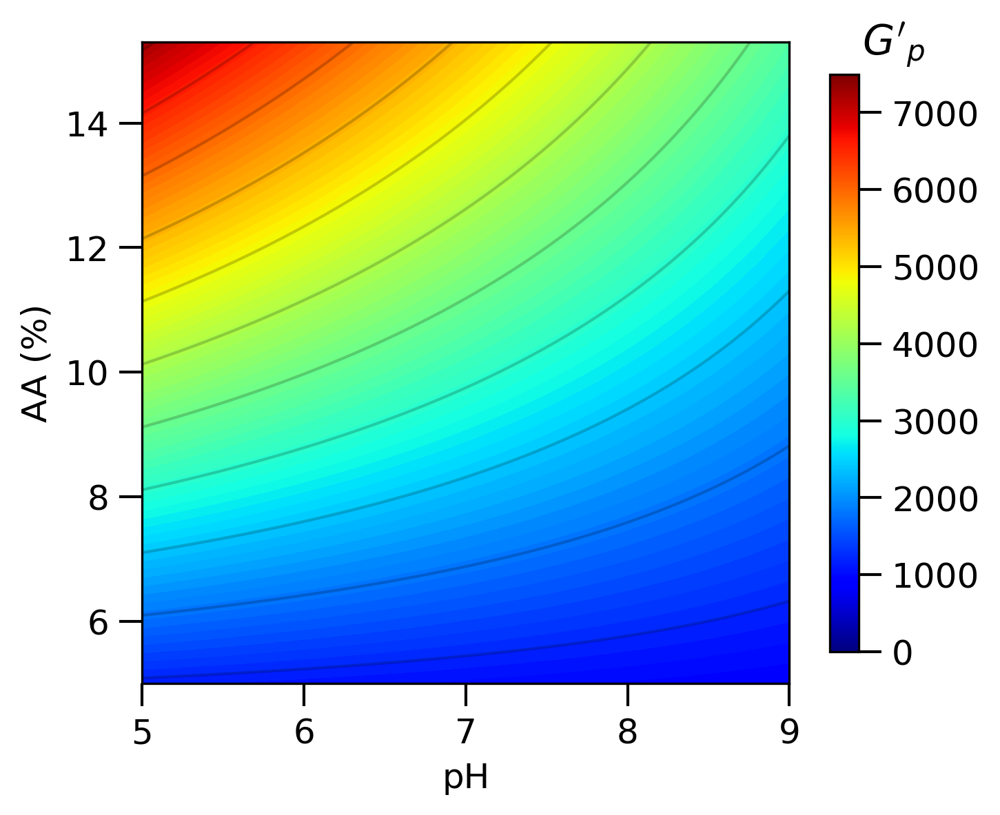

In [63]:
num = 100
coeffs = Gplateau_coeffs_unadj 
factor_3 = -1 if coeffs[3] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1
print(factor_3, factor_4, factor_5)

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_2 = np.linspace(-1, 1, num=num)

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['2'] + factor_units['2']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_2 in enumerate(range_factor_2):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
#             + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2, )
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)


fig.text(0.85, 0.94, r"$G'_{p}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/g0/{factor_names["1"]}_{factor_names["2"]}.png', dpi=300)

### Visualize surfaces - 1-3

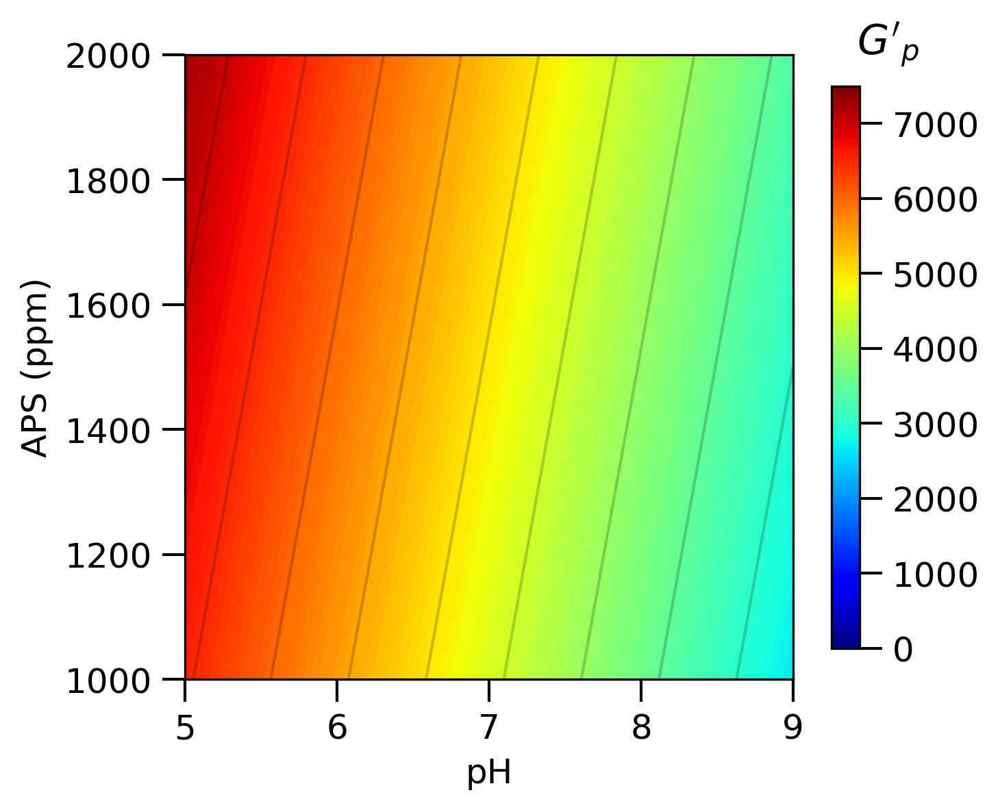

In [64]:
num = 100
coeffs = Gplateau_coeffs_unadj

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_3 = np.linspace(-1, 1, num=num)

factor_2 = -1 if coeffs[2] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['3'] + factor_units['3']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_3 in enumerate(range_factor_3):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
#             + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'_{p}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/g0/{factor_names["1"]}_{factor_names["3"]}.png', dpi=300)

### Visualize Srfaces - 1-4

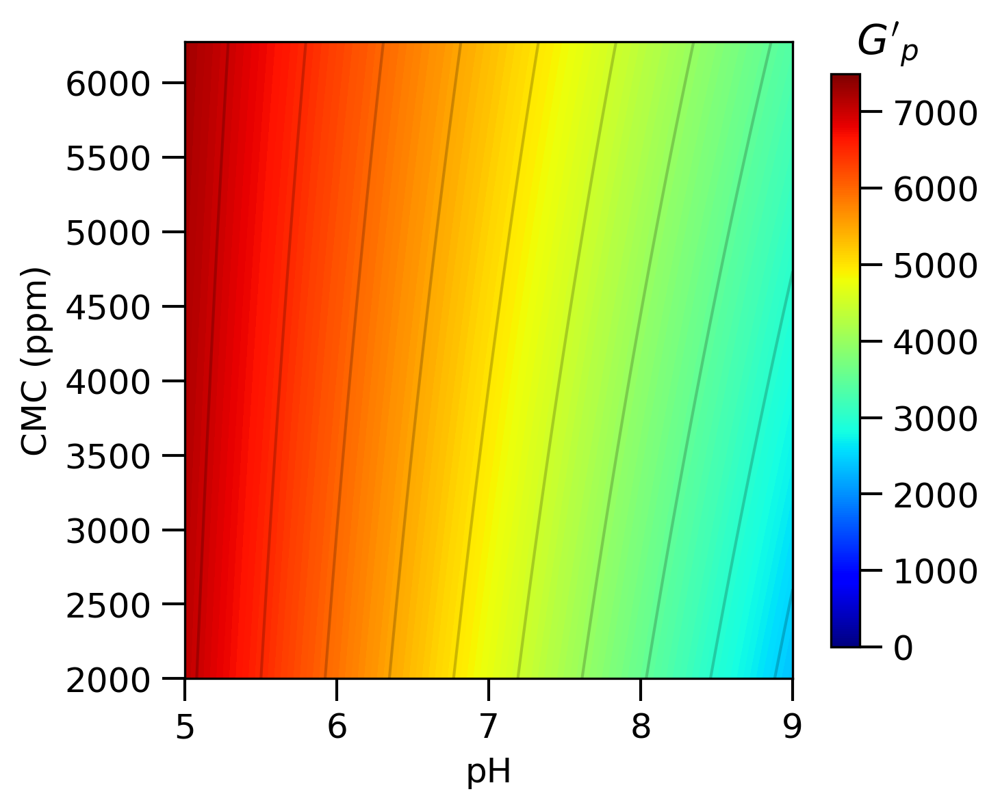

In [65]:
num = 100
coeffs = Gplateau_coeffs_unadj

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_4 = np.linspace(-1, 1, num=num)

factor_2 = -1 if coeffs[2] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['4'] + factor_units['4']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_4 in enumerate(range_factor_4):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
#             + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'_{p}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/g0/{factor_names["1"]}_{factor_names["4"]}.png', dpi=300)

### Visualize Surfaces - 1-5

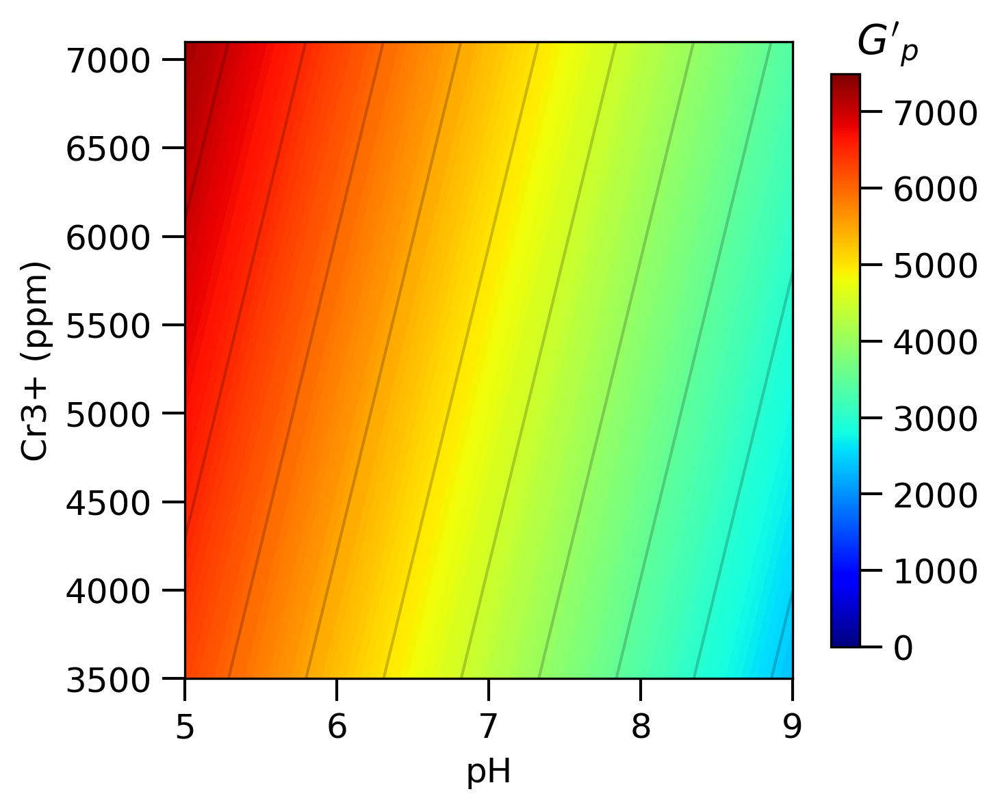

In [66]:
num = 100
coeffs = Gplateau_coeffs_unadj

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_2 = -1 if coeffs[2] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
#             + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'_{p}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/g0/{factor_names["1"]}_{factor_names["5"]}.png', dpi=300)

### Visualize surfaces - 2-3

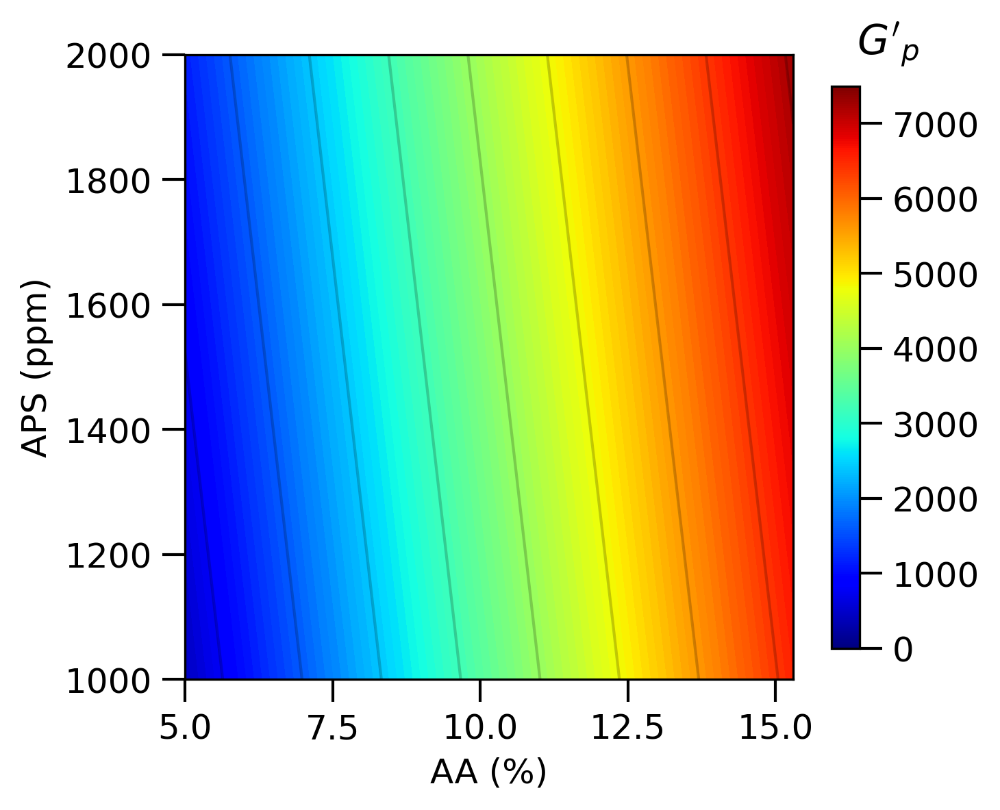

In [67]:
num = 100
coeffs = Gplateau_coeffs_unadj

range_factor_2 = np.linspace(-1, 1, num=num)
range_factor_3 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1

xlabel = factor_names['2'] + factor_units['2']
ylabel = factor_names['3'] + factor_units['3']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_2 in enumerate(range_factor_2):
    for j, factor_3 in enumerate(range_factor_3):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
#             + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'_{p}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/g0/{factor_names["2"]}_{factor_names["3"]}.png', dpi=300)

### Visualize Surfaces - 2-4

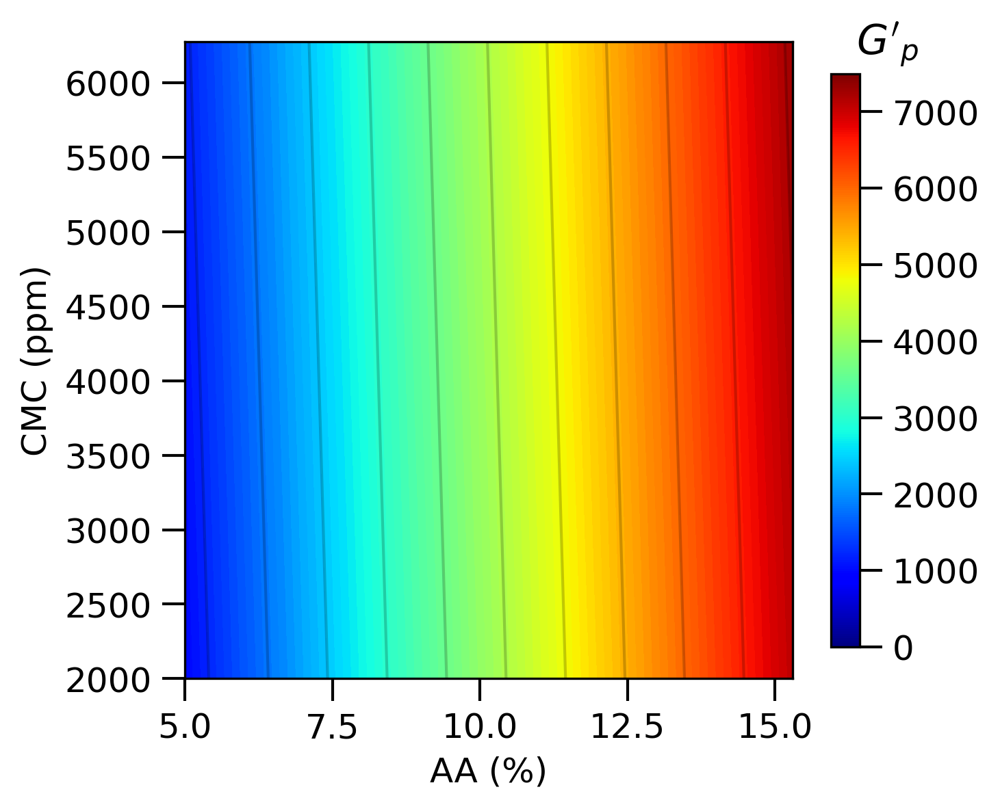

In [68]:
num = 100
coeffs = Gplateau_coeffs_unadj

range_factor_2 = np.linspace(-1, 1, num=num)
range_factor_4 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1

xlabel = factor_names['2'] + factor_units['2']
ylabel = factor_names['4'] + factor_units['4']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_2 in enumerate(range_factor_2):
    for j, factor_4 in enumerate(range_factor_4):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
#             + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'_{p}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/g0/{factor_names["2"]}_{factor_names["4"]}.png', dpi=300)

### Visualize surfaces - 2-5

-1 1 1


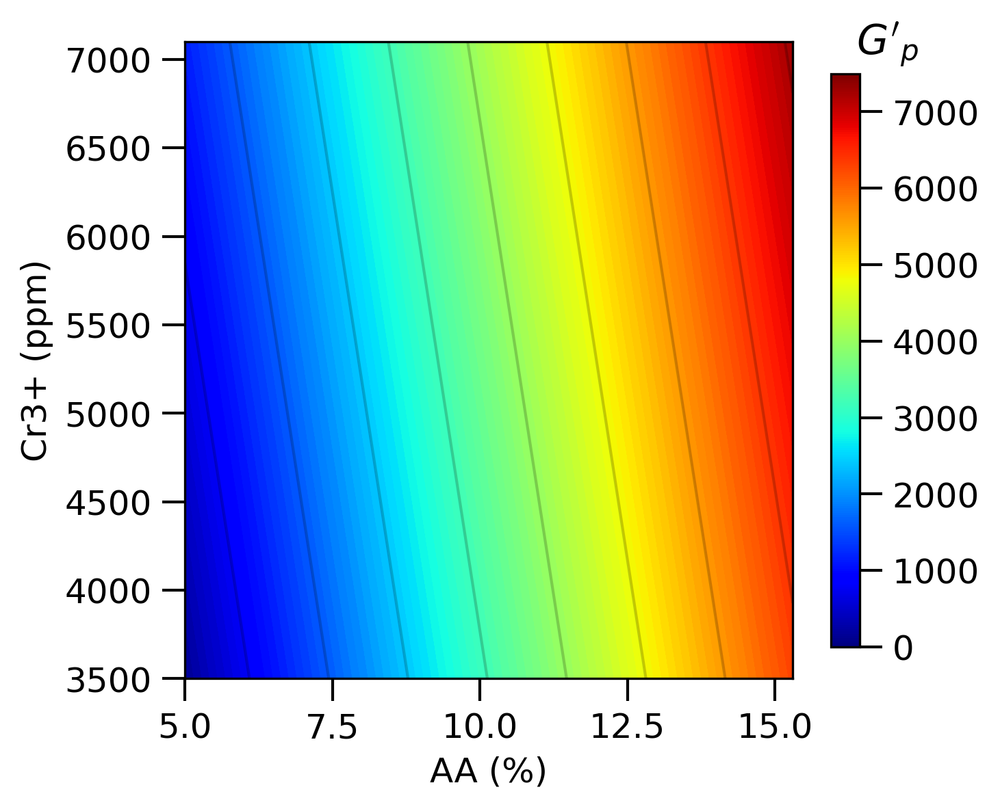

In [69]:
num = 100
coeffs = Gplateau_coeffs_unadj

range_factor_2 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
print(factor_1, factor_3, factor_4)

xlabel = factor_names['2'] + factor_units['2']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_2 in enumerate(range_factor_2):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
#             + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'_{p}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/g0/{factor_names["2"]}_{factor_names["5"]}.png', dpi=300)

### Visualize surfaces - 3-4

-1 1 1


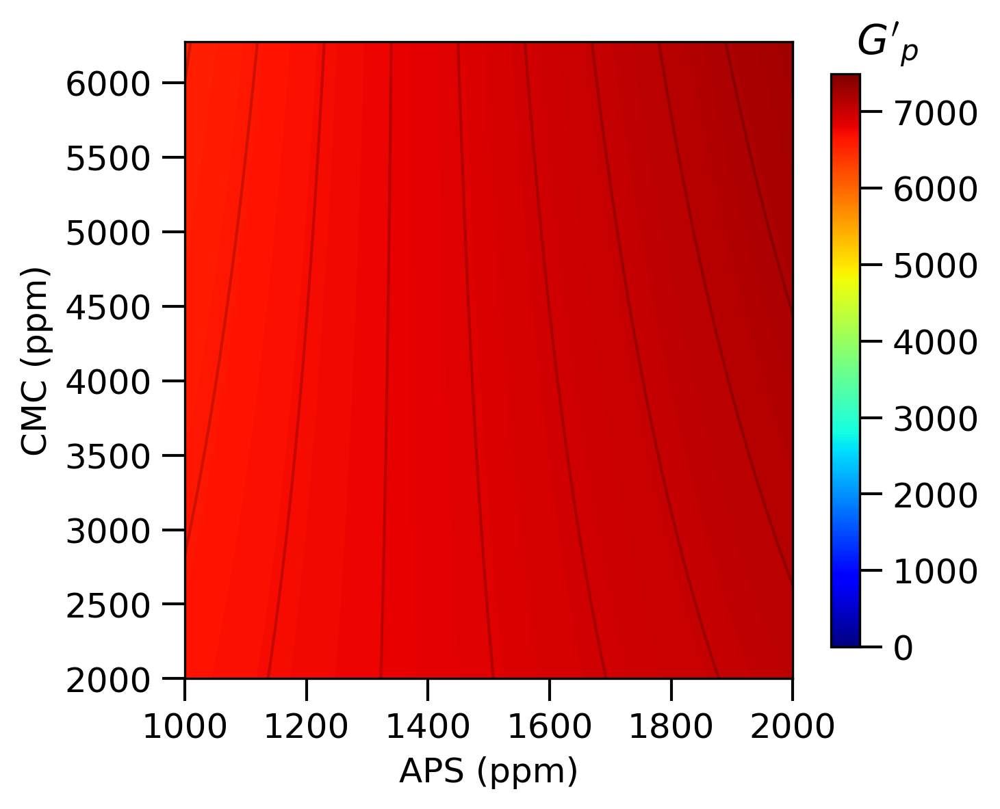

In [70]:
num = 100
coeffs = Gplateau_coeffs_unadj

range_factor_3 = np.linspace(-1, 1, num=num)
range_factor_4 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_2 = -1 if coeffs[2] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1
print(factor_1, factor_2, factor_5)

xlabel = factor_names['3'] + factor_units['3']
ylabel = factor_names['4'] + factor_units['4']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_3 in enumerate(range_factor_3):
    for j, factor_4 in enumerate(range_factor_4):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
#             + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'_{p}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/g0/{factor_names["3"]}_{factor_names["4"]}.png', dpi=300)

### Visualize surfaces - 3-5

-1 1 1


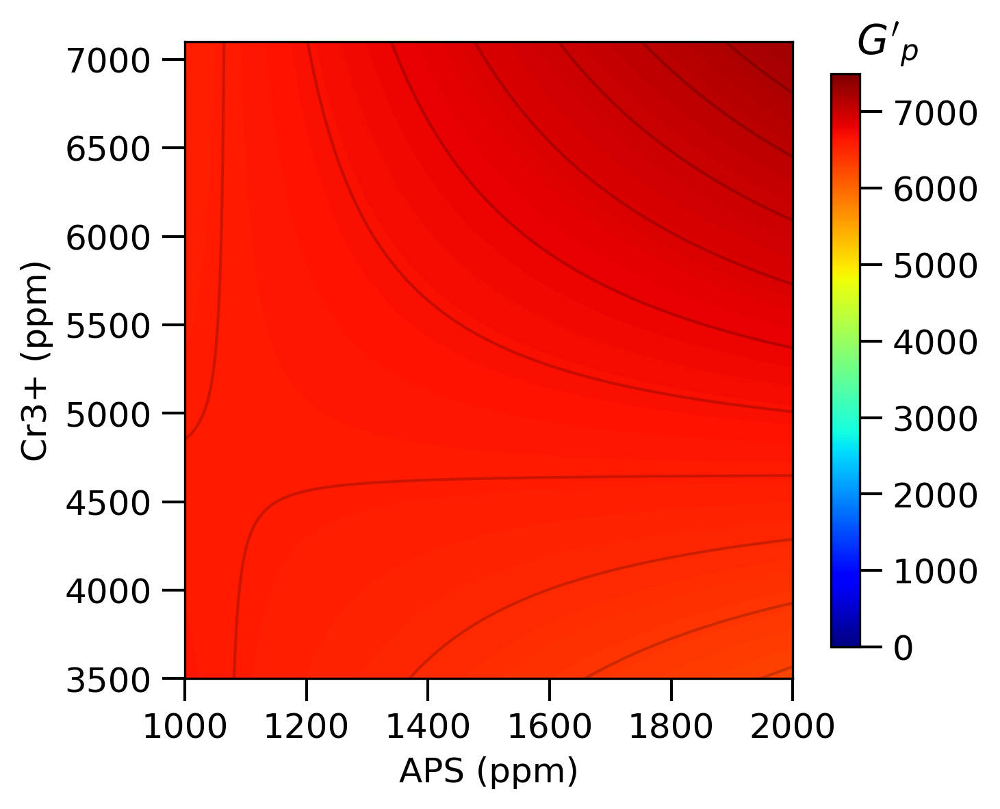

In [71]:
num = 100
coeffs = Gplateau_coeffs_unadj

range_factor_3 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_2 = -1 if coeffs[2] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
print(factor_1, factor_2, factor_4)

xlabel = factor_names['3'] + factor_units['3']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_3 in enumerate(range_factor_3):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
#             + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'_{p}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/g0/{factor_names["3"]}_{factor_names["5"]}.png', dpi=300)

### Visualize surfaces - 4-5

-1 1 1


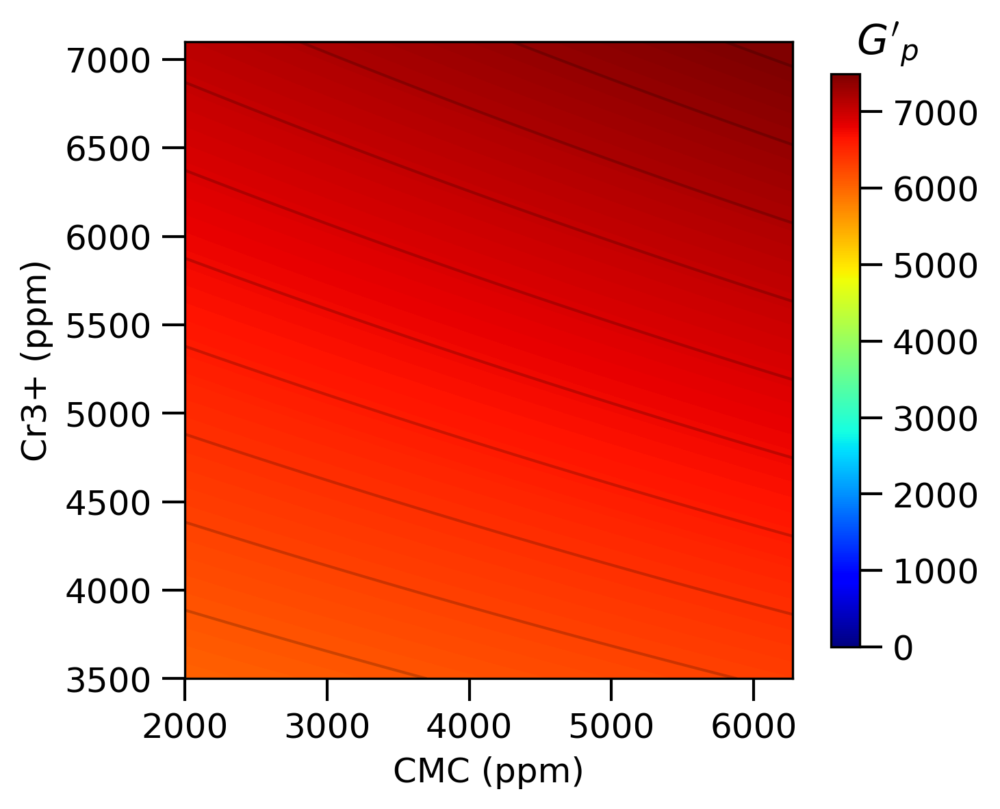

In [72]:
num = 100
coeffs = Gplateau_coeffs_unadj

range_factor_4 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_2 = -1 if coeffs[2] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
print(factor_1, factor_2, factor_3)

xlabel = factor_names['4'] + factor_units['4']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_4 in enumerate(range_factor_4):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
            + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'_{p}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/g0/{factor_names["4"]}_{factor_names["5"]}.png', dpi=300)

## Gmax

### Unadjusted

In [73]:
Gmax_coeffs_unadj = regression(XX.to_numpy(), responses['Gmax'])

In [74]:
Gmax_predictions_unadj = predict(XX.to_numpy(), Gmax_coeffs_unadj)

In [75]:
anova = perform_ANOVA(
    responses["Gmax"],
    Gmax_predictions_unadj,
    responses["Gmax"][["exp17", "exp18", "exp19"]],
    Gmax_predictions_unadj[-3:],
    16,
    19,
    17,
    confidence=0.95,
)
anovas['Gmax_unadj'] = anova
anova

ANOVA(SqR=127642486.61728376, Sqr=3931353.312759935, Sqfaj=2564881.476683733, Sqep=885556.559198, SqT=131573839.9300437, R2=0.9701205550066017, R2max=0.993269508895774, num_parameters_p=16, num_observations_n=19, num_levels_m=17, MqR=8509499.107818918, Mqr=1310451.1042533116, Mqfaj=2564881.476683733, Mqep=442778.279599, Ffaj=5.79269940478247, FR=6.493564758120134, Ftab_faj=18.512820512820497, Ftab_R=8.70287013489668, passed_Ffaj=True, passed_FR=False)

In [76]:
Gmax_errors_unadj = calculate_errors(XX, sigma_Gmax)

In [77]:
determine_valid_coeffs(XX.columns, Gmax_coeffs_unadj, Gmax_errors_unadj)

0: 2868.596 +/- 152.657: True
1: -864.456 +/- 166.354: True
2: 2496.328 +/- 166.354: True
3: 372.531 +/- 166.354: True
4: 334.957 +/- 166.354: True
5: 302.776 +/- 166.354: True
1v2: -574.882 +/- 166.354: True
1v3: -80.048 +/- 166.354: False
1v4: 143.845 +/- 166.354: False
1v5: -228.183 +/- 166.354: True
2v3: 392.441 +/- 166.354: True
2v4: 210.331 +/- 166.354: True
2v5: 29.024 +/- 166.354: False
3v4: -106.497 +/- 166.354: False
3v5: 189.281 +/- 166.354: True
4v5: 12.475 +/- 166.354: False
Valids: ['0', '1', '2', '3', '4', '5', '1v2', '1v5', '2v3', '2v4', '3v5']
Invalids: ['1v3', '1v4', '2v5', '3v4', '4v5']


### Adjusted

In [78]:
cols = ['0', '1', '2', '3', '4', '5', '1v2', '1v5', '2v3', '2v4', '3v5']
Gmax_coeffs_adj = regression(XX[cols].to_numpy(), responses['Gmax'])
coefficients['Gmax'] = cols

In [79]:
Gmax_predictions_adj = predict(XX[cols].to_numpy(), Gmax_coeffs_adj)

In [80]:
anova = perform_ANOVA(
    responses["Gmax"],
    Gmax_predictions_adj,
    responses["Gmax"][["exp17", "exp18", "exp19"]],
    Gmax_predictions_adj[-3:],
    11,
    19,
    17,
    confidence=0.95,
)
anovas['Gmax_adj'] = anova

In [81]:
Gmax_errors_adj = calculate_errors(XX[cols], sigma_Gmax)

In [82]:
Gmax_intervals_adj = calculate_interval(Gmax_errors_adj, 2, 0.95)

In [83]:
determine_valid_coeffs(XX[cols].columns, Gmax_coeffs_adj, Gmax_errors_adj)

0: 2868.596 +/- 152.657: True
1: -864.456 +/- 166.354: True
2: 2496.328 +/- 166.354: True
3: 372.531 +/- 166.354: True
4: 334.957 +/- 166.354: True
5: 302.776 +/- 166.354: True
1v2: -574.882 +/- 166.354: True
1v5: -228.183 +/- 166.354: True
2v3: 392.441 +/- 166.354: True
2v4: 210.331 +/- 166.354: True
3v5: 189.281 +/- 166.354: True
Valids: ['0', '1', '2', '3', '4', '5', '1v2', '1v5', '2v3', '2v4', '3v5']
Invalids: []


### Visualize surfaces - 1-2

Factors will have fixed values of the same sign as their exponents

In [84]:
vmin = 0
vmax = 9500
cbar_ticks = [0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000]

1 1 1


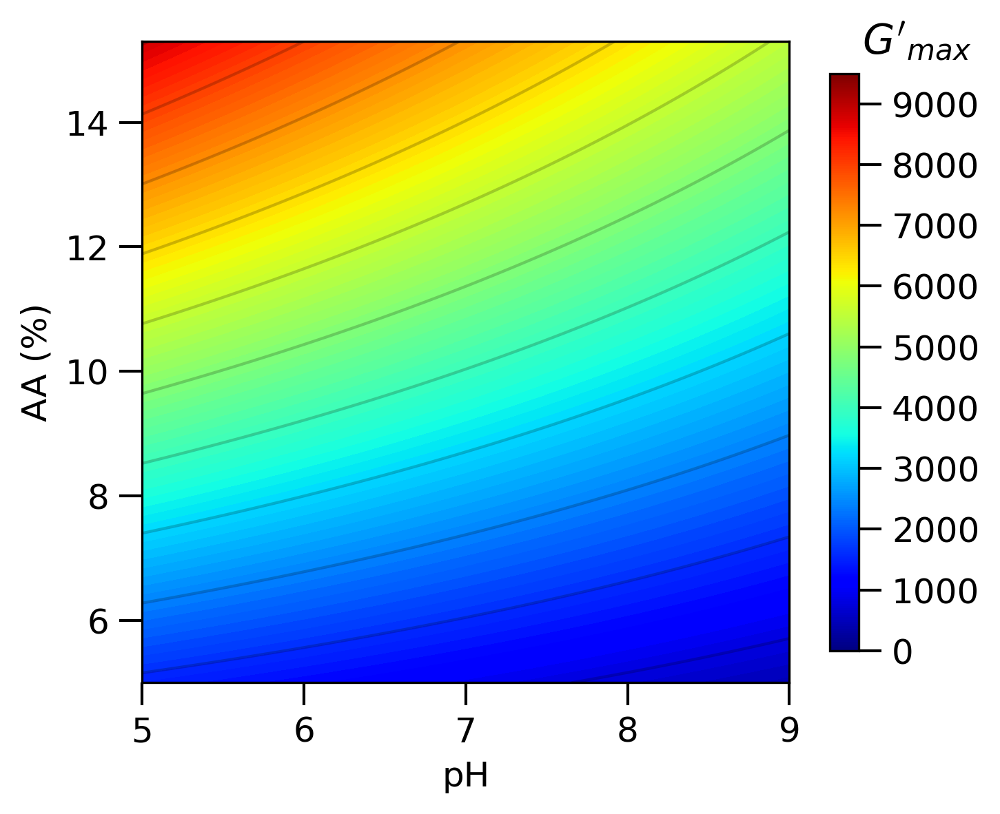

In [85]:
num = 100
coeffs = Gmax_coeffs_unadj 
factor_3 = -1 if coeffs[3] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1
print(factor_3, factor_4, factor_5)

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_2 = np.linspace(-1, 1, num=num)

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['2'] + factor_units['2']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_2 in enumerate(range_factor_2):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
#             + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2, )
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)


fig.text(0.85, 0.94, r"$G'_{max}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gmax/{factor_names["1"]}_{factor_names["2"]}.png', dpi=300)

### Visualize surfaces - 1-3

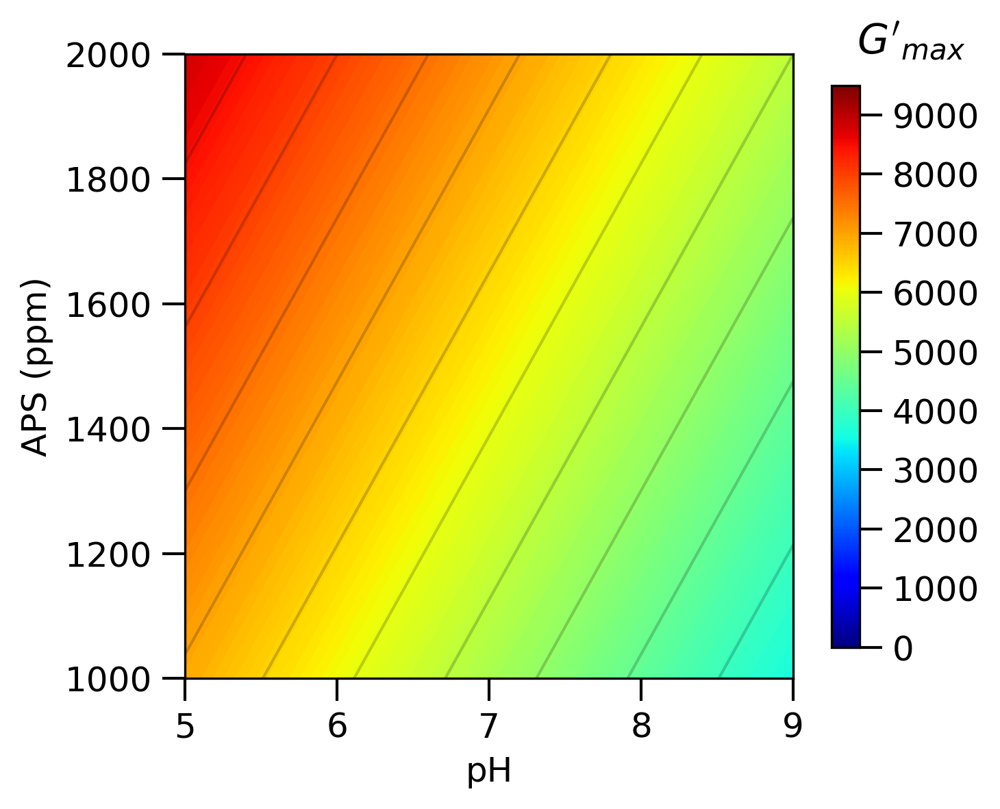

In [86]:
num = 100
coeffs = Gmax_coeffs_unadj

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_3 = np.linspace(-1, 1, num=num)

factor_2 = -1 if coeffs[2] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['3'] + factor_units['3']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_3 in enumerate(range_factor_3):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
#             + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'_{max}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gmax/{factor_names["1"]}_{factor_names["3"]}.png', dpi=300)


### Visualize Srfaces - 1-4

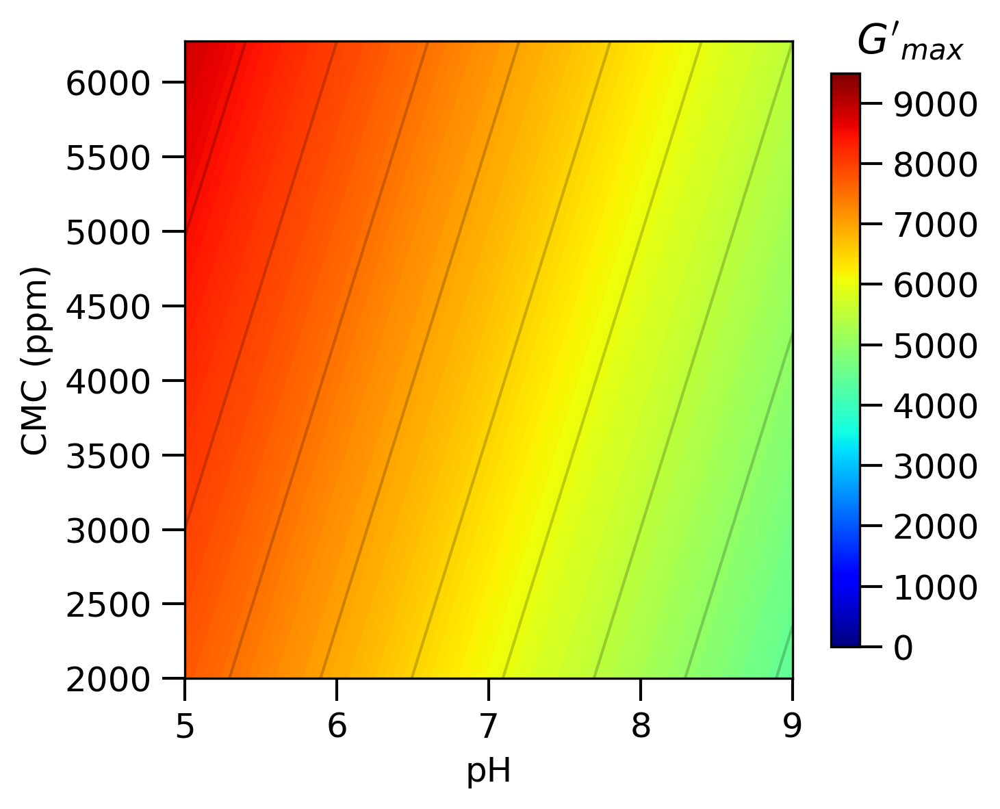

In [87]:
num = 100
coeffs = Gmax_coeffs_unadj

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_4 = np.linspace(-1, 1, num=num)

factor_2 = -1 if coeffs[2] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['4'] + factor_units['4']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_4 in enumerate(range_factor_4):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
#             + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'_{max}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gmax/{factor_names["1"]}_{factor_names["4"]}.png', dpi=300)


### Visualize Surfaces - 1-5

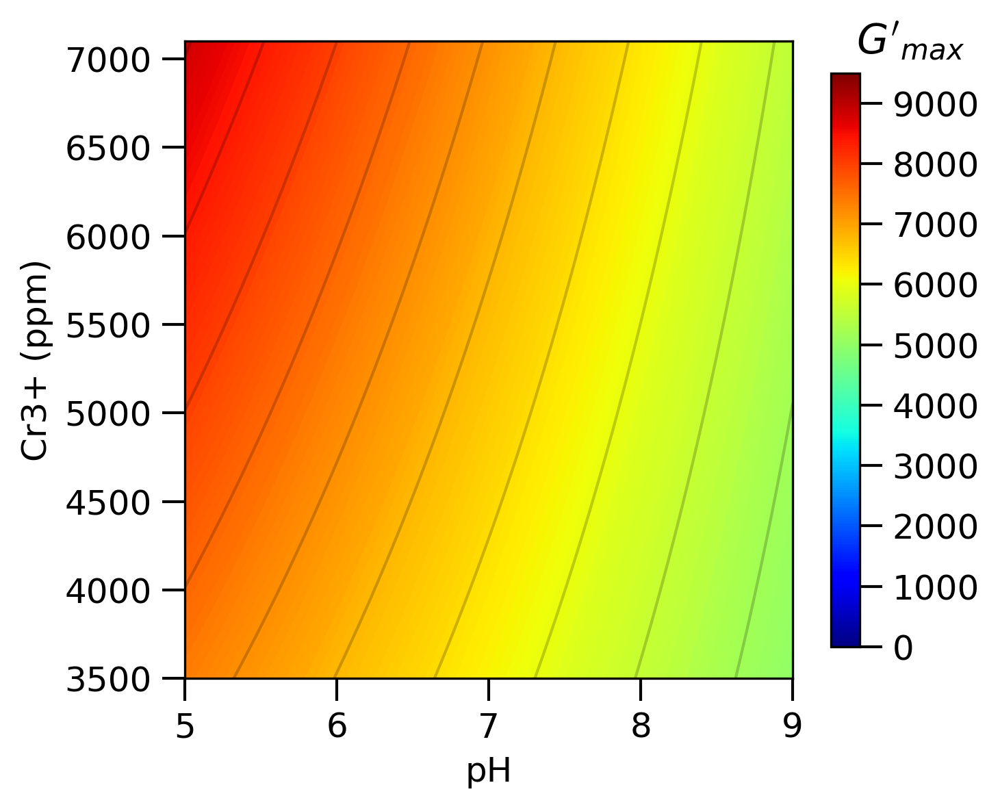

In [88]:
num = 100
coeffs = Gmax_coeffs_unadj

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_2 = -1 if coeffs[2] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
#             + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'_{max}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gmax/{factor_names["1"]}_{factor_names["5"]}.png', dpi=300)


### Visualize surfaces - 2-3

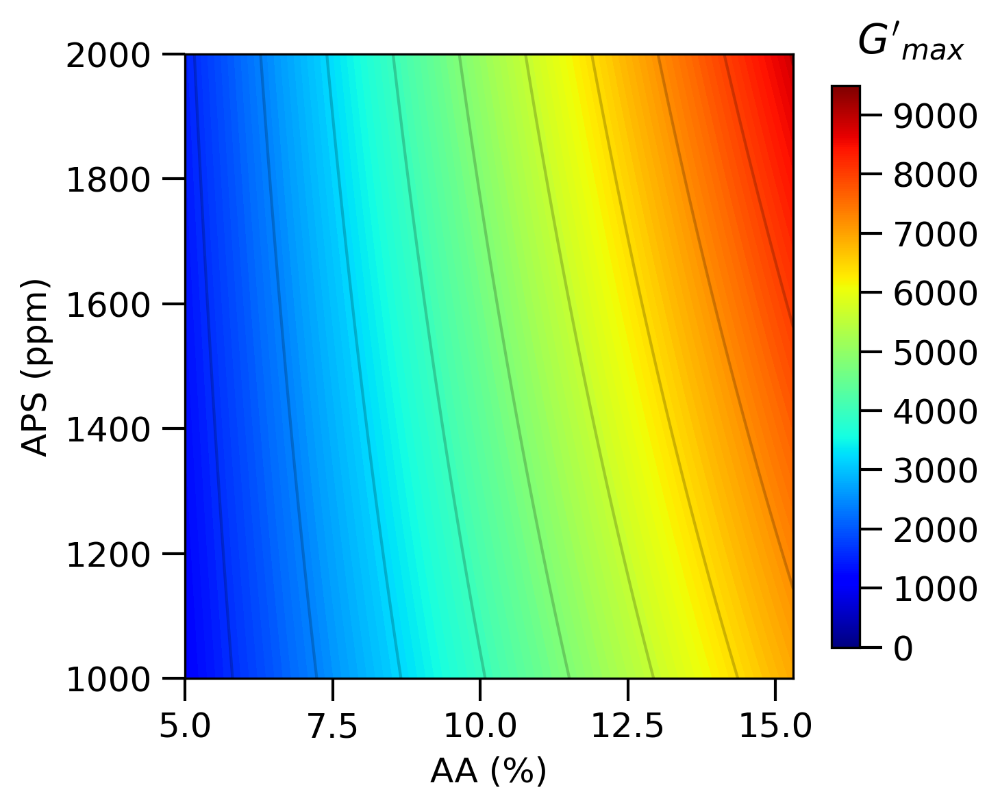

In [89]:
num = 100
coeffs = Gmax_coeffs_unadj

range_factor_2 = np.linspace(-1, 1, num=num)
range_factor_3 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1

xlabel = factor_names['2'] + factor_units['2']
ylabel = factor_names['3'] + factor_units['3']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_2 in enumerate(range_factor_2):
    for j, factor_3 in enumerate(range_factor_3):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
#             + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'_{max}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gmax/{factor_names["2"]}_{factor_names["3"]}.png', dpi=300)


### Visualize Surfaces - 2-4

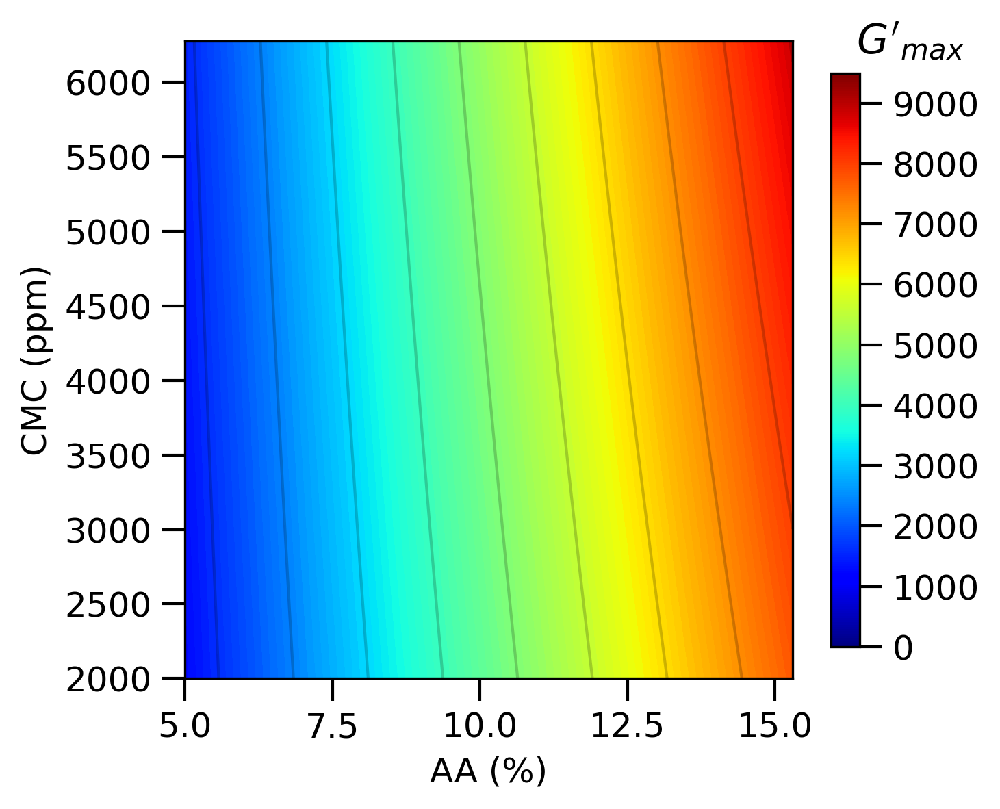

In [90]:
num = 100
coeffs = Gmax_coeffs_unadj

range_factor_2 = np.linspace(-1, 1, num=num)
range_factor_4 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1

xlabel = factor_names['2'] + factor_units['2']
ylabel = factor_names['4'] + factor_units['4']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_2 in enumerate(range_factor_2):
    for j, factor_4 in enumerate(range_factor_4):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
#             + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'_{max}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gmax/{factor_names["2"]}_{factor_names["4"]}.png', dpi=300)


### Visualize surfaces - 2-5

-1 1 1


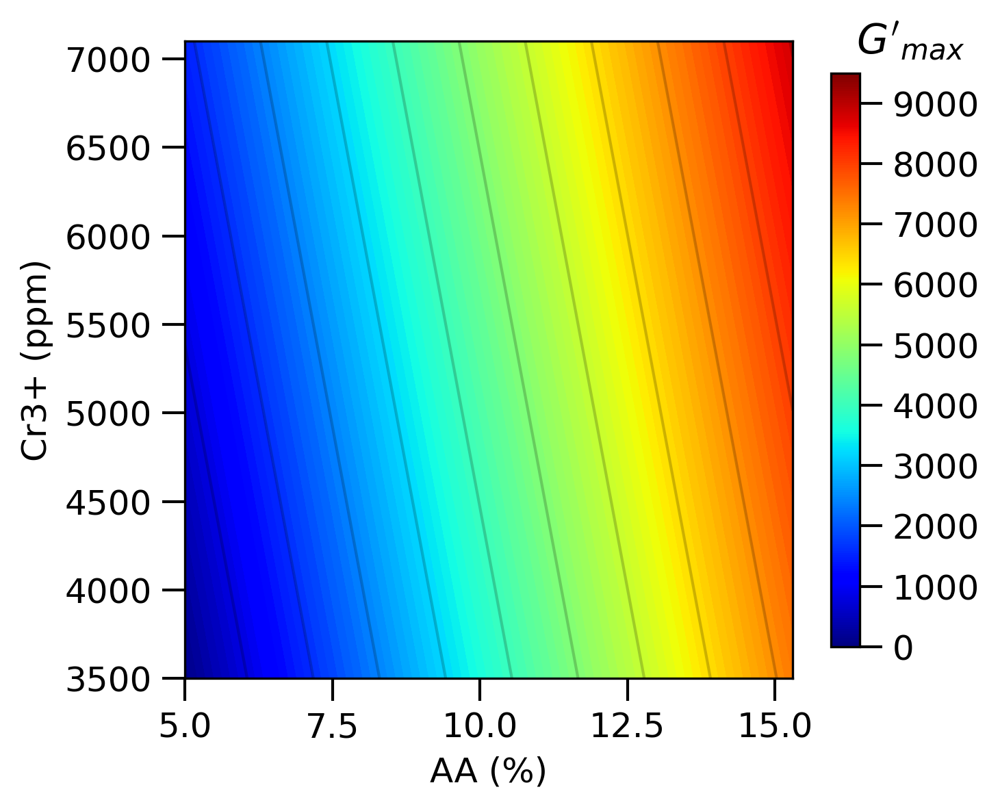

In [91]:
num = 100
coeffs = Gmax_coeffs_unadj

range_factor_2 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
print(factor_1, factor_3, factor_4)

xlabel = factor_names['2'] + factor_units['2']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_2 in enumerate(range_factor_2):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
#             + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'_{max}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gmax/{factor_names["2"]}_{factor_names["5"]}.png', dpi=300)

### Visualize surfaces - 3-4

-1 1 1


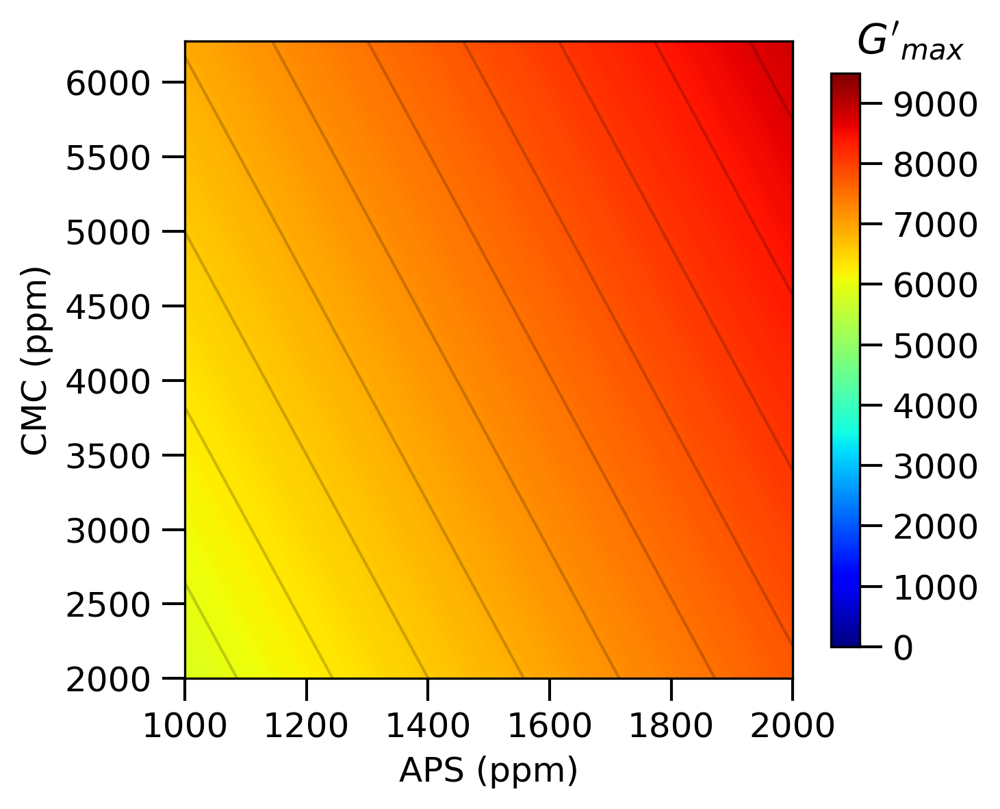

In [92]:
num = 100
coeffs = Gmax_coeffs_unadj

range_factor_3 = np.linspace(-1, 1, num=num)
range_factor_4 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_2 = -1 if coeffs[2] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1
print(factor_1, factor_2, factor_5)

xlabel = factor_names['3'] + factor_units['3']
ylabel = factor_names['4'] + factor_units['4']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_3 in enumerate(range_factor_3):
    for j, factor_4 in enumerate(range_factor_4):
        surface[i, j] = (
                    coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
#             + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'_{max}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gmax/{factor_names["3"]}_{factor_names["4"]}.png', dpi=300)


### Visualize surfaces - 3-5

-1 1 1


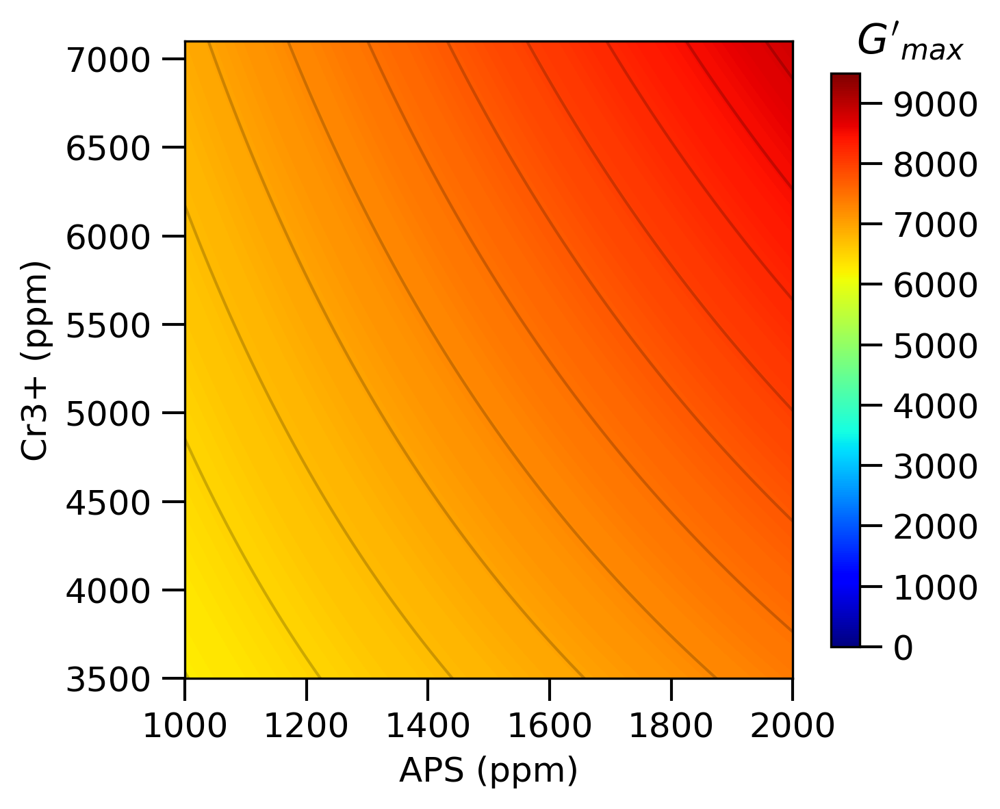

In [93]:
num = 100
coeffs = Gmax_coeffs_unadj

range_factor_3 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_2 = -1 if coeffs[2] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
print(factor_1, factor_2, factor_4)

xlabel = factor_names['3'] + factor_units['3']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_3 in enumerate(range_factor_3):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
                    coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
#             + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15])
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'_{max}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gmax/{factor_names["3"]}_{factor_names["5"]}.png', dpi=300)


### Visualize surfaces - 4-5

-1 1 1


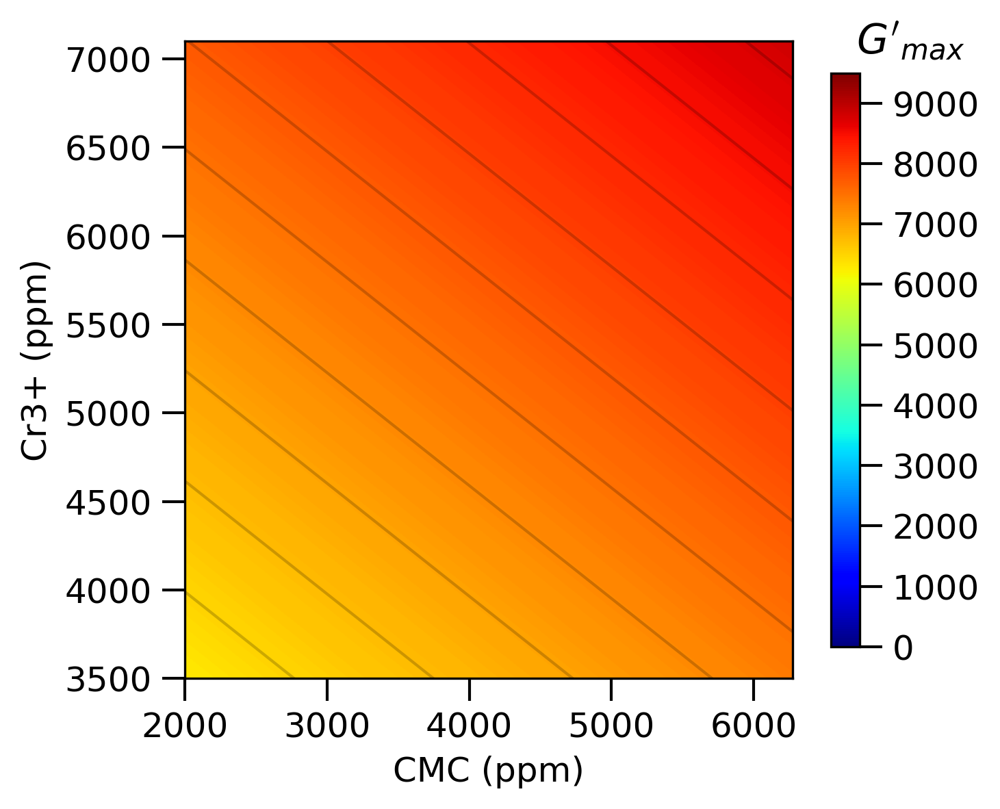

In [94]:
num = 100
coeffs = Gmax_coeffs_unadj

range_factor_4 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_2 = -1 if coeffs[2] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
print(factor_1, factor_2, factor_3)

xlabel = factor_names['4'] + factor_units['4']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_4 in enumerate(range_factor_4):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
#             + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
            + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
#             + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'_{max}$", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gmax/{factor_names["4"]}_{factor_names["5"]}.png', dpi=300)


## Gstab

### Unadjusted

In [95]:
Gstab_coeffs_unadj = regression(XX.to_numpy(), responses['Gstab'])

In [96]:
Gstab_predictions_unadj = predict(XX.to_numpy(), Gstab_coeffs_unadj)

In [97]:
anova = perform_ANOVA(
    responses["Gstab"],
    Gstab_predictions_unadj,
    responses["Gstab"][["exp17", "exp18", "exp19"]],
    Gstab_predictions_unadj[-3:],
    16,
    19,
    17,
    confidence=0.95,
)
anovas['Gstab_unadj'] = anova

In [98]:
np.set_printoptions(precision=4)
Gstab_errors_unadj = calculate_errors(XX, sigma_Gstab)

In [99]:
determine_valid_coeffs(XX.columns, Gstab_coeffs_unadj, Gstab_errors_unadj)

0: 0.662 +/- 0.017: True
1: -0.249 +/- 0.019: True
2: 0.144 +/- 0.019: True
3: -0.126 +/- 0.019: True
4: 0.046 +/- 0.019: True
5: 0.053 +/- 0.019: True
1v2: 0.060 +/- 0.019: True
1v3: 0.008 +/- 0.019: False
1v4: 0.019 +/- 0.019: True
1v5: 0.025 +/- 0.019: True
2v3: 0.017 +/- 0.019: False
2v4: -0.061 +/- 0.019: True
2v5: -0.062 +/- 0.019: True
3v4: 0.042 +/- 0.019: True
3v5: 0.040 +/- 0.019: True
4v5: 0.005 +/- 0.019: False
Valids: ['0', '1', '2', '3', '4', '5', '1v2', '1v4', '1v5', '2v4', '2v5', '3v4', '3v5']
Invalids: ['1v3', '2v3', '4v5']


### Adjusted

In [100]:
cols = ['0', '1', '2', '3', '4', '5', '1v2', '1v4', '1v5', '2v4', '2v5', '3v4', '3v5']
Gstab_coeffs_adj = regression(XX[cols].to_numpy(), responses['Gstab'])
coefficients['Gstab'] = cols

In [101]:
Gstab_predictions_adj = predict(XX[cols].to_numpy(), Gstab_coeffs_adj)

In [102]:
anova = perform_ANOVA(
    responses["Gstab"],
    Gstab_predictions_adj,
    responses["Gstab"][["exp17", "exp18", "exp19"]],
    Gstab_predictions_adj[-3:],
    13,
    19,
    17,
    confidence=0.95,
)
anovas['Gstab_adj'] = anova

In [103]:
Gstab_errors_adj = calculate_errors(XX[cols], sigma_Gstab)

In [104]:
Gstab_intervals_adj = calculate_interval(Gstab_errors_adj, 2, 0.95)

In [105]:
determine_valid_coeffs(XX[cols].columns, Gstab_coeffs_adj, Gstab_errors_adj)

0: 0.662 +/- 0.017: True
1: -0.249 +/- 0.019: True
2: 0.144 +/- 0.019: True
3: -0.126 +/- 0.019: True
4: 0.046 +/- 0.019: True
5: 0.053 +/- 0.019: True
1v2: 0.060 +/- 0.019: True
1v4: 0.019 +/- 0.019: True
1v5: 0.025 +/- 0.019: True
2v4: -0.061 +/- 0.019: True
2v5: -0.062 +/- 0.019: True
3v4: 0.042 +/- 0.019: True
3v5: 0.040 +/- 0.019: True
Valids: ['0', '1', '2', '3', '4', '5', '1v2', '1v4', '1v5', '2v4', '2v5', '3v4', '3v5']
Invalids: []


### Visualize surfaces - 1-2

Factors will have fixed values of the same sign as their exponents

In [106]:
vmin = 0.5
vmax = 1.25
cbar_ticks = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1, 1.1, 1.2]

-1 1 1


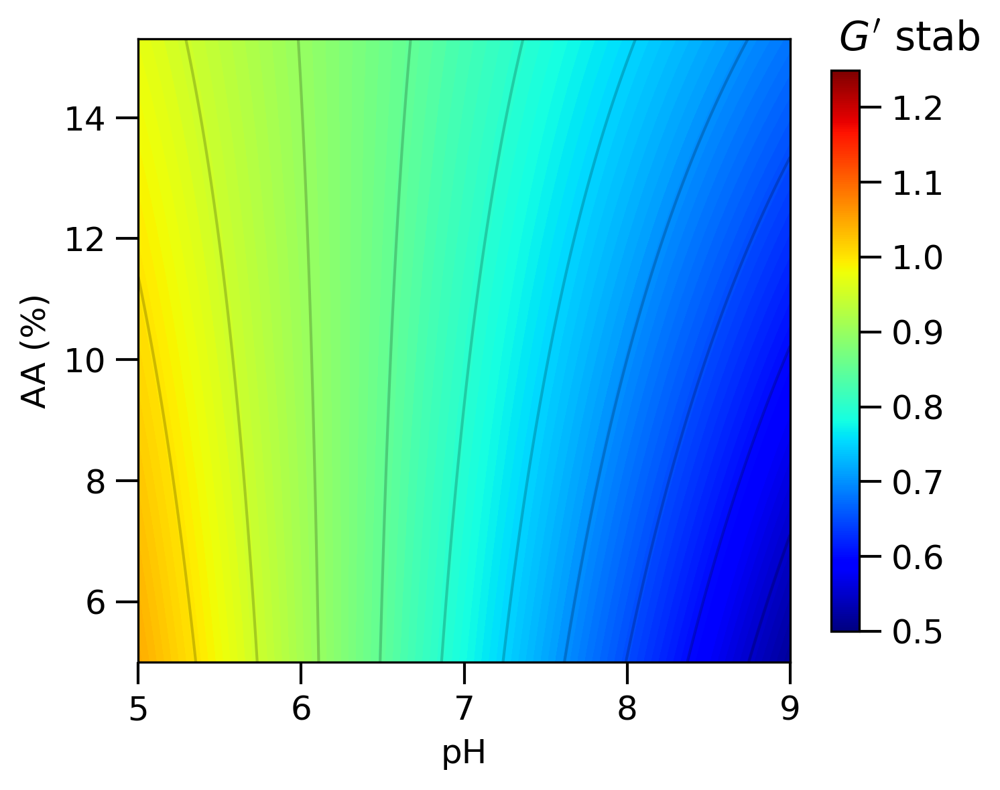

In [107]:
num = 100
coeffs = Gstab_coeffs_unadj 
factor_3 = -1 if coeffs[3] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1
print(factor_3, factor_4, factor_5)

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_2 = np.linspace(-1, 1, num=num)

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['2'] + factor_units['2']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_2 in enumerate(range_factor_2):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2, )
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)


fig.text(0.85, 0.94, r"$G'$ stab", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gstab/{factor_names["1"]}_{factor_names["2"]}.png', dpi=300)

### Visualize surfaces - 1-3

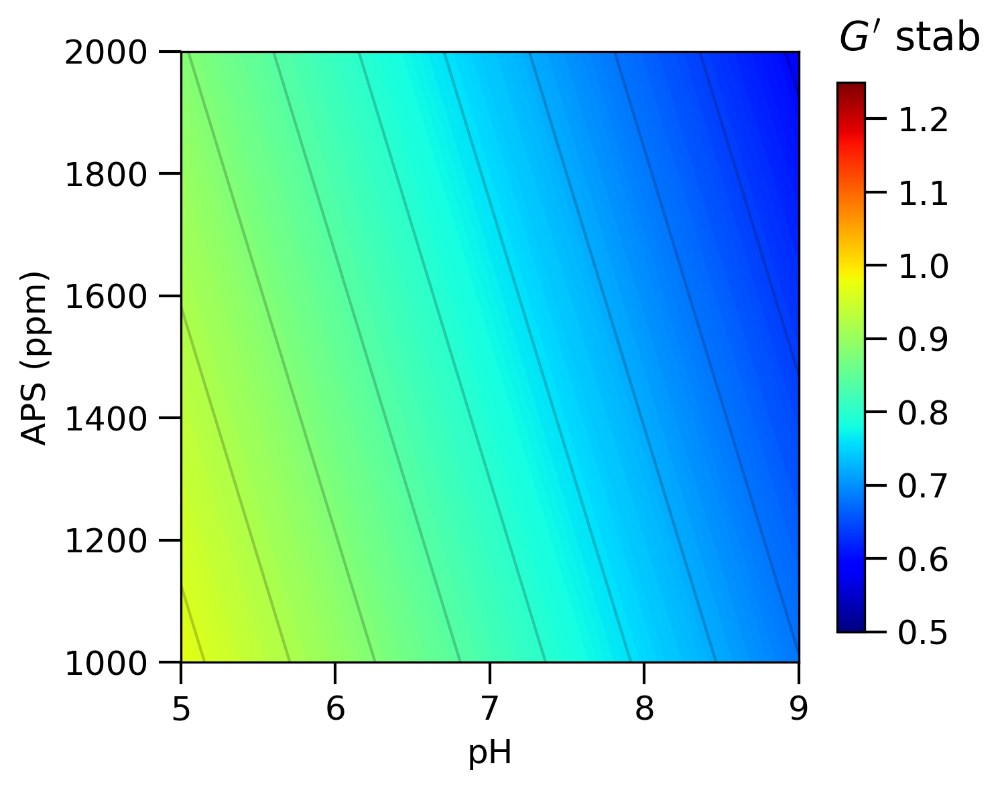

In [108]:
num = 100
coeffs = Gstab_coeffs_unadj

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_3 = np.linspace(-1, 1, num=num)

factor_2 = -1 if coeffs[2] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['3'] + factor_units['3']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_3 in enumerate(range_factor_3):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'$ stab", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gstab/{factor_names["1"]}_{factor_names["3"]}.png', dpi=300)


### 1-4

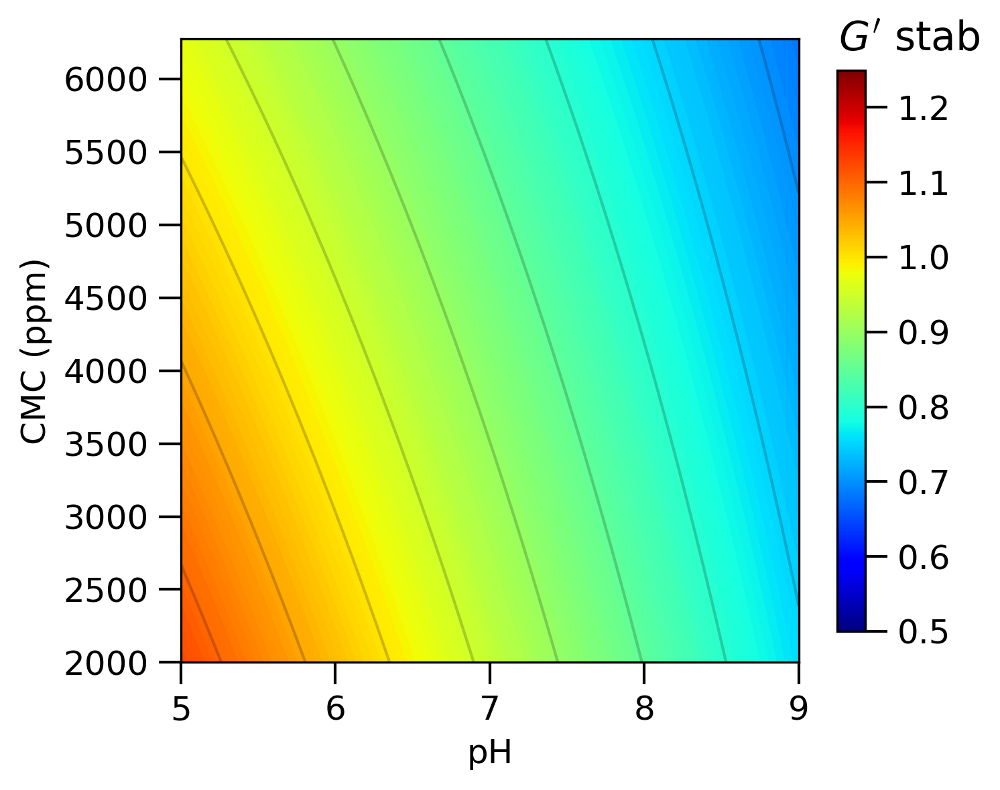

In [109]:
num = 100
coeffs = Gstab_coeffs_unadj

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_4 = np.linspace(-1, 1, num=num)

factor_2 = -1 if coeffs[2] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['4'] + factor_units['4']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_4 in enumerate(range_factor_4):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'$ stab", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gstab/{factor_names["1"]}_{factor_names["4"]}.png', dpi=300)


### Visualize Surfaces - 1-5

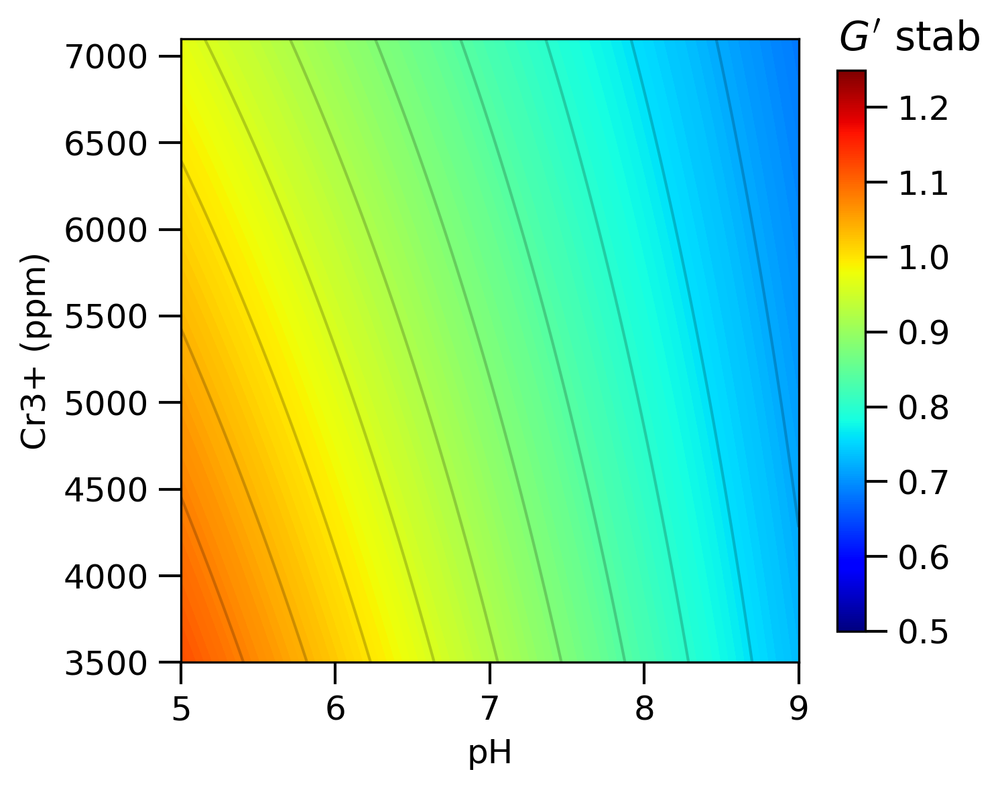

In [110]:
num = 100
coeffs = Gstab_coeffs_unadj

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_2 = -1 if coeffs[2] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'$ stab", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gstab/{factor_names["1"]}_{factor_names["5"]}.png', dpi=300)


### Visualize surfaces - 2-3

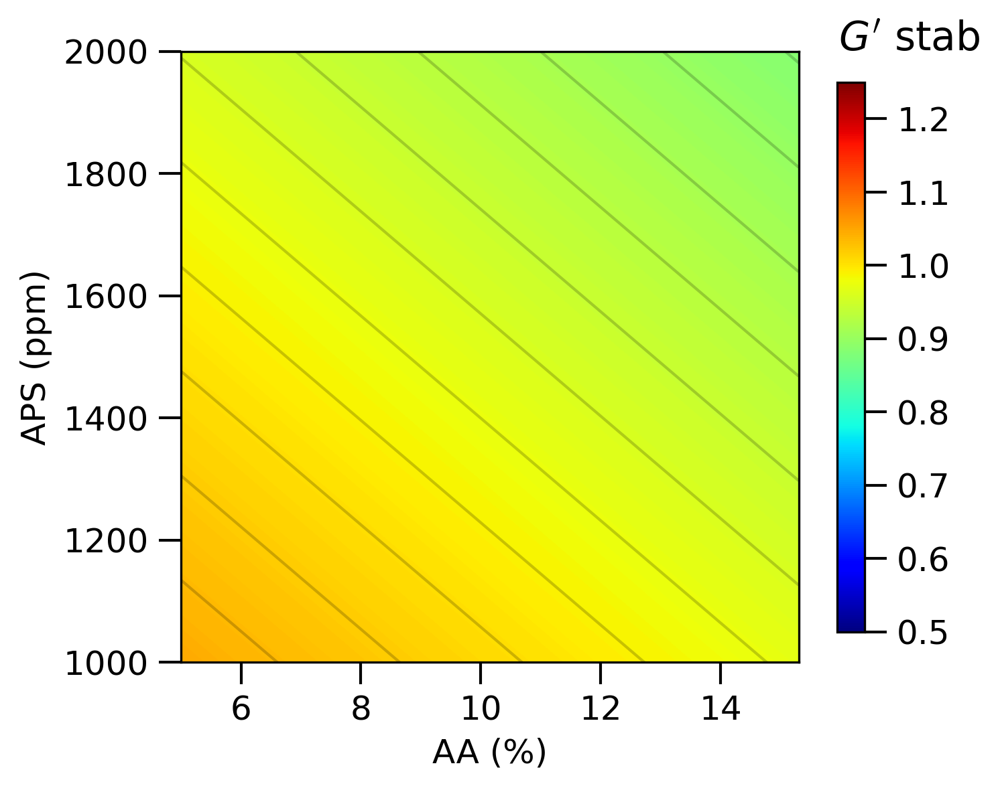

In [111]:
num = 100
coeffs = Gstab_coeffs_unadj

range_factor_2 = np.linspace(-1, 1, num=num)
range_factor_3 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1

xlabel = factor_names['2'] + factor_units['2']
ylabel = factor_names['3'] + factor_units['3']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_2 in enumerate(range_factor_2):
    for j, factor_3 in enumerate(range_factor_3):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'$ stab", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gstab/{factor_names["2"]}_{factor_names["3"]}.png', dpi=300)


### Visualize Surfaces - 2-4

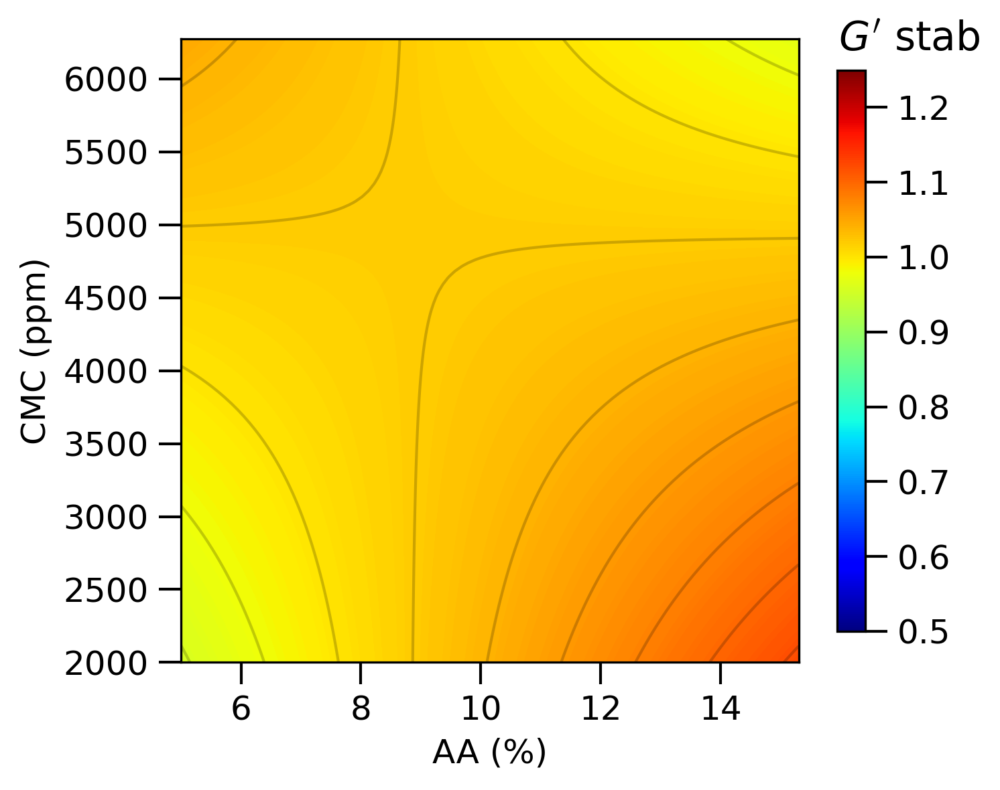

In [112]:
num = 100
coeffs = Gstab_coeffs_unadj

range_factor_2 = np.linspace(-1, 1, num=num)
range_factor_4 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1

xlabel = factor_names['2'] + factor_units['2']
ylabel = factor_names['4'] + factor_units['4']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_2 in enumerate(range_factor_2):
    for j, factor_4 in enumerate(range_factor_4):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'$ stab", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gstab/{factor_names["2"]}_{factor_names["4"]}.png', dpi=300)


### Visualize surfaces - 2-5

-1 -1 1


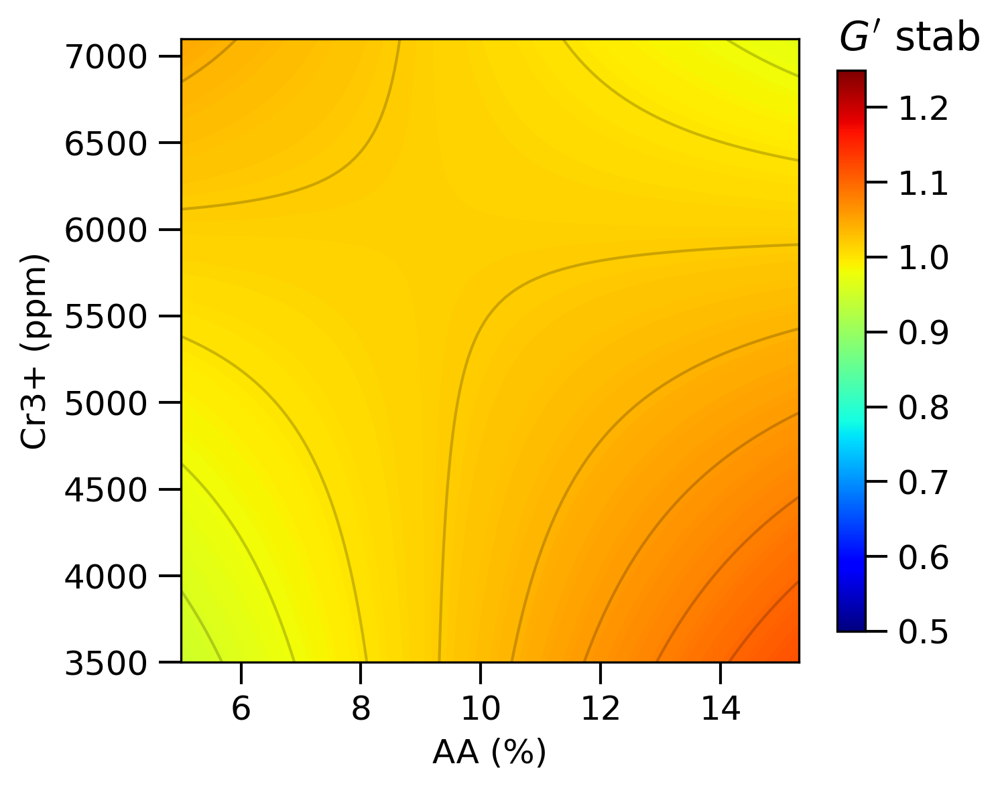

In [113]:
num = 100
coeffs = Gstab_coeffs_unadj

range_factor_2 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
print(factor_1, factor_3, factor_4)

xlabel = factor_names['2'] + factor_units['2']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_2 in enumerate(range_factor_2):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'$ stab", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gstab/{factor_names["2"]}_{factor_names["5"]}.png', dpi=300)


### Visualize surfaces - 3-4

-1 1 1


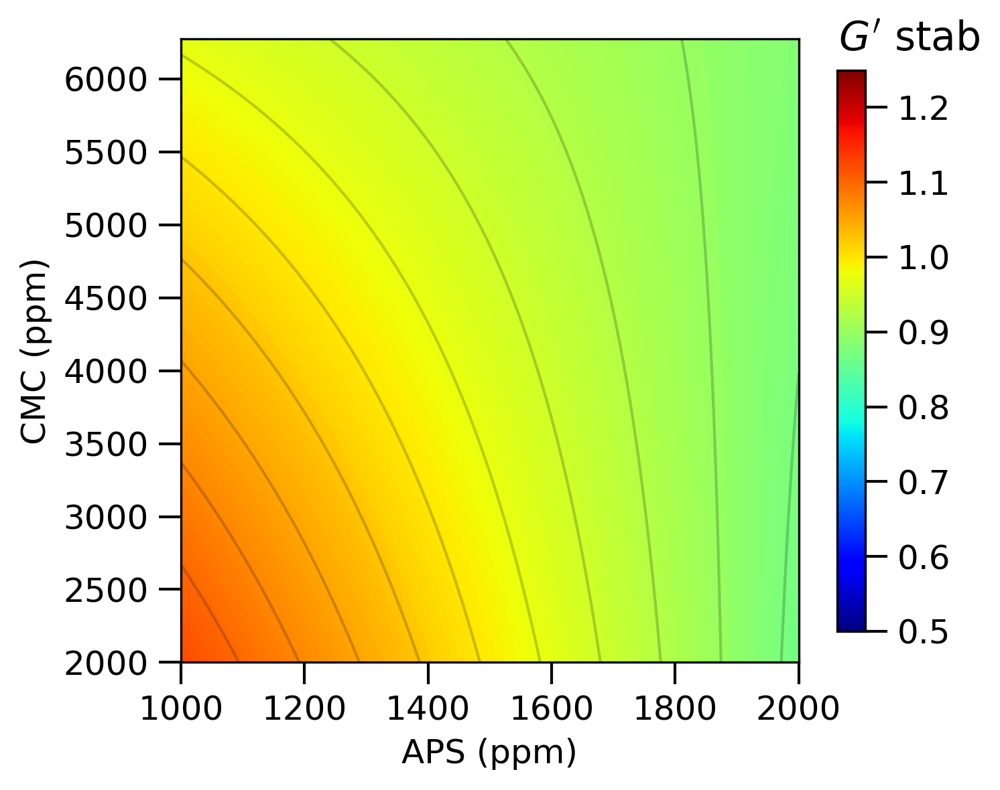

In [114]:
num = 100
coeffs = Gstab_coeffs_unadj

range_factor_3 = np.linspace(-1, 1, num=num)
range_factor_4 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_2 = -1 if coeffs[2] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1
print(factor_1, factor_2, factor_5)

xlabel = factor_names['3'] + factor_units['3']
ylabel = factor_names['4'] + factor_units['4']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_3 in enumerate(range_factor_3):
    for j, factor_4 in enumerate(range_factor_4):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'$ stab", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gstab/{factor_names["3"]}_{factor_names["4"]}.png', dpi=300)



### Visualize surfaces - 3-5

-1 1 1


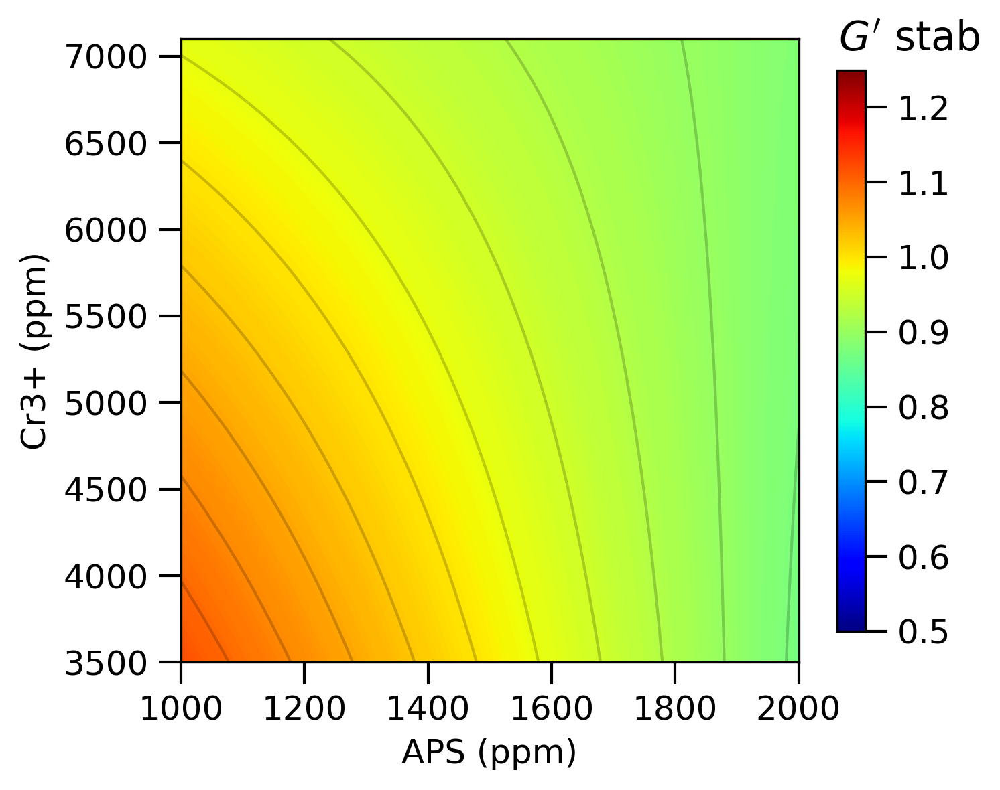

In [115]:
num = 100
coeffs = Gstab_coeffs_unadj

range_factor_3 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_2 = -1 if coeffs[2] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
print(factor_1, factor_2, factor_4)

xlabel = factor_names['3'] + factor_units['3']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_3 in enumerate(range_factor_3):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'$ stab", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gstab/{factor_names["3"]}_{factor_names["5"]}.png', dpi=300)



### Visualize surfaces - 4-5

-1 1 -1


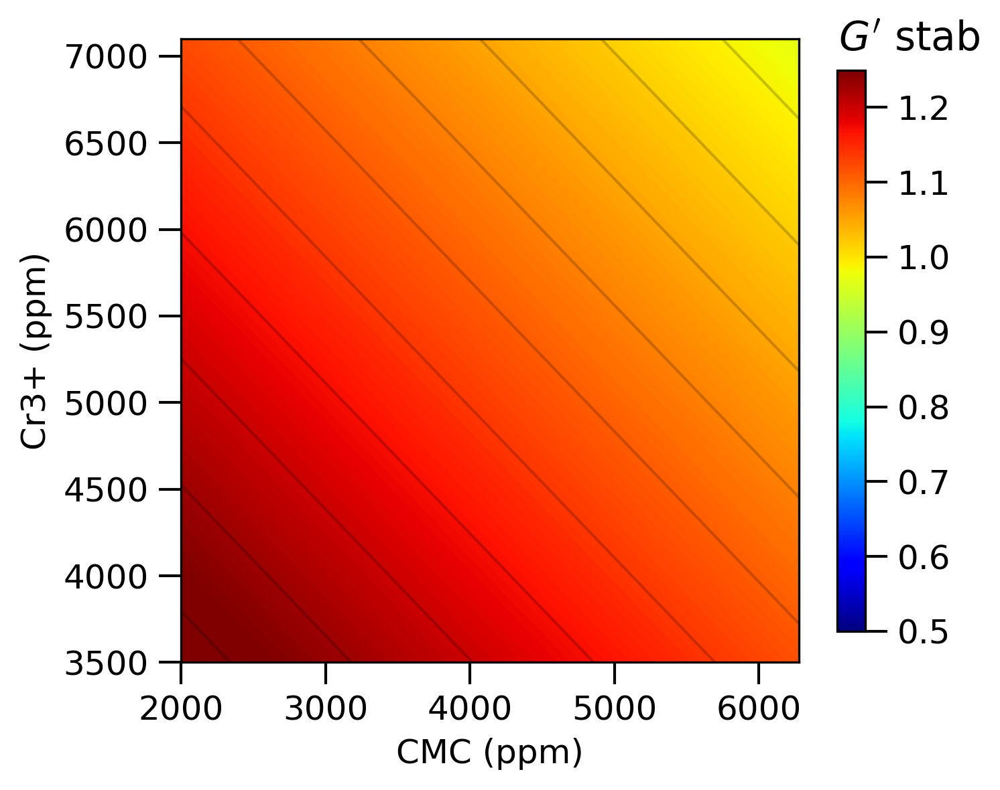

In [116]:
num = 100
coeffs = Gstab_coeffs_unadj

range_factor_4 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_2 = -1 if coeffs[2] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
print(factor_1, factor_2, factor_3)

xlabel = factor_names['4'] + factor_units['4']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_4 in enumerate(range_factor_4):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
#             + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
            + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
            + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
#             + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$G'$ stab", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/gstab/{factor_names["4"]}_{factor_names["5"]}.png', dpi=300)



## Tg

### Unadjusted

In [117]:
tNMR_coeffs_unadj = regression(XX.to_numpy(), responses['tNMR'])

In [118]:
tNMR_predictions_unadj = predict(XX.to_numpy(), tNMR_coeffs_unadj)

In [119]:
anova = perform_ANOVA(
    responses["tNMR"],
    tNMR_predictions_unadj,
    responses["tNMR"][["exp17", "exp18", "exp19"]],
    tNMR_predictions_unadj[-3:],
    16,
    19,
    17,
    confidence=0.95,
)
anovas['tNMR_unadj'] = anova

In [120]:
np.set_printoptions(precision=4)
tNMR_errors_unadj = calculate_errors(XX, sigma_tNMR)

In [121]:
determine_valid_coeffs(XX.columns, tNMR_coeffs_unadj, tNMR_errors_unadj)

0: 15.705 +/- 0.775: True
1: -5.609 +/- 0.844: True
2: 2.543 +/- 0.844: True
3: -1.214 +/- 0.844: True
4: 0.686 +/- 0.844: False
5: -0.599 +/- 0.844: False
1v2: -1.095 +/- 0.844: True
1v3: 0.945 +/- 0.844: True
1v4: 0.924 +/- 0.844: True
1v5: 0.684 +/- 0.844: False
2v3: 0.155 +/- 0.844: False
2v4: 1.318 +/- 0.844: True
2v5: -0.501 +/- 0.844: False
3v4: 2.670 +/- 0.844: True
3v5: 1.043 +/- 0.844: True
4v5: -1.124 +/- 0.844: True
Valids: ['0', '1', '2', '3', '4', '5', '1v2', '1v3', '1v4', '2v4', '3v4', '3v5', '4v5']
Invalids: ['1v5', '2v3', '2v5']


### Adjusted

In [122]:
cols = ['0', '1', '2', '3', '4', '5', '1v2', '1v3', '1v4', '2v4', '3v4', '3v5', '4v5']
tNMR_coeffs_adj = regression(XX[cols].to_numpy(), responses['tNMR'])
coefficients['tNMR'] = cols

In [123]:
tNMR_predictions_adj = predict(XX[cols].to_numpy(), tNMR_coeffs_adj)

In [124]:
anova = perform_ANOVA(
    responses["tNMR"],
    tNMR_predictions_adj,
    responses["tNMR"][["exp17", "exp18", "exp19"]],
    tNMR_predictions_adj[-3:],
    13,
    19,
    17,
    confidence=0.95,
)
anovas['tNMR_adj'] = anova

In [125]:
tNMR_errors_adj = calculate_errors(XX[cols], sigma_tNMR)

In [126]:
tNMR_intervals_adj = calculate_interval(tNMR_errors_adj, 2, 0.95)

In [127]:
determine_valid_coeffs(XX[cols].columns, tNMR_coeffs_adj, tNMR_errors_adj)

0: 15.705 +/- 0.775: True
1: -5.609 +/- 0.844: True
2: 2.543 +/- 0.844: True
3: -1.214 +/- 0.844: True
4: 0.686 +/- 0.844: False
5: -0.599 +/- 0.844: False
1v2: -1.095 +/- 0.844: True
1v3: 0.945 +/- 0.844: True
1v4: 0.924 +/- 0.844: True
2v4: 1.318 +/- 0.844: True
3v4: 2.670 +/- 0.844: True
3v5: 1.043 +/- 0.844: True
4v5: -1.124 +/- 0.844: True
Valids: ['0', '1', '2', '3', '4', '5', '1v2', '1v3', '1v4', '2v4', '3v4', '3v5', '4v5']
Invalids: []


### Visualize surfaces - 1-2

Factors will have fixed values of the same sign as their exponents

In [128]:
vmax = 32
vmin = 5
cbar_ticks = [5, 10, 15, 20, 25, 30]

-1 1 -1


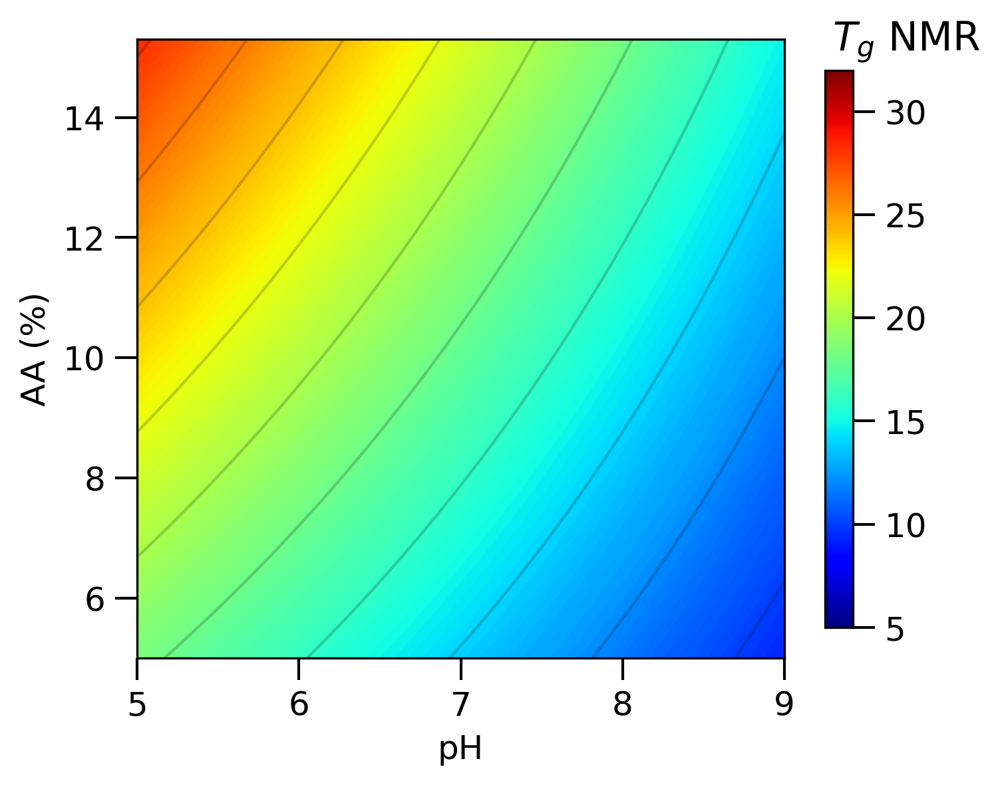

In [129]:
num = 100
coeffs = tNMR_coeffs_unadj 
factor_3 = -1 if coeffs[3] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1
print(factor_3, factor_4, factor_5)

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_2 = np.linspace(-1, 1, num=num)

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['2'] + factor_units['2']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_2 in enumerate(range_factor_2):
        surface[i, j] = (
            coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
            + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2, )
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)


fig.text(0.85, 0.94, r"$T_g$ NMR", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/tg/{factor_names["1"]}_{factor_names["2"]}.png', dpi=300)

### Visualize surfaces - 1-3

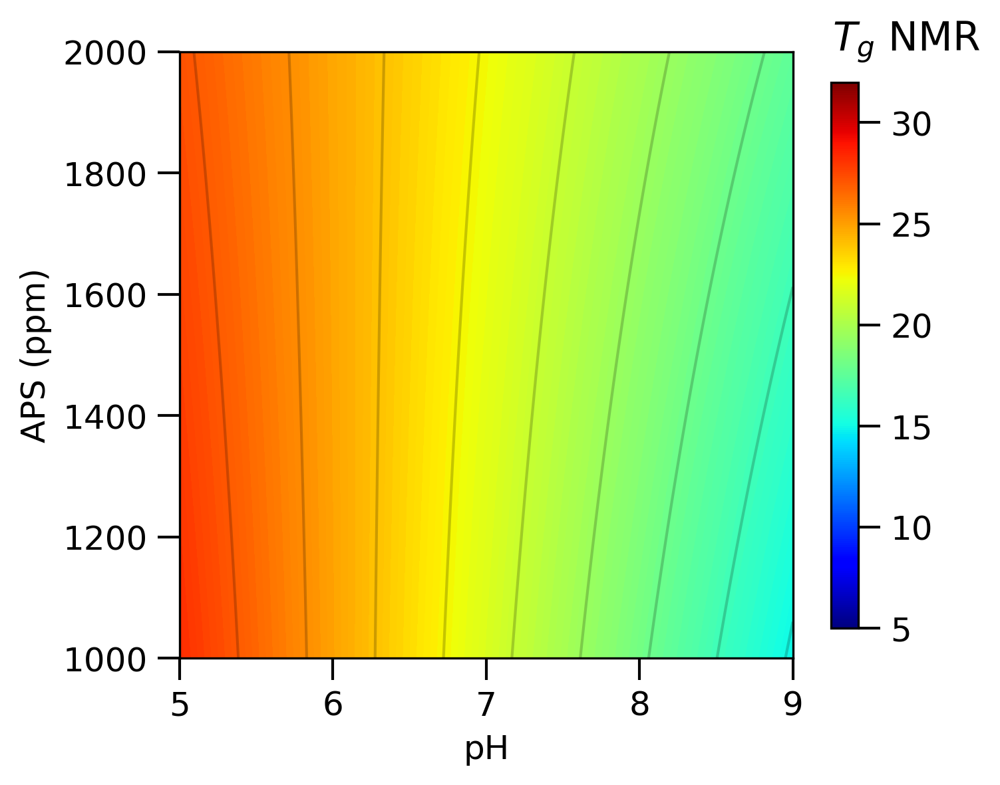

In [130]:
num = 100
coeffs = tNMR_coeffs_unadj

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_3 = np.linspace(-1, 1, num=num)

factor_2 = -1 if coeffs[2] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['3'] + factor_units['3']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_3 in enumerate(range_factor_3):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
            + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$T_g$ NMR", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/tg/{factor_names["1"]}_{factor_names["3"]}.png', dpi=300)


### 1-4

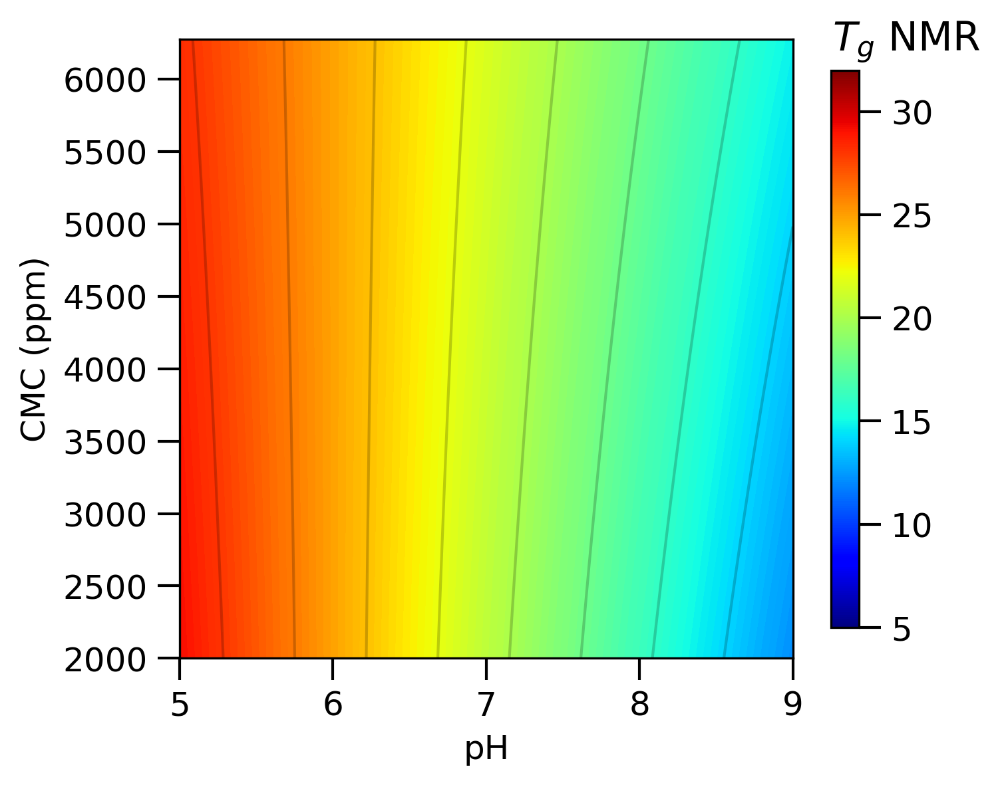

In [131]:
num = 100
coeffs = tNMR_coeffs_unadj

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_4 = np.linspace(-1, 1, num=num)

factor_2 = -1 if coeffs[2] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['4'] + factor_units['4']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_4 in enumerate(range_factor_4):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
            + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$T_g$ NMR", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/tg/{factor_names["1"]}_{factor_names["4"]}.png', dpi=300)


### Visualize Surfaces - 1-5

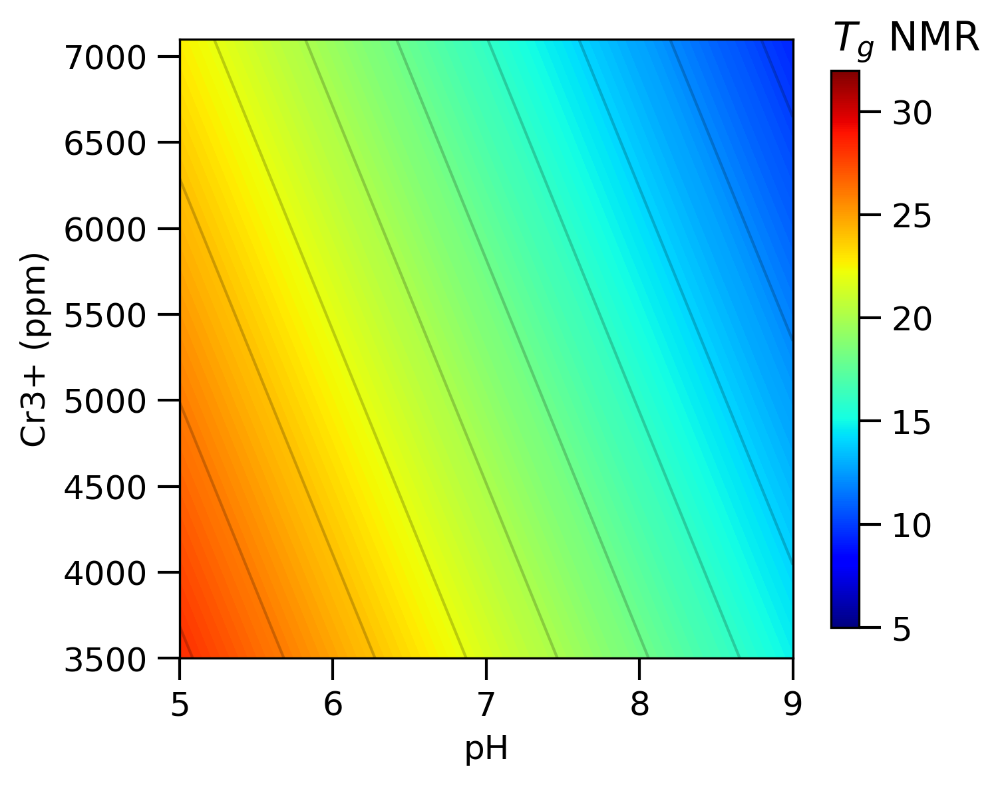

In [132]:
num = 100
coeffs = tNMR_coeffs_unadj

range_factor_1 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_2 = -1 if coeffs[2] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1

xlabel = factor_names['1'] + factor_units['1']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_1 in enumerate(range_factor_1):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
            + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['1'], factor_levels_max['1'], factor_1)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$T_g$ NMR", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/tg/{factor_names["1"]}_{factor_names["5"]}.png', dpi=300)


### Visualize surfaces - 2-3

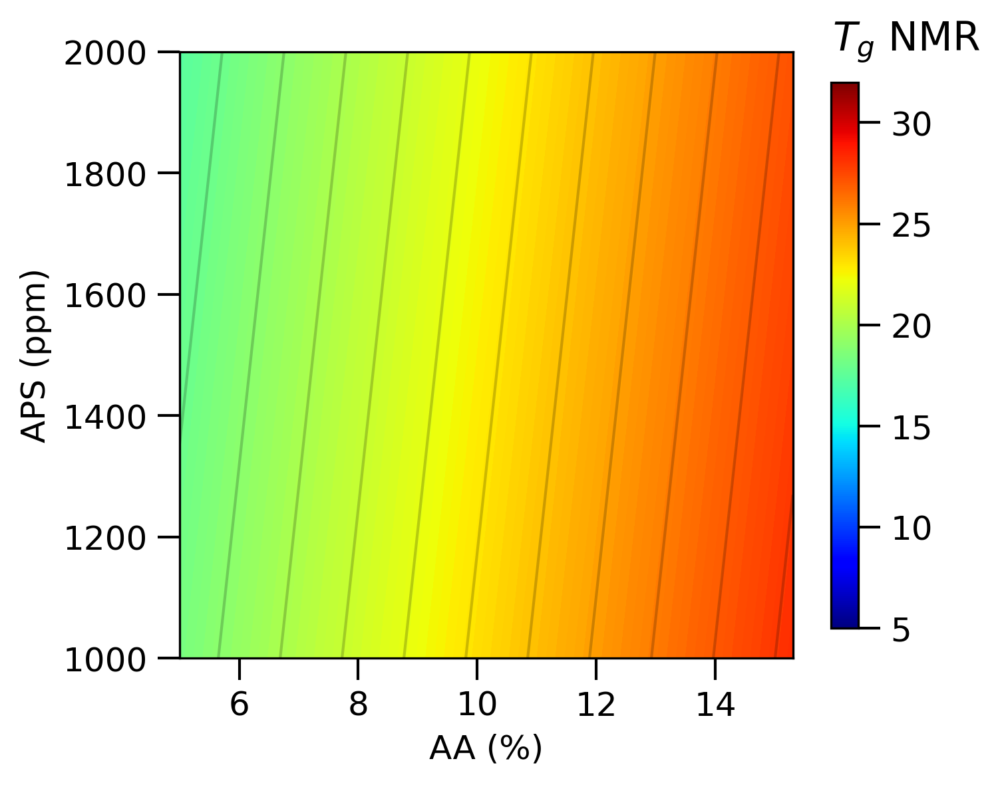

In [133]:
num = 100
coeffs = tNMR_coeffs_unadj

range_factor_2 = np.linspace(-1, 1, num=num)
range_factor_3 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1

xlabel = factor_names['2'] + factor_units['2']
ylabel = factor_names['3'] + factor_units['3']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_2 in enumerate(range_factor_2):
    for j, factor_3 in enumerate(range_factor_3):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
            + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$T_g$ NMR", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/tg/{factor_names["2"]}_{factor_names["3"]}.png', dpi=300)


### Visualize Surfaces - 2-4

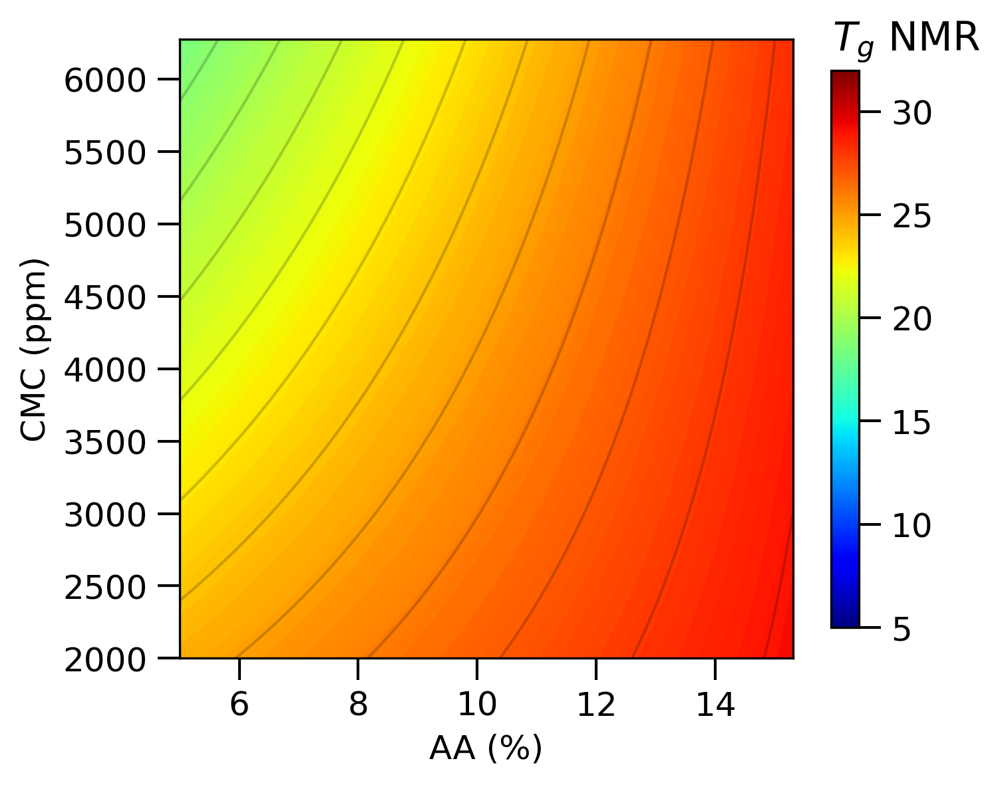

In [134]:
num = 100
coeffs = tNMR_coeffs_unadj

range_factor_2 = np.linspace(-1, 1, num=num)
range_factor_4 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1

xlabel = factor_names['2'] + factor_units['2']
ylabel = factor_names['4'] + factor_units['4']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_2 in enumerate(range_factor_2):
    for j, factor_4 in enumerate(range_factor_4):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
            + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$T_g$ NMR", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/tg/{factor_names["2"]}_{factor_names["4"]}.png', dpi=300)


### Visualize surfaces - 2-5

-1 -1 1


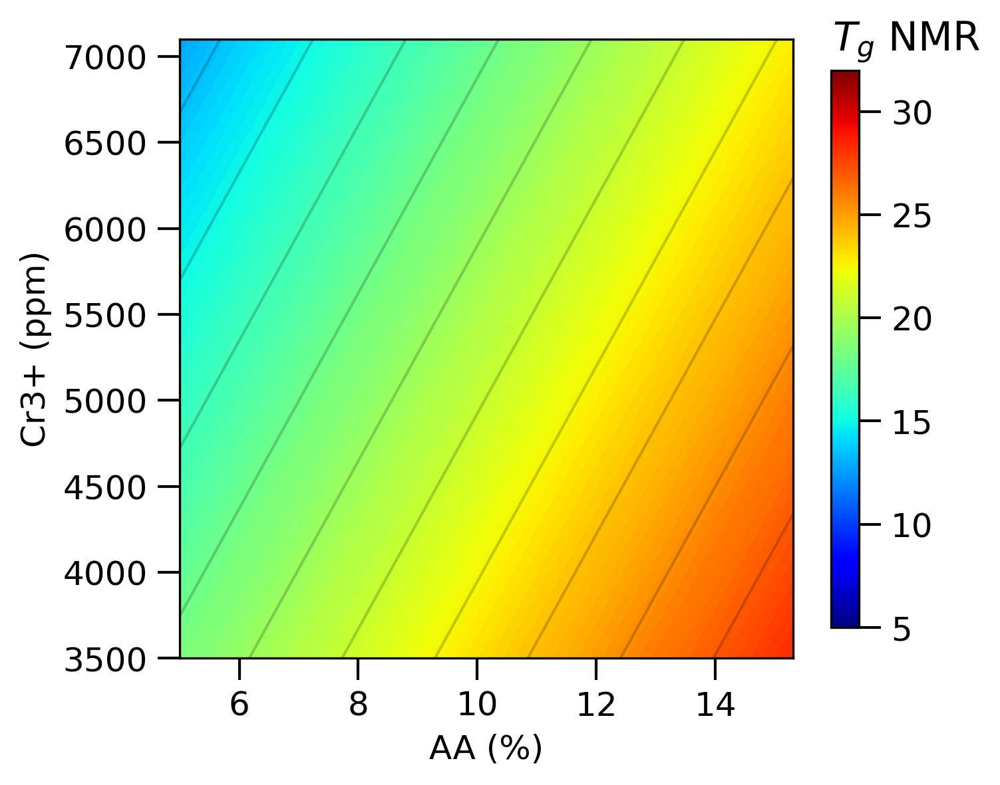

In [135]:
num = 100
coeffs = tNMR_coeffs_unadj

range_factor_2 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
print(factor_1, factor_3, factor_4)

xlabel = factor_names['2'] + factor_units['2']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_2 in enumerate(range_factor_2):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
            + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['2'], factor_levels_max['2'], factor_2)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$T_g$ NMR", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/tg/{factor_names["2"]}_{factor_names["5"]}.png', dpi=300)


### Visualize surfaces - 3-4

-1 1 -1


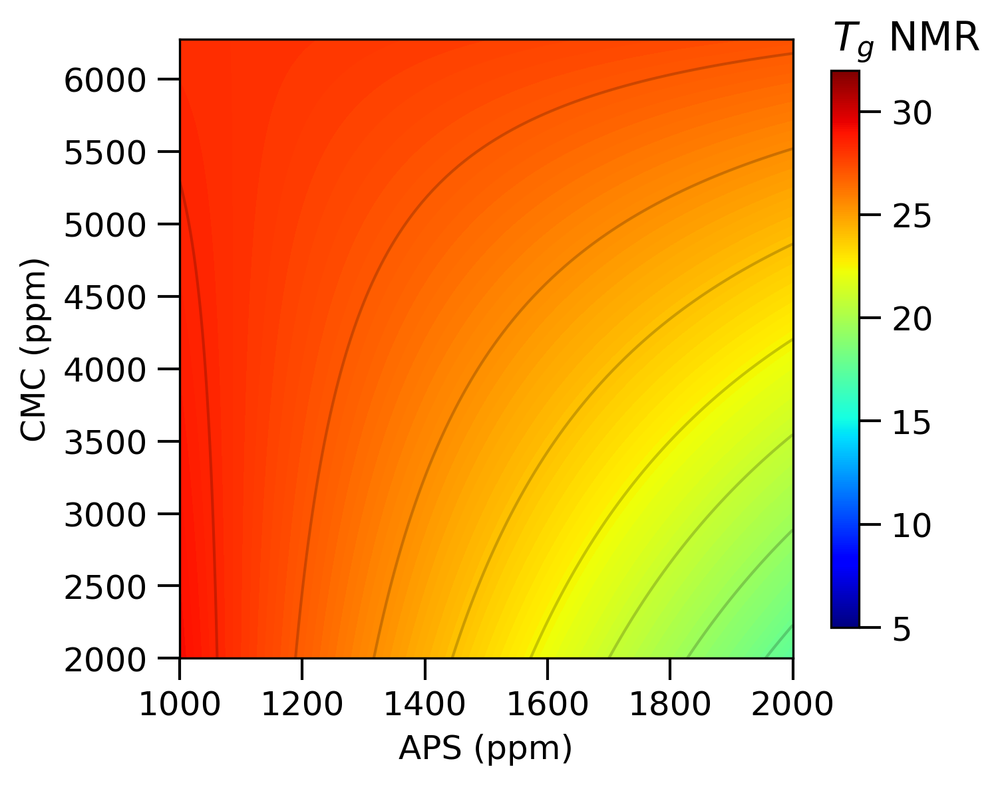

In [136]:
num = 100
coeffs = tNMR_coeffs_unadj

range_factor_3 = np.linspace(-1, 1, num=num)
range_factor_4 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_2 = -1 if coeffs[2] < 0 else 1
factor_5 = -1 if coeffs[5] < 0 else 1
print(factor_1, factor_2, factor_5)

xlabel = factor_names['3'] + factor_units['3']
ylabel = factor_names['4'] + factor_units['4']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_3 in enumerate(range_factor_3):
    for j, factor_4 in enumerate(range_factor_4):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
            + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$T_g$ NMR", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/tg/{factor_names["3"]}_{factor_names["4"]}.png', dpi=300)



### Visualize surfaces - 3-5

-1 1 1


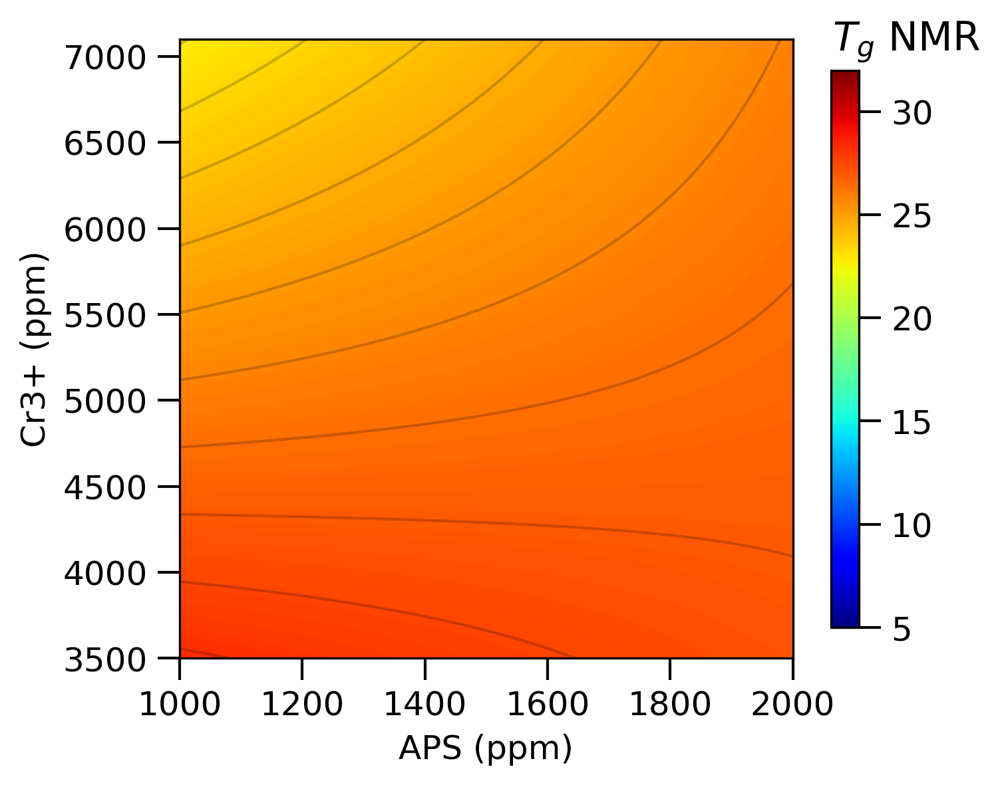

In [137]:
num = 100
coeffs = tNMR_coeffs_unadj

range_factor_3 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_2 = -1 if coeffs[2] < 0 else 1
factor_4 = -1 if coeffs[4] < 0 else 1
print(factor_1, factor_2, factor_4)

xlabel = factor_names['3'] + factor_units['3']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_3 in enumerate(range_factor_3):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
            + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['3'], factor_levels_max['3'], factor_3)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$T_g$ NMR", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/tg/{factor_names["3"]}_{factor_names["5"]}.png', dpi=300)



### Visualize surfaces - 4-5

-1 1 -1


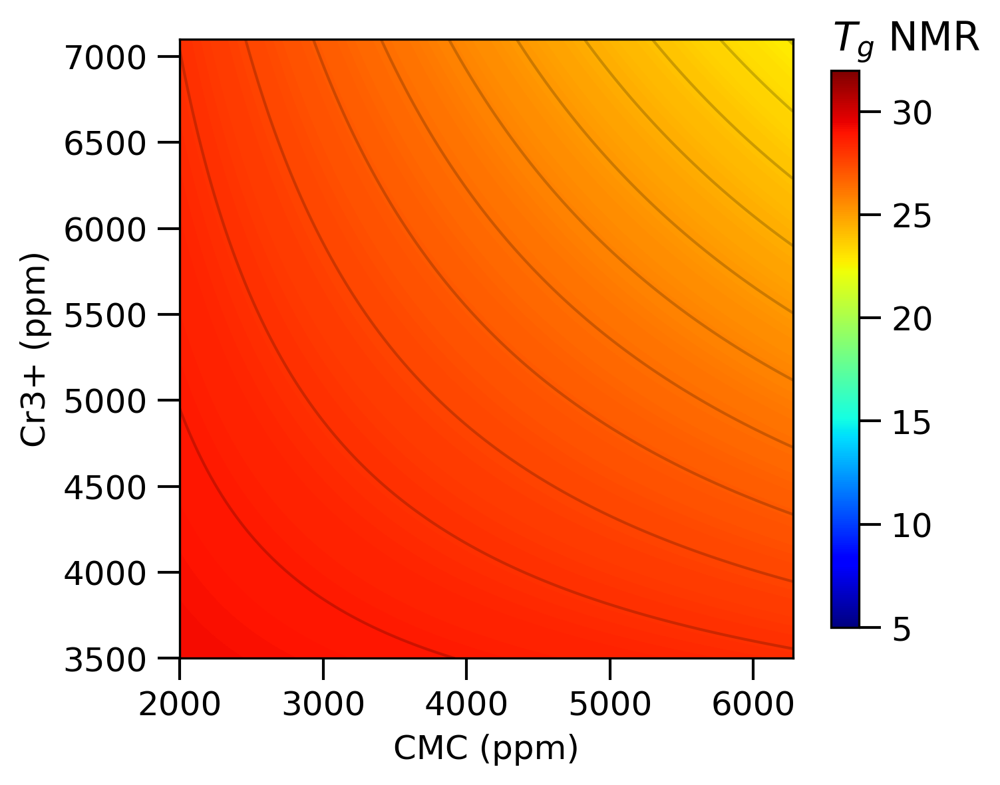

In [138]:
num = 100
coeffs = tNMR_coeffs_unadj

range_factor_4 = np.linspace(-1, 1, num=num)
range_factor_5 = np.linspace(-1, 1, num=num)

factor_1 = -1 if coeffs[1] < 0 else 1
factor_2 = -1 if coeffs[2] < 0 else 1
factor_3 = -1 if coeffs[3] < 0 else 1
print(factor_1, factor_2, factor_3)

xlabel = factor_names['4'] + factor_units['4']
ylabel = factor_names['5'] + factor_units['5']

surface = np.zeros((num, num))
vals_X = np.zeros_like(surface)
vals_Y = np.zeros_like(surface)

for i, factor_4 in enumerate(range_factor_4):
    for j, factor_5 in enumerate(range_factor_5):
        surface[i, j] = (
                        coeffs[0]
            + factor_1 * coeffs[1]
            + factor_2 * coeffs[2]
            + factor_3 * coeffs[3]
            + factor_4 * coeffs[4]
            + factor_5 * coeffs[5]
            + factor_1 * factor_2 * coeffs[6]
            + factor_1 * factor_3 * coeffs[7]
            + factor_1 * factor_4 * coeffs[8]
#             + factor_1 * factor_5 * coeffs[9]
#             + factor_2 * factor_3 * coeffs[10]
            + factor_2 * factor_4 * coeffs[11]
#             + factor_2 * factor_5 * coeffs[12]
            + factor_3 * factor_4 * coeffs[13]
            + factor_3 * factor_5 * coeffs[14]
            + factor_4 * factor_5 * coeffs[15]
        )
        vals_X[i, j] = convert_codified_to_uncodified(factor_levels_min['4'], factor_levels_max['4'], factor_4)
        vals_Y[i, j] = convert_codified_to_uncodified(factor_levels_min['5'], factor_levels_max['5'], factor_5)
        

fig = plt.figure(figsize=(5, 4))
contour = plt.contourf(vals_X, vals_Y, surface, levels=100, cmap='jet', vmin=vmin, vmax=vmax)
plt.contour(vals_X, vals_Y, surface, levels=10, colors='k', alpha=0.2)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
# cbar = plt.colorbar(contour, shrink=0.9, )
sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, shrink=0.9, ticks=cbar_ticks)

fig.text(0.85, 0.94, r"$T_g$ NMR", fontsize='large')
plt.tight_layout()
plt.savefig(f'./Surfaces/tg/{factor_names["4"]}_{factor_names["5"]}.png', dpi=300)



# Final comparisons

## Comparing all ANOVAs

In [139]:
pd.DataFrame(anovas, index=anovas['khills_adj']._fields)

,khills_unadj,khills_adj,Gplateau_unadj,Gplateau_adj,Gmax_unadj,Gmax_adj,Gstab_unadj,Gstab_adj,tNMR_unadj,tNMR_adj
SqR,876.85823,859.892777,116479593.344034,116030800.078197,127642486.617284,127011464.19335,1.913345,1.907396,882.176858,870.281086
Sqr,36.273296,53.238749,5928690.742235,6377484.008071,3931353.31276,4562375.736694,0.044464,0.050413,26.303417,38.199189
Sqfaj,11.205225,11.205225,4782039.554945,4782039.554945,2564881.476684,2564881.476684,0.027844,0.027844,2.932,2.932
Sqep,22.967092,22.967092,250018.770738,250018.770738,885556.559198,885556.559198,0.011399,0.011399,22.821667,22.821667
SqT,913.131527,913.131527,122408284.086269,122408284.086269,131573839.930044,131573839.930044,1.957809,1.957809,908.480275,908.480275
R2,0.960276,0.941697,0.951566,0.9479,0.970121,0.965325,0.977289,0.97425,0.971047,0.957953
R2max,0.974848,0.974848,0.997958,0.997958,0.99327,0.99327,0.994178,0.994178,0.974879,0.974879
num_parameters_p,16,12,16,10,16,11,16,13,16,13
num_observations_n,19,19,19,19,19,19,19,19,19,19
num_levels_m,17,17,17,17,17,17,17,17,17,17


In [140]:
pd.DataFrame({key:val for key, val in anovas.items() if not 'unadj' in key}, index=anovas['khills_adj']._fields)

,khills_adj,Gplateau_adj,Gmax_adj,Gstab_adj,tNMR_adj
SqR,859.892777,116030800.078197,127011464.19335,1.907396,870.281086
Sqr,53.238749,6377484.008071,4562375.736694,0.050413,38.199189
Sqfaj,11.205225,4782039.554945,2564881.476684,0.027844,2.932
Sqep,22.967092,250018.770738,885556.559198,0.011399,22.821667
SqT,913.131527,122408284.086269,131573839.930044,1.957809,908.480275
R2,0.941697,0.9479,0.965325,0.97425,0.957953
R2max,0.974848,0.997958,0.99327,0.994178,0.974879
num_parameters_p,12,10,11,13,13
num_observations_n,19,19,19,19,19
num_levels_m,17,17,17,17,17


In [141]:
pd.DataFrame({key:val for key, val in anovas.items() if 'unadj' in key}, index=anovas['khills_adj']._fields)

,khills_unadj,Gplateau_unadj,Gmax_unadj,Gstab_unadj,tNMR_unadj
SqR,876.85823,116479593.344034,127642486.617284,1.913345,882.176858
Sqr,36.273296,5928690.742235,3931353.31276,0.044464,26.303417
Sqfaj,11.205225,4782039.554945,2564881.476684,0.027844,2.932
Sqep,22.967092,250018.770738,885556.559198,0.011399,22.821667
SqT,913.131527,122408284.086269,131573839.930044,1.957809,908.480275
R2,0.960276,0.951566,0.970121,0.977289,0.971047
R2max,0.974848,0.997958,0.99327,0.994178,0.974879
num_parameters_p,16,16,16,16,16
num_observations_n,19,19,19,19,19
num_levels_m,17,17,17,17,17


## Comparing all regressions

In [142]:
coefficients

{'khills': ['0',
  '1',
  '2',
  '3',
  '4',
  '5',
  '1v2',
  '1v5',
  '2v3',
  '2v5',
  '3v4',
  '4v5'],
 'Gplateau': ['0', '1', '2', '3', '4', '5', '1v2', '1v4', '3v5'],
 'Gmax': ['0', '1', '2', '3', '4', '5', '1v2', '1v5', '2v3', '2v4', '3v5'],
 'Gstab': ['0',
  '1',
  '2',
  '3',
  '4',
  '5',
  '1v2',
  '1v4',
  '1v5',
  '2v4',
  '2v5',
  '3v4',
  '3v5'],
 'tNMR': ['0',
  '1',
  '2',
  '3',
  '4',
  '5',
  '1v2',
  '1v3',
  '1v4',
  '2v4',
  '3v4',
  '3v5',
  '4v5']}

In [143]:
a = {key:val for key, val in zip(coefficients['khills'], khills_coeffs_adj)}
b = {key:val for key, val in zip(coefficients['Gplateau'], Gplateau_coeffs_adj)}
c = {key:val for key, val in zip(coefficients['Gmax'], Gmax_coeffs_adj)}
d = {key:val for key, val in zip(coefficients['Gstab'], Gstab_coeffs_adj)}
e = {key:val for key, val in zip(coefficients['tNMR'], tNMR_coeffs_adj)}

In [144]:
out = pd.DataFrame({'khills': a, 'Gplateau':b, 'Gmax':c, 'Gstab':d, 'tNMR':e}, index=XX.columns)
out

,khills,Gplateau,Gmax,Gstab,tNMR
0,12.923524,2348.925676,2868.595737,0.661874,15.705268
1,-4.725001,-1249.920919,-864.455625,-0.249125,-5.609369
2,-1.761117,2153.711956,2496.327500,0.144450,2.542706
3,-0.652602,21.230972,372.531375,-0.126387,-1.213531
4,2.774413,223.539721,334.957000,0.045550,0.686456
5,2.584702,231.004388,302.776125,0.052575,-0.598956
1v2,1.330689,-913.180594,-574.881750,0.060187,-1.094794
1v3,NaN,NaN,NaN,NaN,0.944794
1v4,NaN,203.510932,NaN,0.019337,0.923956
1v5,-2.855674,NaN,-228.182625,0.024688,NaN


## Comparing the predictions

In [145]:
out = out.fillna(0)
out

,khills,Gplateau,Gmax,Gstab,tNMR
0,12.923524,2348.925676,2868.595737,0.661874,15.705268
1,-4.725001,-1249.920919,-864.455625,-0.249125,-5.609369
2,-1.761117,2153.711956,2496.327500,0.144450,2.542706
3,-0.652602,21.230972,372.531375,-0.126387,-1.213531
4,2.774413,223.539721,334.957000,0.045550,0.686456
5,2.584702,231.004388,302.776125,0.052575,-0.598956
1v2,1.330689,-913.180594,-574.881750,0.060187,-1.094794
1v3,0.000000,0.000000,0.000000,0.000000,0.944794
1v4,0.000000,203.510932,0.000000,0.019337,0.923956
1v5,-2.855674,0.000000,-228.182625,0.024688,0.000000


In [146]:
predictions_khills = XX @ out['khills'].to_numpy()[:, np.newaxis]
predictions_Gmax = XX @ out['Gmax'].to_numpy()[:, np.newaxis]
predictions_Gplateau = XX @ out['Gplateau'].to_numpy()[:, np.newaxis]
predictions_Gstab = XX @ out['Gstab'].to_numpy()[:, np.newaxis]
predictions_tNMR = XX @ out['tNMR'].to_numpy()[:, np.newaxis]

In [147]:
all_predictions = pd.concat(
    [
        predictions_Gmax,
        predictions_Gplateau,
        predictions_Gstab,
        predictions_khills,
        predictions_tNMR,
    ],
    axis=1,
)
all_predictions.columns = ['Gmax', 'Gplateau', 'Gstab', 'khills', 'tNMR']
all_predictions.index = list(range(1, 17)) + ['CP-1', 'CP-2', 'CP-3']
all_predictions

,Gmax,Gplateau,Gstab,khills,tNMR
1,898.803737,453.280663,0.957574,27.838156,23.542756
2,92.665487,-552.394610,0.152749,7.004820,11.811518
3,5152.322237,6661.893003,1.272199,6.884519,29.217756
4,2500.637987,1853.840875,0.756824,5.369940,11.036518
5,-202.933513,33.733831,0.441599,8.093680,12.836518
6,202.032737,-47.923889,0.093424,4.704256,6.984456
7,7744.184987,7166.363724,0.867774,16.680092,20.611518
8,3881.396237,1434.294042,0.388449,4.617426,4.109456
9,464.700237,568.165482,0.948674,18.836982,18.376081
10,112.542987,226.879456,0.516249,11.790366,3.774018


### Plotting

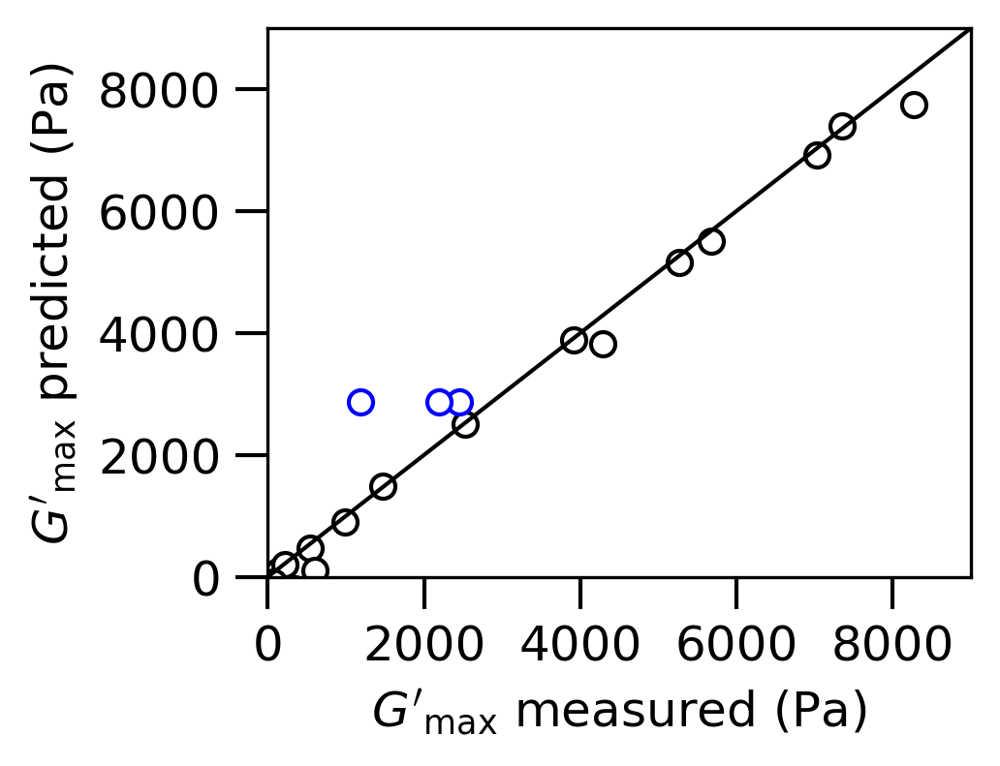

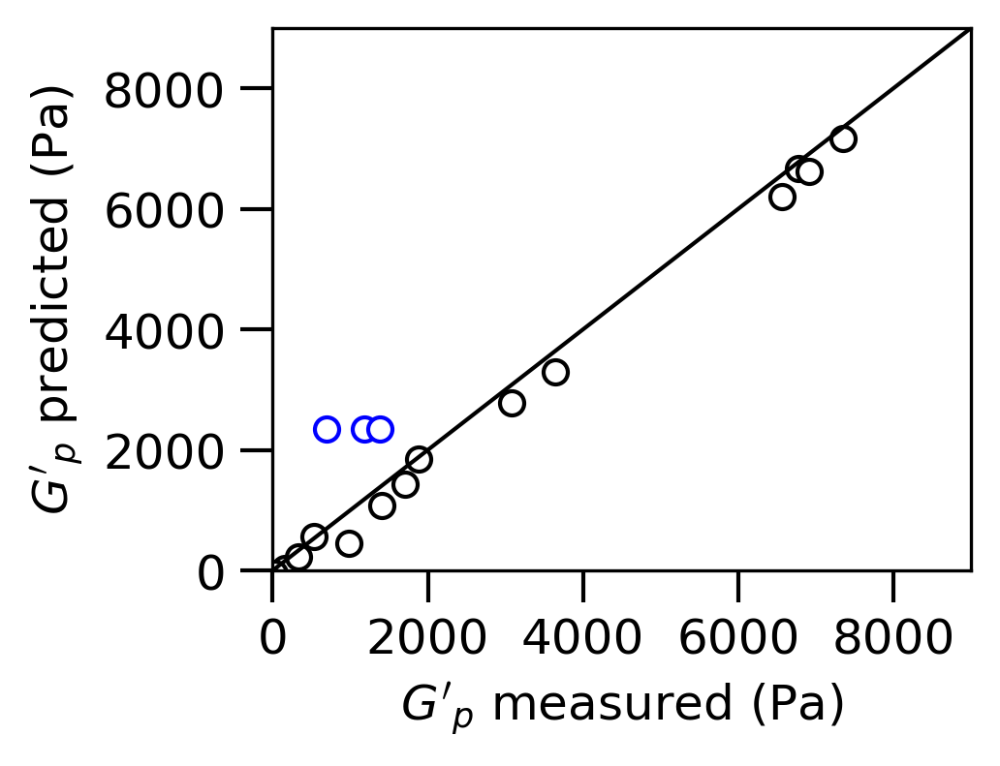

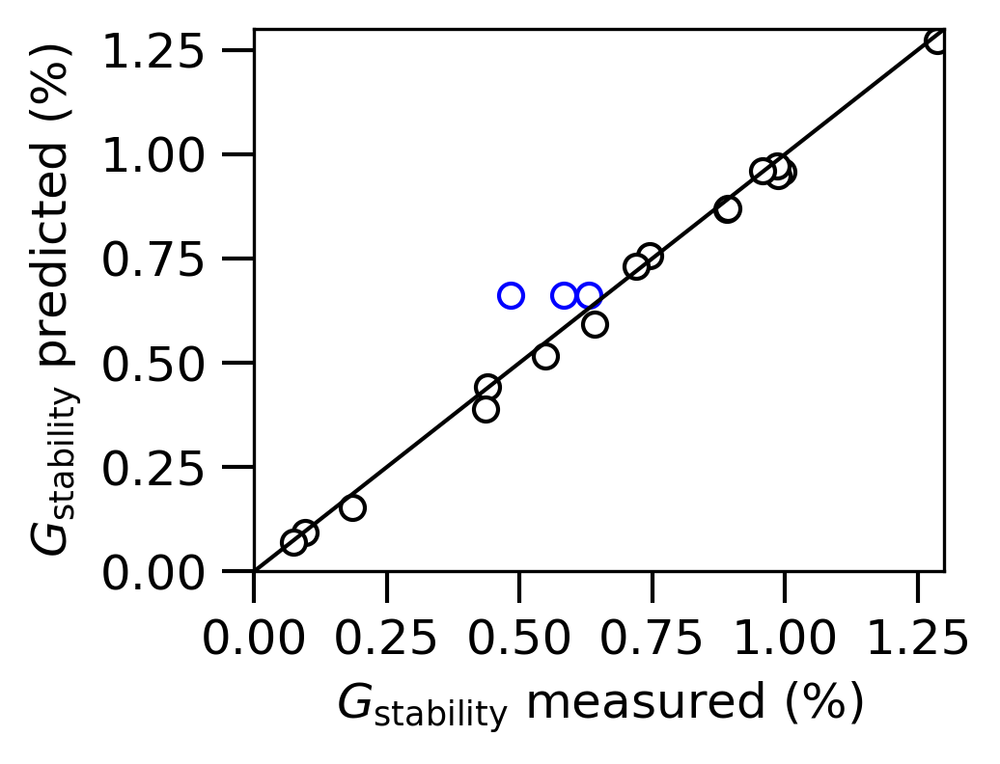

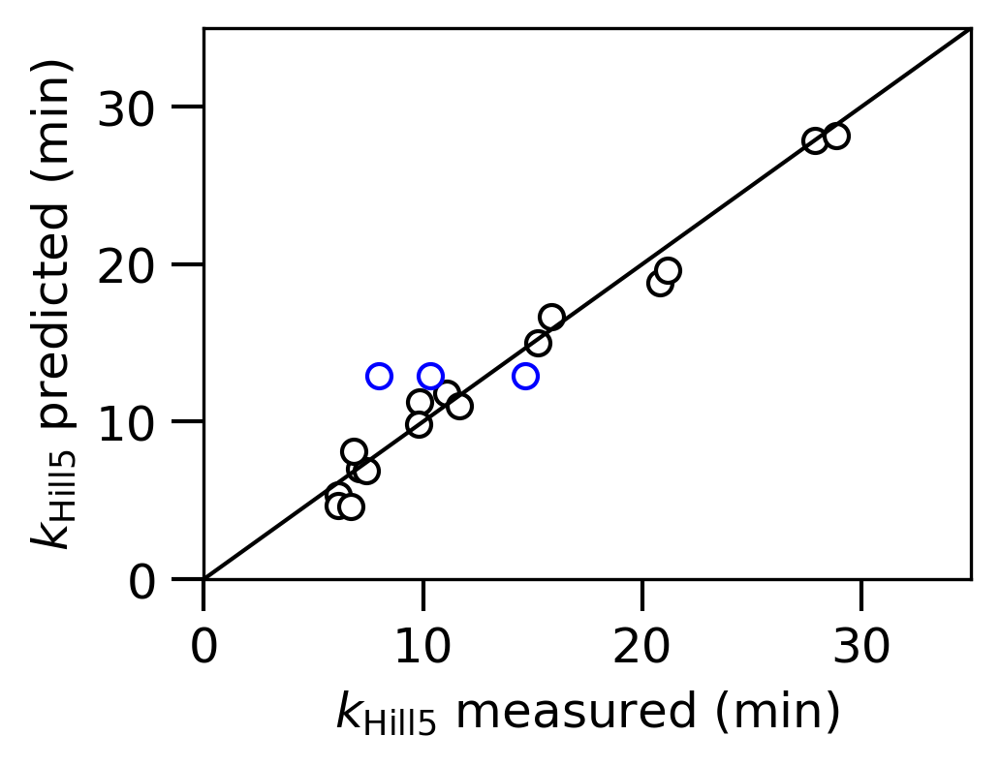

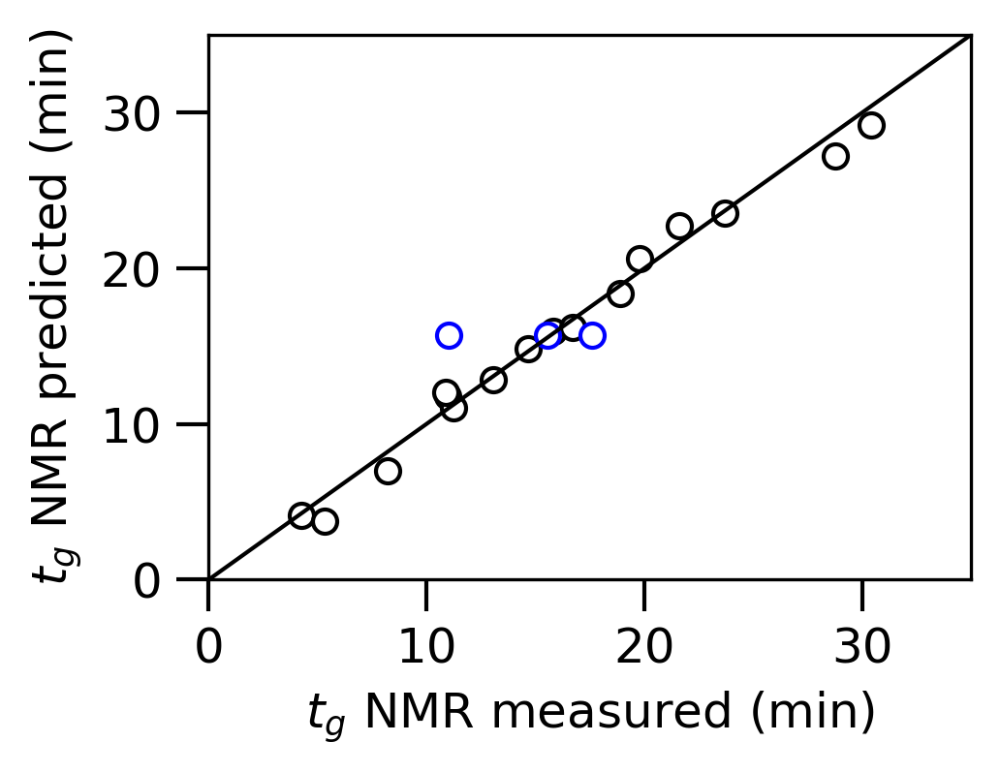

In [148]:
plot_options = {
    'marker':'o',
    'lw':0,
    'mfc':'white',
    'mew': 1,
#     'mec': 'k'
}

fig1, ax1 = plt.subplots()
fig2, ax2 = plt.subplots()
fig3, ax3 = plt.subplots()
fig4, ax4 = plt.subplots()
fig5, ax5 = plt.subplots()
for i in range(len(all_predictions['Gmax'])):
    if 'CP' in str(all_predictions.index[i]):
        mec = 'b'
    else:
        mec = 'k'
    ax1.plot(responses['Gmax'].iloc[i], all_predictions['Gmax'].iloc[i], **plot_options, mec=mec)
    ax2.plot(responses['Gplateau'].iloc[i], all_predictions['Gplateau'].iloc[i], **plot_options, mec=mec)
    ax3.plot(responses['Gstab'].iloc[i], all_predictions['Gstab'].iloc[i], **plot_options, mec=mec)
    ax4.plot(responses['khill'].iloc[i], all_predictions['khills'].iloc[i], **plot_options, mec=mec)
    ax5.plot(responses['tNMR'].iloc[i], all_predictions['tNMR'].iloc[i], **plot_options, mec=mec)
    
#     ax1.annotate(all_predictions.index[i], xy=(responses['Gmax'].iloc[i], all_predictions['Gmax'].iloc[i]), textcoords='offset points', xytext=(0, 10))
#     ax2.annotate(all_predictions.index[i], xy=(responses['Gplateau'].iloc[i], all_predictions['Gplateau'].iloc[i]), textcoords='offset points', xytext=(0,10))
#     ax3.annotate(all_predictions.index[i], xy=(responses['Gstab'].iloc[i], all_predictions['Gstab'].iloc[i]), textcoords='offset points', xytext=(0,10))
#     ax4.annotate(all_predictions.index[i], xy=(responses['khill'].iloc[i], all_predictions['khills'].iloc[i]), textcoords='offset points', xytext=(0, 10))
#     ax5.annotate(all_predictions.index[i], xy=(responses['tNMR'].iloc[i], all_predictions['tNMR'].iloc[i]), textcoords='offset points', xytext=(0, 10))
    
    
ax1.set(xlabel="$G'_{\mathrm{max}}$ measured (Pa)", ylabel="$G'_\mathrm{max}$ predicted (Pa)")
ax2.set(xlabel="$G'_{p}$ measured (Pa)", ylabel="$G'_{p}$ predicted (Pa)")
ax3.set(xlabel="$G_{\mathrm{stability}}$ measured (%)", ylabel="$G_\mathrm{stability}$ predicted (%)")
ax4.set(xlabel="$k_\mathrm{Hill5}$ measured (min)", ylabel="$k_\mathrm{Hill5}$ predicted (min)")
ax5.set(xlabel="$t_g$ NMR measured (min)", ylabel="$t_g$ NMR predicted (min)")

ax1.set_xlim(0, 9000); ax1.set_ylim(0, 9000)
ax2.set_xlim(0, 9000); ax2.set_ylim(0, 9000)
ax3.set_xlim(0, 1.3); ax3.set_ylim(0, 1.3)
ax4.set_xlim(0, 35); ax4.set_ylim(0, 35)
ax5.set_xlim(0, 35); ax5.set_ylim(0, 35)

ax1_ticks = [0, 2000, 4000, 6000, 8000]
ax2_ticks = [0, 2000, 4000, 6000, 8000]
ax3_ticks = [0, 0.25, 0.5, 0.75, 1, 1.25]
ax4_ticks = [0, 10,  20, 30,]
ax5_ticks = [0, 10,  20, 30,]

ax1.set_xticks(ax1_ticks); ax1.set_yticks(ax1_ticks)
ax2.set_xticks(ax2_ticks); ax2.set_yticks(ax2_ticks)
ax3.set_xticks(ax3_ticks); ax3.set_yticks(ax3_ticks)
ax4.set_xticks(ax4_ticks); ax4.set_yticks(ax4_ticks)
ax5.set_xticks(ax5_ticks); ax5.set_yticks(ax5_ticks)

ax1.plot([0, 10000], [0, 10000], lw=1, color='k')
ax2.plot([0, 10000], [0, 10000], lw=1, color='k')
ax3.plot([0, 10000], [0, 10000], lw=1, color='k')
ax4.plot([0, 10000], [0, 10000], lw=1, color='k')
ax5.plot([0, 10000], [0, 10000], lw=1, color='k')

fig1.tight_layout()
fig2.tight_layout()
fig3.tight_layout()
fig4.tight_layout()
fig5.tight_layout()

fig1.savefig('Pred x meas Gmax.png')
fig2.savefig('Pred x meas Gplat.png')
fig3.savefig('Pred x meas Gstab.png')
fig4.savefig('Pred x meas khills.png')
fig5.savefig('Pred x meas tg.png')

## Rheology - two examples with Hill5 model

### Exp 5

In [149]:
exp5_hill_x = [
    0.18445,
    0.23089,
    0.27734,
    0.32379,
    0.37023,
    0.41668,
    0.46313,
    0.50957,
    0.55602,
    0.60247,
    0.64891,
    0.69536,
    0.74181,
    0.78825,
    0.8347,
    0.88115,
    0.92759,
    0.97404,
    1.02049,
    1.06693,
    1.11338,
    1.15983,
    1.20627,
    1.25272,
    1.29917,
    1.34561,
    1.39206,
    1.43851,
    1.48495,
    1.5314,
    1.57785,
    1.62429,
    1.67074,
    1.71719,
    1.76363,
    1.81008,
    1.85653,
    1.90297,
    1.94942,
    1.99587,
    2.04231,
    2.08876,
    2.13521,
    2.18165,
    2.2281,
    2.27455,
    2.32099,
    2.36744,
    2.41389,
    2.46033,
    2.50678,
    2.55323,
    2.59967,
    2.64612,
    2.69257,
    2.73901,
    2.78546,
    2.83191,
    2.87835,
    2.9248,
    2.97125,
    3.01769,
    3.06414,
    3.11059,
    3.15703,
    3.20348,
    3.24993,
    3.29637,
    3.34282,
    3.38927,
    3.43571,
    3.48216,
    3.52861,
    3.57505,
    3.6215,
    3.66794,
    3.71439,
    3.76084,
    3.80728,
    3.85373,
    3.90018,
    3.94662,
    3.99307,
    4.03952,
    4.08596,
    4.13241,
    4.17886,
    4.2253,
    4.27175,
    4.3182,
    4.36464,
    4.41109,
    4.45754,
    4.50398,
    4.55043,
    4.59688,
    4.64332,
    4.68977,
    4.73622,
    4.78266,
    4.82911,
    4.87556,
    4.922,
    4.96845,
    5.0149,
    5.06134,
    5.10779,
    5.15424,
    5.20068,
    5.24713,
    5.29358,
    5.34002,
    5.38647,
    5.43292,
    5.47936,
    5.52581,
    5.57226,
    5.6187,
    5.66515,
    5.7116,
    5.75804,
    5.80449,
    5.85094,
    5.89738,
    5.94383,
    5.99028,
    6.03672,
    6.08317,
    6.12962,
    6.17606,
    6.22251,
    6.26896,
    6.3154,
    6.36185,
    6.4083,
    6.45474,
    6.50119,
    6.54764,
    6.59408,
    6.64053,
    6.68698,
    6.73342,
    6.77987,
    6.82632,
    6.87276,
    6.91921,
    6.96566,
    7.0121,
    7.05855,
    7.105,
    7.15144,
    7.19789,
    7.24434,
    7.29078,
    7.33723,
    7.38368,
    7.43012,
    7.47657,
    7.52302,
    7.56946,
    7.61591,
    7.66236,
    7.7088,
    7.75525,
    7.8017,
    7.84814,
    7.89459,
    7.94104,
    7.98748,
    8.03393,
    8.08038,
    8.12682,
    8.17327,
    8.21972,
    8.26616,
    8.31261,
    8.35906,
    8.4055,
    8.45195,
    8.4984,
    8.54484,
    8.59129,
    8.63774,
    8.68418,
    8.73063,
    8.77708,
    8.82352,
    8.86997,
    8.91642,
    8.96286,
    9.00931,
    9.05576,
    9.1022,
    9.14865,
    9.1951,
    9.24154,
    9.28799,
    9.33444,
    9.38088,
    9.42733,
    9.47378,
    9.52022,
    9.56667,
    9.61312,
    9.65956,
    9.70601,
    9.75246,
    9.7989,
    9.84535,
    9.8918,
    9.93824,
    9.98469,
    10.03114,
    10.07758,
    10.12403,
    10.17048,
    10.21692,
    10.26337,
    10.30982,
    10.35626,
    10.40271,
    10.44915,
    10.4956,
    10.54205,
    10.58849,
    10.63494,
    10.68139,
    10.72783,
    10.77428,
    10.82073,
    10.86717,
    10.91362,
    10.96007,
    11.00651,
    11.05296,
    11.09941,
    11.14585,
    11.1923,
    11.23875,
    11.28519,
    11.33164,
    11.37809,
    11.42453,
    11.47098,
    11.51743,
    11.56387,
    11.61032,
    11.65677,
    11.70321,
    11.74966,
    11.79611,
    11.84255,
    11.889,
    11.93545,
    11.98189,
    12.02834,
    12.07479,
    12.12123,
    12.16768,
    12.21413,
    12.26057,
    12.30702,
    12.35347,
    12.39991,
    12.44636,
    12.49281,
    12.53925,
    12.5857,
    12.63215,
    12.67859,
    12.72504,
    12.77149,
    12.81793,
    12.86438,
    12.91083,
    12.95727,
    13.00372,
    13.05017,
    13.09661,
    13.14306,
    13.18951,
    13.23595,
    13.2824,
    13.32885,
    13.37529,
    13.42174,
    13.46819,
    13.51463,
    13.56108,
    13.60753,
    13.65397,
    13.70042,
    13.74687,
    13.79331,
    13.83976,
    13.88621,
    13.93265,
    13.9791,
    14.02555,
    14.07199,
    14.11844,
    14.16489,
    14.21133,
    14.25778,
    14.30423,
    14.35067,
    14.39712,
    14.44357,
    14.49001,
    14.53646,
    14.58291,
    14.62935,
    14.6758,
    14.72225,
    14.76869,
    14.81514,
    14.86159,
    14.90803,
    14.95448,
    15.00093,
    15.04737,
    15.09382,
    15.14027,
    15.18671,
    15.23316,
    15.27961,
    15.32605,
    15.3725,
    15.41895,
    15.46539,
    15.51184,
    15.55829,
    15.60473,
    15.65118,
    15.69763,
    15.74407,
    15.79052,
    15.83697,
    15.88341,
    15.92986,
    15.97631,
    16.02275,
    16.0692,
    16.11565,
    16.16209,
    16.20854,
    16.25499,
    16.30143,
    16.34788,
    16.39433,
    16.44077,
    16.48722,
    16.53367,
    16.58011,
    16.62656,
    16.67301,
    16.71945,
    16.7659,
    16.81235,
    16.85879,
    16.90524,
    16.95169,
    16.99813,
    17.04458,
    17.09102,
    17.13747,
    17.18392,
    17.23036,
    17.27681,
    17.32326,
    17.3697,
    17.41615,
    17.4626,
    17.50904,
    17.55549,
    17.60194,
    17.64838,
    17.69483,
    17.74128,
    17.78772,
    17.83417,
    17.88062,
    17.92706,
    17.97351,
    18.01996,
    18.0664,
    18.11285,
    18.1593,
    18.20574,
    18.25219,
    18.29864,
    18.34508,
    18.39153,
    18.43798,
    18.48442,
    18.53087,
    18.57732,
    18.62376,
    18.67021,
    18.71666,
    18.7631,
    18.80955,
    18.856,
    18.90244,
    18.94889,
    18.99534,
    19.04178,
    19.08823,
    19.13468,
    19.18112,
    19.22757,
    19.27402,
    19.32046,
    19.36691,
    19.41336,
    19.4598,
    19.50625,
    19.5527,
    19.59914,
    19.64559,
    19.69204,
    19.73848,
    19.78493,
    19.83138,
    19.87782,
    19.92427,
    19.97072,
    20.01716,
    20.06361,
    20.11006,
    20.1565,
    20.20295,
    20.2494,
    20.29584,
    20.34229,
    20.38874,
    20.43518,
    20.48163,
    20.52808,
    20.57452,
    20.62097,
    20.66742,
    20.71386,
    20.76031,
    20.80676,
    20.8532,
    20.89965,
    20.9461,
    20.99254,
    21.03899,
    21.08544,
    21.13188,
    21.17833,
    21.22478,
    21.27122,
    21.31767,
    21.36412,
    21.41056,
    21.45701,
    21.50346,
    21.5499,
    21.59635,
    21.6428,
    21.68924,
    21.73569,
    21.78214,
    21.82858,
    21.87503,
    21.92148,
    21.96792,
    22.01437,
    22.06082,
    22.10726,
    22.15371,
    22.20016,
    22.2466,
    22.29305,
    22.3395,
    22.38594,
    22.43239,
    22.47884,
    22.52528,
    22.57173,
    22.61818,
    22.66462,
    22.71107,
    22.75752,
    22.80396,
    22.85041,
    22.89686,
    22.9433,
    22.98975,
    23.0362,
    23.08264,
    23.12909,
    23.17554,
    23.22198,
    23.26843,
    23.31488,
    23.36132,
    23.40777,
    23.45422,
    23.50066,
    23.54711,
    23.59356,
    23.64,
    23.68645,
    23.73289,
    23.77934,
    23.82579,
    23.87223,
    23.91868,
    23.96513,
    24.01157,
    24.05802,
    24.10447,
    24.15091,
    24.19736,
    24.24381,
    24.29025,
    24.3367,
    24.38315,
    24.42959,
    24.47604,
    24.52249,
    24.56893,
    24.61538,
    24.66183,
    24.70827,
    24.75472,
    24.80117,
    24.84761,
    24.89406,
    24.94051,
    24.98695,
    25.0334,
    25.07985,
    25.12629,
    25.17274,
    25.21919,
    25.26563,
    25.31208,
    25.35853,
    25.40497,
    25.45142,
    25.49787,
    25.54431,
    25.59076,
    25.63721,
    25.68365,
    25.7301,
    25.77655,
    25.82299,
    25.86944,
    25.91589,
    25.96233,
    26.00878,
    26.05523,
    26.10167,
    26.14812,
    26.19457,
    26.24101,
    26.28746,
    26.33391,
    26.38035,
    26.4268,
    26.47325,
    26.51969,
    26.56614,
    26.61259,
    26.65903,
    26.70548,
    26.75193,
    26.79837,
    26.84482,
    26.89127,
    26.93771,
    26.98416,
    27.03061,
    27.07705,
    27.1235,
    27.16995,
    27.21639,
    27.26284,
    27.30929,
    27.35573,
    27.40218,
    27.44863,
    27.49507,
    27.54152,
    27.58797,
    27.63441,
    27.68086,
    27.72731,
    27.77375,
    27.8202,
    27.86665,
    27.91309,
    27.95954,
    28.00599,
    28.05243,
    28.09888,
    28.14533,
    28.19177,
    28.23822,
    28.28467,
    28.33111,
    28.37756,
    28.42401,
    28.47045,
    28.5169,
    28.56335,
    28.60979,
    28.65624,
    28.70269,
    28.74913,
    28.79558,
    28.84203,
    28.88847,
    28.93492,
    28.98137,
    29.02781,
    29.07426,
    29.12071,
    29.16715,
    29.2136,
    29.26005,
    29.30649,
    29.35294,
    29.39939,
    29.44583,
    29.49228,
    29.53873,
    29.58517,
    29.63162,
    29.67807,
    29.72451,
    29.77096,
    29.81741,
    29.86385,
    29.9103,
    29.95675,
    30.00319,
    30.04964,
    30.09609,
    30.14253,
    30.18898,
    30.23543,
    30.28187,
    30.32832,
    30.37476,
    30.42121,
    30.46766,
    30.5141,
    30.56055,
    30.607,
    30.65344,
    30.69989,
    30.74634,
    30.79278,
    30.83923,
    30.88568,
    30.93212,
    30.97857,
    31.02502,
    31.07146,
    31.11791,
    31.16436,
    31.2108,
    31.25725,
    31.3037,
    31.35014,
    31.39659,
    31.44304,
    31.48948,
    31.53593,
    31.58238,
    31.62882,
    31.67527,
    31.72172,
    31.76816,
    31.81461,
    31.86106,
    31.9075,
    31.95395,
    32.0004,
    32.04684,
    32.09329,
    32.13974,
    32.18618,
    32.23263,
    32.27908,
    32.32552,
    32.37197,
    32.41842,
    32.46486,
    32.51131,
    32.55776,
    32.6042,
    32.65065,
    32.6971,
    32.74354,
    32.78999,
    32.83644,
    32.88288,
    32.92933,
    32.97578,
    33.02222,
    33.06867,
    33.11512,
    33.16156,
    33.20801,
    33.25446,
    33.3009,
    33.34735,
    33.3938,
    33.44024,
    33.48669,
    33.53314,
    33.57958,
    33.62603,
    33.67248,
    33.71892,
    33.76537,
    33.81182,
    33.85826,
    33.90471,
    33.95116,
    33.9976,
    34.04405,
    34.0905,
    34.13694,
    34.18339,
    34.22984,
    34.27628,
    34.32273,
    34.36918,
    34.41562,
    34.46207,
    34.50852,
    34.55496,
    34.60141,
    34.64786,
    34.6943,
    34.74075,
    34.7872,
    34.83364,
    34.88009,
    34.92654,
    34.97298,
    35.01943,
    35.06588,
    35.11232,
    35.15877,
    35.20522,
    35.25166,
    35.29811,
    35.34456,
    35.391,
    35.43745,
    35.4839,
    35.53034,
    35.57679,
    35.62324,
    35.66968,
    35.71613,
    35.76258,
    35.80902,
    35.85547,
    35.90192,
    35.94836,
    35.99481,
    36.04126,
    36.0877,
    36.13415,
    36.1806,
    36.22704,
    36.27349,
    36.31994,
    36.36638,
    36.41283,
    36.45928,
    36.50572,
    36.55217,
    36.59862,
    36.64506,
    36.69151,
    36.73796,
    36.7844,
    36.83085,
    36.8773,
    36.92374,
    36.97019,
    37.01663,
    37.06308,
    37.10953,
    37.15597,
    37.20242,
    37.24887,
    37.29531,
    37.34176,
    37.38821,
    37.43465,
    37.4811,
    37.52755,
    37.57399,
    37.62044,
    37.66689,
    37.71333,
    37.75978,
    37.80623,
    37.85267,
    37.89912,
    37.94557,
    37.99201,
    38.03846,
    38.08491,
    38.13135,
    38.1778,
    38.22425,
    38.27069,
    38.31714,
    38.36359,
    38.41003,
    38.45648,
    38.50293,
    38.54937,
    38.59582,
    38.64227,
    38.68871,
    38.73516,
    38.78161,
    38.82805,
    38.8745,
    38.92095,
    38.96739,
    39.01384,
    39.06029,
    39.10673,
    39.15318,
    39.19963,
    39.24607,
    39.29252,
    39.33897,
    39.38541,
    39.43186,
    39.47831,
    39.52475,
    39.5712,
    39.61765,
    39.66409,
    39.71054,
    39.75699,
    39.80343,
    39.84988,
    39.89633,
    39.94277,
    39.98922,
    40.03567,
    40.08211,
    40.12856,
    40.17501,
    40.22145,
    40.2679,
    40.31435,
    40.36079,
    40.40724,
    40.45369,
    40.50013,
    40.54658,
    40.59303,
    40.63947,
    40.68592,
    40.73237,
    40.77881,
    40.82526,
    40.87171,
    40.91815,
    40.9646,
    41.01105,
    41.05749,
    41.10394,
    41.15039,
    41.19683,
    41.24328,
    41.28973,
    41.33617,
    41.38262,
    41.42907,
    41.47551,
    41.52196,
    41.56841,
    41.61485,
    41.6613,
    41.70775,
    41.75419,
    41.80064,
    41.84709,
    41.89353,
    41.93998,
    41.98643,
    42.03287,
    42.07932,
    42.12577,
    42.17221,
    42.21866,
    42.26511,
    42.31155,
    42.358,
    42.40445,
    42.45089,
    42.49734,
    42.54379,
    42.59023,
    42.63668,
    42.68313,
    42.72957,
    42.77602,
    42.82247,
    42.86891,
    42.91536,
    42.96181,
    43.00825,
    43.0547,
    43.10115,
    43.14759,
    43.19404,
    43.24049,
    43.28693,
    43.33338,
    43.37983,
    43.42627,
    43.47272,
    43.51917,
    43.56561,
    43.61206,
    43.65851,
    43.70495,
    43.7514,
    43.79784,
    43.84429,
    43.89074,
    43.93718,
    43.98363,
    44.03008,
    44.07652,
    44.12297,
    44.16942,
    44.21586,
    44.26231,
    44.30876,
    44.3552,
    44.40165,
    44.4481,
    44.49454,
    44.54099,
    44.58744,
    44.63388,
    44.68033,
    44.72678,
    44.77322,
    44.81967,
    44.86612,
    44.91256,
    44.95901,
    45.00546,
    45.0519,
    45.09835,
    45.1448,
    45.19124,
    45.23769,
    45.28414,
    45.33058,
    45.37703,
    45.42348,
    45.46992,
    45.51637,
    45.56282,
    45.60926,
    45.65571,
    45.70216,
    45.7486,
    45.79505,
    45.8415,
    45.88794,
    45.93439,
    45.98084,
    46.02728,
    46.07373,
    46.12018,
    46.16662,
    46.21307,
    46.25952,
    46.30596,
    46.35241,
    46.39886,
    46.4453,
    46.49175,
    46.5382,
    46.58464,
]

In [150]:
exp_5_hill_y = [
-1.06178,
-1.06178,
-1.06178,
-1.06178,
-1.06178,
-1.06177,
-1.06177,
-1.06177,
-1.06176,
-1.06176,
-1.06174,
-1.06172,
-1.06169,
-1.06165,
-1.06158,
-1.0615,
-1.06138,
-1.06123,
-1.06103,
-1.06077,
-1.06043,
-1.06001,
-1.05948,
-1.05881,
-1.058,
-1.057,
-1.05579,
-1.05432,
-1.05257,
-1.05049,
-1.04803,
-1.04513,
-1.04174,
-1.03779,
-1.03322,
-1.02794,
-1.02187,
-1.01493,
-1.00702,
-0.99803,
-0.98786,
-0.9764,
-0.96351,
-0.94906,
-0.93293,
-0.91496,
-0.895,
-0.87289,
-0.84846,
-0.82153,
-0.79193,
-0.75945,
-0.72392,
-0.68512,
-0.64284,
-0.59686,
-0.54697,
-0.49293,
-0.43451,
-0.37148,
-0.30358,
-0.23057,
-0.1522,
-0.0682,
0.02167,
0.11768,
0.2201,
0.32919,
0.44522,
0.56846,
0.69917,
0.83762,
0.98409,
1.13883,
1.30212,
1.47421,
1.65537,
1.84585,
2.0459,
2.25578,
2.47572,
2.70598,
2.94677,
3.19833,
3.46088,
3.73463,
4.0198,
4.31658,
4.62516,
4.94573,
5.27846,
5.62353,
5.98108,
6.35128,
6.73425,
7.13013,
7.53903,
7.96108,
8.39637,
8.84499,
9.30702,
9.78253,
10.27159,
10.77423,
11.29051,
11.82045,
12.36407,
12.92138,
13.49239,
14.07707,
14.67541,
15.28738,
15.91294,
16.55205,
17.20464,
17.87065,
18.55,
19.24261,
19.94839,
20.66724,
21.39904,
22.14369,
22.90106,
23.67101,
24.45342,
25.24814,
26.05502,
26.8739,
27.70462,
28.54701,
29.4009,
30.26611,
31.14246,
32.02976,
32.92783,
33.83645,
34.75545,
35.6846,
36.62372,
37.57258,
38.53098,
39.49871,
40.47554,
41.46127,
42.45566,
43.45851,
44.46958,
45.48866,
46.51552,
47.54994,
48.59169,
49.64055,
50.69628,
51.75867,
52.82749,
53.90252,
54.98353,
56.0703,
57.1626,
58.26022,
59.36294,
60.47053,
61.58279,
62.69949,
63.82043,
64.94538,
66.07414,
67.20651,
68.34227,
69.48123,
70.62318,
71.76792,
72.91525,
74.06499,
75.21694,
76.37091,
77.52671,
78.68417,
79.8431,
81.00332,
82.16466,
83.32694,
84.49,
85.65367,
86.81778,
87.98217,
89.1467,
90.31119,
91.4755,
92.63949,
93.80299,
94.96588,
96.12801,
97.28925,
98.44945,
99.60849,
100.76624,
101.92257,
103.07737,
104.2305,
105.38187,
106.53134,
107.67881,
108.82417,
109.96732,
111.10815,
112.24656,
113.38246,
114.51575,
115.64633,
116.77412,
117.89903,
119.02097,
120.13987,
121.25564,
122.36821,
123.4775,
124.58343,
125.68595,
126.78497,
127.88044,
128.9723,
130.06047,
131.1449,
132.22553,
133.30232,
134.3752,
135.44412,
136.50904,
137.5699,
138.62667,
139.6793,
140.72775,
141.77198,
142.81195,
143.84762,
144.87896,
145.90593,
146.92851,
147.94667,
148.96037,
149.96959,
150.97431,
151.9745,
152.97013,
153.9612,
154.94767,
155.92953,
156.90676,
157.87934,
158.84727,
159.81053,
160.7691,
161.72297,
162.67214,
163.61659,
164.55633,
165.49133,
166.42159,
167.34712,
168.2679,
169.18393,
170.09521,
171.00174,
171.90352,
172.80055,
173.69282,
174.58035,
175.46313,
176.34118,
177.21448,
178.08305,
178.94689,
179.80601,
180.66041,
181.51011,
182.35511,
183.19542,
184.03104,
184.862,
185.68829,
186.50993,
187.32694,
188.13931,
188.94707,
189.75022,
190.54879,
191.34278,
192.1322,
192.91708,
193.69742,
194.47324,
195.24456,
196.01139,
196.77375,
197.53165,
198.28511,
199.03415,
199.77879,
200.51903,
201.2549,
201.98642,
202.71361,
203.43648,
204.15505,
204.86934,
205.57937,
206.28516,
206.98672,
207.68408,
208.37726,
209.06627,
209.75114,
210.43189,
211.10853,
211.78108,
212.44957,
213.11402,
213.77444,
214.43086,
215.0833,
215.73178,
216.37631,
217.01692,
217.65364,
218.28647,
218.91545,
219.54059,
220.16192,
220.77945,
221.39321,
222.00321,
222.60948,
223.21205,
223.81092,
224.40612,
224.99768,
225.58561,
226.16993,
226.75067,
227.32785,
227.90148,
228.47159,
229.03821,
229.60134,
230.16101,
230.71725,
231.27007,
231.81949,
232.36553,
232.90822,
233.44758,
233.98362,
234.51637,
235.04585,
235.57207,
236.09506,
236.61484,
237.13142,
237.64484,
238.1551,
238.66223,
239.16625,
239.66717,
240.16502,
240.65982,
241.15159,
241.64034,
242.12609,
242.60888,
243.0887,
243.56559,
244.03956,
244.51063,
244.97883,
245.44416,
245.90664,
246.36631,
246.82317,
247.27724,
247.72855,
248.1771,
248.62292,
249.06603,
249.50644,
249.94417,
250.37925,
250.81168,
251.24148,
251.66868,
252.09329,
252.51532,
252.9348,
253.35174,
253.76616,
254.17808,
254.5875,
254.99446,
255.39896,
255.80102,
256.20066,
256.5979,
256.99275,
257.38522,
257.77534,
258.16311,
258.54856,
258.93171,
259.31255,
259.69112,
260.06743,
260.44149,
260.81332,
261.18293,
261.55034,
261.91556,
262.27861,
262.6395,
262.99825,
263.35487,
263.70938,
264.06178,
264.41211,
264.76036,
265.10655,
265.4507,
265.79283,
266.13294,
266.47104,
266.80716,
267.14131,
267.47349,
267.80373,
268.13203,
268.45841,
268.78289,
269.10547,
269.42616,
269.74499,
270.06196,
270.37709,
270.69039,
271.00186,
271.31153,
271.61941,
271.92551,
272.22983,
272.5324,
272.83322,
273.13231,
273.42967,
273.72533,
274.01929,
274.31155,
274.60215,
274.89107,
275.17835,
275.46398,
275.74798,
276.03037,
276.31114,
276.59031,
276.8679,
277.14391,
277.41836,
277.69125,
277.96259,
278.2324,
278.50069,
278.76746,
279.03273,
279.29651,
279.5588,
279.81962,
280.07898,
280.33688,
280.59334,
280.84837,
281.10197,
281.35415,
281.60493,
281.85431,
282.10231,
282.34893,
282.59418,
282.83807,
283.08061,
283.32182,
283.56168,
283.80023,
284.03746,
284.27339,
284.50802,
284.74136,
284.97342,
285.20421,
285.43373,
285.662,
285.88903,
286.11482,
286.33938,
286.56271,
286.78484,
287.00575,
287.22547,
287.44401,
287.66135,
287.87753,
288.09254,
288.30639,
288.51909,
288.73064,
288.94106,
289.15035,
289.35852,
289.56558,
289.77152,
289.97637,
290.18013,
290.3828,
290.5844,
290.78492,
290.98438,
291.18278,
291.38014,
291.57645,
291.77172,
291.96596,
292.15918,
292.35138,
292.54257,
292.73276,
292.92196,
293.11016,
293.29737,
293.48361,
293.66888,
293.85318,
294.03652,
294.21891,
294.40035,
294.58086,
294.76042,
294.93906,
295.11677,
295.29357,
295.46946,
295.64444,
295.81852,
295.9917,
296.164,
296.33542,
296.50596,
296.67562,
296.84442,
297.01236,
297.17945,
297.34568,
297.51107,
297.67562,
297.83934,
298.00223,
298.1643,
298.32554,
298.48598,
298.6456,
298.80443,
298.96245,
299.11968,
299.27613,
299.43179,
299.58667,
299.74078,
299.89412,
300.04669,
300.19851,
300.34957,
300.49988,
300.64945,
300.79828,
300.94637,
301.09373,
301.24036,
301.38627,
301.53146,
301.67594,
301.81971,
301.96277,
302.10514,
302.2468,
302.38778,
302.52806,
302.66767,
302.80659,
302.94484,
303.08241,
303.21932,
303.35557,
303.49116,
303.62609,
303.76037,
303.894,
304.02699,
304.15934,
304.29106,
304.42214,
304.55259,
304.68242,
304.81163,
304.94022,
305.0682,
305.19557,
305.32234,
305.4485,
305.57406,
305.69903,
305.82341,
305.9472,
306.0704,
306.19302,
306.31507,
306.43654,
306.55744,
306.67777,
306.79754,
306.91674,
307.03539,
307.15349,
307.27103,
307.38803,
307.50448,
307.62039,
307.73577,
307.8506,
307.96491,
308.07869,
308.19194,
308.30466,
308.41687,
308.52856,
308.63974,
308.75041,
308.86057,
308.97022,
309.07938,
309.18803,
309.29619,
309.40385,
309.51103,
309.61771,
309.72391,
309.82963,
309.93487,
310.03964,
310.14393,
310.24775,
310.3511,
310.45398,
310.5564,
310.65836,
310.75986,
310.86091,
310.96151,
311.06165,
311.16135,
311.2606,
311.35941,
311.45778,
311.55571,
311.65321,
311.75027,
311.8469,
311.94311,
312.03889,
312.13425,
312.22918,
312.3237,
312.4178,
312.51149,
312.60477,
312.69764,
312.7901,
312.88216,
312.97381,
313.06506,
313.15592,
313.24638,
313.33645,
313.42612,
313.51541,
313.60431,
313.69282,
313.78095,
313.8687,
313.95607,
314.04307,
314.12969,
314.21594,
314.30182,
314.38732,
314.47247,
314.55725,
314.64166,
314.72572,
314.80941,
314.89275,
314.97574,
315.05837,
315.14065,
315.22259,
315.30417,
315.38541,
315.46631,
315.54687,
315.62708,
315.70696,
315.7865,
315.86571,
315.94459,
316.02313,
316.10135,
316.17924,
316.2568,
316.33404,
316.41096,
316.48755,
316.56383,
316.63979,
316.71544,
316.79077,
316.86579,
316.9405,
317.01491,
317.089,
317.16279,
317.23628,
317.30946,
317.38234,
317.45493,
317.52721,
317.5992,
317.6709,
317.7423,
317.81341,
317.88424,
317.95477,
318.02502,
318.09498,
318.16465,
318.23405,
318.30316,
318.372,
318.44055,
318.50883,
318.57684,
318.64457,
318.71203,
318.77921,
318.84613,
318.91278,
318.97916,
319.04528,
319.11114,
319.17673,
319.24205,
319.30712,
319.37193,
319.43649,
319.50078,
319.56482,
319.62861,
319.69215,
319.75543,
319.81847,
319.88125,
319.94379,
320.00608,
320.06813,
320.12994,
320.1915,
320.25282,
320.3139,
320.37474,
320.43535,
320.49572,
320.55585,
320.61575,
320.67542,
320.73485,
320.79405,
320.85303,
320.91178,
320.9703,
321.02859,
321.08666,
321.1445,
321.20212,
321.25953,
321.31671,
321.37367,
321.43041,
321.48693,
321.54324,
321.59934,
321.65522,
321.71088,
321.76634,
321.82158,
321.87662,
321.93144,
321.98606,
322.04047,
322.09467,
322.14867,
322.20247,
322.25606,
322.30945,
322.36264,
322.41563,
322.46842,
322.52101,
322.57341,
322.62561,
322.67761,
322.72942,
322.78104,
322.83246,
322.88369,
322.93474,
322.98559,
323.03625,
323.08673,
323.13701,
323.18712,
323.23703,
323.28677,
323.33631,
323.38568,
323.43487,
323.48387,
323.53269,
323.58134,
323.6298,
323.67809,
323.7262,
323.77414,
323.8219,
323.86949,
323.9169,
323.96414,
324.01121,
324.05811,
324.10484,
324.1514,
324.19779,
324.24401,
324.29006,
324.33595,
324.38167,
324.42723,
324.47263,
324.51786,
324.56293,
324.60783,
324.65258,
324.69717,
324.74159,
324.78586,
324.82997,
324.87392,
324.91772,
324.96136,
325.00484,
325.04817,
325.09135,
325.13437,
325.17724,
325.21996,
325.26253,
325.30495,
325.34722,
325.38934,
325.43131,
325.47313,
325.51481,
325.55634,
325.59773,
325.63897,
325.68006,
325.72101,
325.76182,
325.80249,
325.84302,
325.8834,
325.92364,
325.96375,
326.00371,
326.04354,
326.08323,
326.12278,
326.16219,
326.20147,
326.24061,
326.27962,
326.31849,
326.35723,
326.39584,
326.43431,
326.47265,
326.51086,
326.54894,
326.58689,
326.62471,
326.6624,
326.69996,
326.7374,
326.7747,
326.81188,
326.84894,
326.88587,
326.92267,
326.95935,
326.9959,
327.03233,
327.06864,
327.10482,
327.14089,
327.17683,
327.21265,
327.24835,
327.28393,
327.31939,
327.35473,
327.38996,
327.42506,
327.46005,
327.49492,
327.52968,
327.56432,
327.59885,
327.63326,
327.66755,
327.70173,
327.7358,
327.76976,
327.8036,
327.83733,
327.87095,
327.90446,
327.93786,
327.97115,
328.00433,
328.0374,
328.07036,
328.10321,
328.13596,
328.1686,
328.20113,
328.23355,
328.26587,
328.29809,
328.3302,
328.3622,
328.3941,
328.4259,
328.45759,
328.48918,
328.52067,
328.55206,
328.58334,
328.61453,
328.64561,
328.67659,
328.70747,
328.73826,
328.76894,
328.79953,
328.83002,
328.86041,
328.8907,
328.92089,
328.95099,
328.981,
329.0109,
329.04071,
329.07043,
329.10005,
329.12958,
329.15901,
329.18835,
329.2176,
329.24676,
329.27582,
329.30479,
329.33367,
329.36246,
329.39115,
329.41976,
329.44828,
329.4767,
]

In [151]:
exp_5_x = [
0.18445,
0.40818,
0.57648,
0.80089,
1.02558,
1.19276,
1.41774,
1.58712,
1.81113,
1.97953,
2.20298,
2.42614,
2.59327,
2.81745,
2.98632,
3.21002,
3.37911,
3.60404,
3.82916,
3.99642,
4.22123,
4.38864,
4.61252,
4.78121,
5.00362,
5.22729,
5.39545,
5.62,
5.78707,
6.00907,
6.17639,
6.3994,
6.62422,
6.79155,
7.01376,
7.18097,
7.40408,
7.57416,
7.79738,
8.02451,
8.19051,
8.41328,
8.58149,
8.80503,
8.97523,
9.1985,
9.42513,
9.59246,
9.81579,
9.98393,
10.2059,
10.37522,
10.59859,
10.82375,
10.99087,
11.21284,
11.38245,
11.60649,
11.77573,
11.99978,
12.22467,
12.39121,
12.61684,
12.78617,
13.00907,
13.17974,
13.40157,
13.62535,
13.7923,
14.01496,
14.18317,
14.40467,
14.5746,
14.79838,
15.02431,
15.1921,
15.41549,
15.58448,
15.80716,
15.97515,
16.19746,
16.42126,
16.58915,
16.83192,
16.98061,
17.20307,
17.37289,
17.59714,
17.82121,
17.9868,
18.21124,
18.38238,
18.60518,
18.77354,
18.99599,
19.21971,
19.38722,
19.61066,
19.78104,
20.00412,
20.17389,
20.39571,
20.61924,
20.78772,
21.01112,
21.18102,
21.40517,
21.57442,
21.79825,
22.02307,
22.1907,
22.41322,
22.58159,
22.80432,
22.97478,
23.19715,
23.4212,
23.58866,
23.81212,
23.98182,
24.2061,
24.37424,
24.59726,
24.8194,
24.98571,
25.20938,
25.3785,
25.60283,
25.77104,
25.99352,
26.21718,
26.38678,
26.60812,
26.77626,
26.9979,
27.22379,
27.3897,
27.61193,
27.78103,
28.00406,
28.17464,
28.3969,
28.62064,
28.78827,
29.01181,
29.18218,
29.40508,
29.57445,
29.79709,
30.0199,
30.18723,
30.4097,
30.57981,
30.80173,
30.97073,
31.19254,
31.41652,
31.58567,
31.80818,
31.97574,
32.19914,
32.42333,
32.59021,
32.81346,
32.98177,
33.20619,
33.37568,
33.59923,
33.82385,
33.9906,
34.21483,
34.38364,
34.60543,
34.77576,
34.99961,
35.22432,
35.39171,
35.61553,
35.78377,
36.00621,
36.17442,
36.397,
36.6208,
36.78729,
37.00945,
37.1786,
37.40117,
37.57071,
37.79398,
38.01863,
38.18418,
38.40811,
38.57751,
38.80044,
39.0247,
39.19069,
39.41298,
39.57992,
39.80377,
39.97428,
40.19604,
40.42102,
40.58809,
40.81078,
40.97988,
41.20266,
41.37277,
41.59546,
41.82041,
41.98831,
42.21094,
42.37977,
42.60391,
42.77463,
42.99795,
43.22372,
43.39084,
43.61356,
43.78085,
44.00378,
44.17427,
44.39769,
44.62257,
44.78936,
45.0132,
45.18219,
45.4042,
45.57464,
45.79877,
45.969,
46.19223,
46.41486,
46.58464,
46.80774,
46.97492,
47.19784,
47.42265,
47.58934,
47.81216,
47.9825,
48.20666,
48.37481,
48.59765,
48.8245,
48.99083,
49.21331,
49.38172,
49.60564,
49.77403,
49.9971,
50.22242,
50.38957,
50.61128,
50.78118,
51.00388,
51.17339,
51.39658,
51.62019,
51.78757,
52.0103,
52.17981,
52.40314,
52.57295,
52.7953,
53.01923,
53.18621,
53.40952,
53.57826,
53.8035,
53.97275,
54.1942,
54.41895,
54.58628,
54.80798,
54.97797,
55.20318,
55.37396,
55.59762,
55.82281,
55.99026,
56.21187,
56.38078,
56.60332,
56.77322,
56.99544,
57.21903,
57.38515,
57.60819,
57.77818,
58.00157,
58.17017,
58.3919,
58.61431,
58.78381,
59.00753,
59.17566,
59.39786,
59.62359,
59.79022,
60.01294,
60.18168,
60.40562,
60.57405,
60.79693,
61.02171,
61.18972,
61.41229,
61.58074,
61.80354,
61.97394,
62.19565,
62.41925,
62.58703,
62.80948,
62.97847,
63.20042,
63.36899,
63.59124,
63.81496,
63.98395,
64.20811,
64.37681,
64.60157,
64.77001,
64.99295,
65.21945,
65.38698,
65.61057,
65.78023,
66.00209,
66.16903,
66.39266,
66.61779,
66.7852,
67.00837,
67.17851,
67.40162,
67.57249,
67.79604,
68.0195,
68.18719,
68.40974,
68.57872,
68.80133,
68.97166,
69.19446,
69.41925,
69.58808,
69.80986,
69.97792,
70.19973,
70.36791,
70.59137,
70.81718,
70.98584,
71.20917,
71.37948,
71.60386,
71.77326,
71.99546,
72.22217,
72.38938,
72.61427,
72.78408,
73.00885,
73.1774,
73.40141,
73.57205,
73.79457,
74.01916,
74.18631,
74.40872,
74.57761,
74.80015,
74.96962,
75.19192,
75.41453,
75.5835,
75.8068,
75.97749,
76.20099,
76.37023,
76.59419,
76.81846,
76.98559,
77.20802,
77.37498,
77.59862,
77.7682,
77.9917,
78.21364,
78.38442,
78.60844,
78.7778,
78.99997,
79.16895,
79.39219,
79.61453,
79.78535,
80.00824,
80.17786,
80.40014,
80.56903,
80.79057,
81.01366,
81.18181,
81.4039,
81.57276,
81.79718,
82.02297,
82.1907,
82.41367,
82.58231,
82.80472,
82.97331,
83.19373,
83.41778,
83.58451,
83.80693,
83.97796,
84.20176,
84.37162,
84.59576,
84.76658,
84.9918,
85.21444,
85.3845,
85.60811,
85.77727,
85.99902,
86.16816,
86.39124,
86.6143,
86.78335,
87.00546,
87.17481,
87.39724,
87.6221,
87.78967,
88.01318,
88.18084,
88.40461,
88.57373,
88.79749,
89.02285,
89.1901,
89.41309,
89.58158,
89.80435,
89.97416,
90.19814,
90.36522,
90.5902,
90.81361,
90.98173,
91.20339,
91.37411,
91.596,
91.82096,
91.98818,
92.21073,
92.37894,
92.60244,
92.77159,
92.99442,
93.21756,
93.38403,
93.60712,
93.77735,
93.99976,
94.16807,
94.39106,
94.61553,
94.7855,
95.00712,
95.17834,
95.40194,
95.5724,
95.79443,
96.019,
96.18637,
96.40911,
96.57855,
96.80207,
96.9724,
97.19703,
97.36474,
97.58902,
97.81342,
97.98426,
98.20689,
98.37551,
98.59856,
98.76776,
98.99111,
99.21401,
99.3825,
99.6046,
99.77327,
99.99611,
100.22155,
100.38889,
100.61037,
100.78046,
101.00392,
101.17321,
101.39639,
101.62095,
101.78809,
102.01122,
102.18037,
102.4034,
102.57214,
102.79675,
102.96515,
103.19115,
103.41531,
103.58354,
103.80703,
103.97644,
104.19889,
104.36523,
104.58944,
104.81243,
104.98129,
105.20359,
105.37262,
105.59529,
105.82087,
105.98916,
106.21307,
106.38346,
106.6071,
106.77511,
106.99879,
107.16759,
107.39014,
107.6142,
107.78392,
108.00691,
108.17515,
108.39836,
108.56544,
108.79149,
109.01502,
109.1835,
109.4068,
109.57719,
109.80035,
109.96834,
110.19102,
110.41504,
110.58475,
110.80679,
110.97498,
111.19624,
111.41932,
111.5874,
111.81038,
111.97915,
112.20237,
112.37134,
112.59573,
112.8209,
112.98793,
113.21134,
113.37912,
113.6028,
113.77144,
113.99516,
114.16313,
114.38734,
114.60889,
114.77888,
115.00194,
115.1708,
115.39419,
115.61787,
115.78516,
116.00733,
116.17487,
116.39712,
116.56501,
116.78865,
117.01078,
117.17865,
117.4023,
117.57134,
117.79312,
118.01726,
118.18415,
118.40771,
118.57652,
118.79976,
118.96864,
119.189,
119.41182,
119.58013,
119.8019,
119.97144,
120.19416,
120.41816,
120.58422,
120.80776,
120.97786,
121.20096,
121.3693,
121.59168,
121.8138,
121.98407,
122.20679,
122.37363,
122.59745,
122.7675,
122.99067,
123.21355,
123.38372,
123.60697,
123.77485,
123.99729,
124.16488,
124.3884,
124.61013,
124.77838,
125.00024,
125.17056,
125.39303,
125.61737,
125.78712,
126.00831,
126.17694,
126.39894,
126.56781,
126.7907,
127.01464,
127.1837,
127.40703,
127.57725,
127.79939,
127.96791,
128.19054,
128.4149,
128.58302,
128.80634,
128.97627,
129.19978,
129.36754,
129.58896,
129.81175,
129.98018,
130.20284,
130.37251,
130.59439,
130.81786,
130.98492,
131.20871,
131.37587,
131.59858,
131.768,
131.99061,
132.21419,
132.38392,
132.60708,
132.77686,
132.99828,
133.16751,
133.39133,
133.61699,
133.78471,
134.00911,
134.1797,
134.40405,
134.57386,
134.79688,
134.96454,
135.18951,
135.41263,
135.58272,
135.80588,
135.97183,
136.19447,
136.3628,
136.58792,
136.81118,
136.98013,
137.20329,
137.3714,
137.59564,
137.76279,
137.98691,
138.21095,
138.37821,
138.60269,
138.77145,
138.99448,
139.16257,
139.38623,
139.60962,
139.77773,
140.00002,
140.16816,
140.39204,
140.61737,
140.78521,
141.00785,
141.17747,
141.40117,
141.56877,
141.79147,
142.01665,
142.18306,
142.40503,
142.57336,
142.79736,
142.96414,
143.18768,
143.41144,
143.57884,
143.80086,
143.9703,
144.19508,
144.36092,
144.58587,
144.80869,
144.97799,
145.20078,
145.3709,
145.59347,
145.76066,
145.98527,
146.20846,
146.37762,
146.6015,
146.77145,
147.00107,
147.17091,
147.39517,
147.56445,
147.78991,
148.01462,
148.18353,
148.40667,
148.57528,
148.80057,
148.97004,
149.1939,
149.36117,
149.58501,
149.8091,
149.97863,
150.20246,
150.37253,
150.59422,
150.76302,
150.98908,
151.21125,
151.37852,
151.60143,
151.76864,
151.99303,
152.16063,
152.38587,
152.6097,
152.77812,
153.00096,
153.16987,
153.39318,
153.55988,
153.78571,
154.00861,
154.17804,
154.4005,
154.57052,
154.79451,
154.96017,
155.18459,
155.40765,
155.57754,
155.79976,
155.97096,
156.19427,
156.36302,
156.589,
156.81134,
156.98029,
157.20282,
157.37168,
157.59435,
157.76406,
157.98822,
158.21193,
158.38175,
158.60532,
158.77308,
158.99611,
159.16597,
159.38851,
159.61024,
159.77808,
160.00199,
160.17157,
160.39424,
160.56235,
160.78781,
161.01112,
161.17941,
161.40238,
161.57209,
161.7967,
161.96626,
162.18923,
162.41224,
162.5828,
162.80648,
162.97554,
163.19731,
163.36663,
163.59002,
163.81252,
163.98172,
164.20467,
164.37419,
164.59788,
164.76717,
164.99028,
165.21257,
165.38114,
165.60361,
165.77264,
165.99435,
166.16299,
166.38706,
166.61183,
166.78089,
167.00215,
167.17189,
167.39518,
167.56174,
167.78836,
168.01191,
168.18062,
168.40396,
168.57205,
168.79614,
168.96585,
169.18805,
169.41061,
169.57922,
169.80184,
169.97113,
170.19562,
170.36344,
170.58748,
170.80991,
170.97777,
171.20094,
171.37031,
171.59383,
171.76081,
171.98439,
172.20815,
172.37684,
172.60028,
172.76715,
172.99033,
173.21379,
173.38245,
173.60547,
173.77459,
173.99784,
174.16691,
174.38901,
174.61247,
174.78265,
175.00651,
175.17655,
175.39963,
175.56857,
175.79181,
175.96037,
176.18421,
176.40872,
176.57741,
176.80024,
176.97113,
177.19312,
177.36069,
177.58358,
177.80568,
177.9755,
178.19917,
178.36722,
178.59004,
178.81312,
178.98254,
179.2069,
179.37617,
179.59818,
179.76683,
179.98854,
]

In [152]:
exp_5_y = [
0.24278,
0.21795,
0.17517,
0.13139,
0.07476,
0.00548,
0.03853,
0.03578,
0.02493,
0.03918,
0.04813,
0.03766,
0.03363,
0.02808,
0.00936,
0.06795,
0.19446,
0.46517,
0.88408,
1.31658,
2.15052,
3.02004,
4.57005,
6.05958,
8.43675,
11.29469,
13.70795,
17.3372,
20.29314,
24.47197,
27.73323,
32.41132,
37.28739,
41.09431,
46.34657,
50.28176,
55.48801,
59.58997,
64.9566,
70.64613,
74.84441,
80.41739,
84.67596,
90.27215,
94.61347,
100.15113,
105.77899,
109.80997,
115.3269,
119.33977,
124.53913,
128.44163,
133.71156,
138.73257,
142.38193,
147.17703,
150.88976,
155.48961,
158.91139,
163.25725,
167.81264,
170.65498,
174.67163,
177.7383,
181.68698,
184.43372,
188.0152,
191.79047,
194.51193,
198.0322,
200.55449,
203.96031,
206.38368,
209.66501,
212.81271,
215.32188,
218.03536,
220.54028,
223.40643,
225.44405,
228.04555,
230.88382,
232.8465,
235.5088,
237.29001,
239.79779,
241.44525,
243.95276,
246.41733,
248.1796,
250.24625,
251.88181,
253.72794,
255.226,
257.27148,
259.23547,
260.56455,
262.34512,
264.05981,
265.52536,
266.70721,
268.3465,
270.25107,
271.07153,
272.69369,
274.22269,
275.71393,
276.85571,
277.82758,
279.63016,
280.45993,
281.77979,
282.80731,
284.03568,
284.8931,
286.08865,
287.01965,
288.00613,
289.42334,
290.27719,
291.26028,
292.16156,
292.97656,
294.06696,
294.65888,
295.5419,
296.3739,
297.19986,
297.73117,
298.46762,
299.33459,
299.66861,
300.45032,
301.30924,
301.89352,
302.78009,
303.23456,
303.71436,
304.13989,
305.05212,
305.6604,
306.04629,
306.8717,
307.18326,
307.66537,
308.30606,
309.16321,
309.58594,
310.43732,
310.53272,
310.93768,
311.20825,
311.68176,
312.39123,
312.492,
312.741,
313.39334,
313.23117,
313.77905,
313.92984,
314.51273,
314.83298,
315.1853,
315.31256,
315.42517,
315.88946,
316.12692,
316.76282,
317.09863,
317.78784,
317.77573,
317.80994,
318.26321,
318.40195,
318.97049,
319.37347,
319.35614,
318.96185,
319.74439,
319.11469,
320.08615,
320.57581,
320.69824,
321.02655,
321.04672,
321.14328,
321.40744,
321.74417,
321.75543,
322.29523,
322.39868,
322.36331,
322.7579,
322.92523,
322.92047,
323.14102,
323.25723,
323.51895,
323.76321,
324.24942,
324.26697,
324.44452,
324.16098,
324.50247,
324.69455,
324.8634,
325.17789,
325.43271,
325.47476,
325.00977,
325.43033,
325.35153,
325.73892,
325.98175,
326.09088,
326.36594,
326.24716,
326.19409,
326.40399,
326.42422,
326.21875,
326.54025,
326.44147,
326.94049,
326.94559,
326.67523,
326.78885,
327.35886,
326.94003,
327.1102,
326.84076,
327.16162,
327.18466,
326.75678,
326.75565,
326.99823,
327.00281,
326.7576,
327.65097,
327.06183,
327.17023,
327.13916,
326.99271,
327.05792,
326.96283,
327.40564,
327.27313,
327.6434,
327.49713,
327.40186,
327.12253,
326.57544,
326.76074,
326.64801,
326.73572,
326.48377,
326.54282,
326.64633,
326.78369,
326.54993,
326.93601,
326.61472,
326.55158,
325.82284,
325.87787,
326.06723,
325.80807,
325.88248,
326.09064,
325.77554,
325.8382,
325.8558,
325.77445,
325.55768,
325.84824,
325.63275,
325.64102,
325.18246,
324.99072,
325.01593,
324.73496,
325.12402,
324.85007,
324.78903,
324.86563,
324.87161,
325.21561,
324.61554,
324.62674,
324.44125,
324.1308,
324.18018,
324.38086,
324.3089,
323.91946,
324.18225,
323.89758,
324.39209,
323.86887,
323.66333,
324.12534,
323.88373,
324.07147,
323.65665,
323.44135,
323.6925,
323.42133,
323.20264,
322.9682,
322.75275,
322.4859,
321.85126,
322.41492,
322.04193,
321.97086,
321.59277,
322.06183,
321.35687,
321.30624,
321.43637,
321.62497,
321.17709,
321.25671,
321.26587,
320.74191,
320.98837,
320.84287,
320.79187,
320.62442,
320.82608,
320.48321,
320.19864,
320.40598,
320.13565,
320.22531,
320.19235,
319.96341,
320.19781,
319.63123,
319.42252,
319.30862,
318.96198,
318.84711,
318.54495,
318.86154,
318.92032,
318.54608,
318.32034,
317.98984,
317.93112,
318.13409,
318.13974,
317.60788,
317.92071,
317.83948,
317.33987,
316.81848,
316.93262,
317.22058,
316.62515,
316.9866,
316.34845,
315.78113,
316.2403,
315.85294,
315.75919,
315.7319,
315.3656,
315.26794,
315.22244,
315.39728,
314.71549,
314.37891,
314.34463,
314.51514,
314.66184,
313.99841,
313.80753,
313.7348,
313.77389,
313.58481,
313.36551,
312.95749,
313.03601,
312.95035,
312.42307,
312.91684,
312.65057,
312.64014,
312.22159,
312.38458,
312.37299,
312.08542,
311.99512,
311.83633,
311.82889,
311.56958,
311.07495,
311.13471,
310.94986,
310.62378,
310.63059,
310.56995,
310.22406,
309.88123,
310.33804,
309.83072,
309.66174,
309.39618,
309.44806,
309.12,
309.44318,
309.10367,
309.30319,
308.71219,
308.76318,
308.46182,
308.54977,
308.3129,
308.04376,
307.78601,
307.87613,
307.59018,
306.96902,
307.28534,
307.11523,
306.48535,
307.00525,
306.95221,
306.67017,
306.54089,
306.13873,
306.00516,
305.47061,
305.6398,
305.51117,
305.18256,
304.95316,
304.77979,
305.29556,
305.06641,
304.90805,
304.55191,
304.38153,
304.2825,
303.99341,
303.64648,
303.44922,
303.38651,
303.2915,
302.88608,
303.0917,
302.96854,
302.61633,
302.33969,
301.68466,
301.61645,
301.2406,
301.1293,
301.4057,
301.51703,
301.06818,
301.05728,
301.24383,
300.90802,
300.74658,
300.5726,
300.60913,
300.07608,
299.92886,
299.86108,
299.64078,
299.2959,
299.01083,
299.00186,
298.50977,
298.31256,
298.39612,
298.30154,
297.86469,
297.4892,
297.70254,
297.4306,
297.17377,
296.84705,
296.48972,
296.78107,
296.30319,
296.36966,
295.92557,
295.67777,
295.8172,
295.54761,
295.41226,
295.07431,
295.0917,
294.75641,
294.76486,
294.66379,
294.33127,
294.04535,
293.94104,
293.40393,
293.40808,
292.94016,
293.07846,
292.91647,
292.57541,
292.29001,
291.99945,
291.59699,
291.72339,
291.14508,
291.1221,
291.06811,
290.64255,
290.20871,
290.03961,
289.82156,
289.86652,
289.23102,
289.06006,
288.77231,
288.5412,
288.4043,
287.61557,
288.09061,
287.84268,
287.9119,
287.66043,
286.9932,
286.93027,
286.39117,
286.70053,
286.16745,
286.20798,
285.75772,
285.50555,
285.13867,
284.77753,
284.5907,
284.53052,
284.26105,
284.25617,
284.103,
283.80557,
283.29025,
283.11084,
282.48019,
282.34524,
281.92279,
281.75015,
281.66129,
281.11493,
281.12683,
280.65677,
280.73318,
280.30963,
280.27112,
280.10376,
279.71356,
279.75232,
279.27435,
278.79114,
278.50314,
278.58331,
278.7041,
277.82123,
277.73181,
277.81229,
277.43018,
277.0069,
276.99841,
276.49612,
276.5925,
276.04416,
275.70902,
275.34869,
275.52631,
275.07788,
274.82761,
274.40301,
274.2189,
273.68976,
273.45529,
273.26361,
273.07849,
272.76154,
272.45721,
272.2594,
271.88171,
271.49371,
271.61383,
271.26801,
271.03326,
270.99918,
270.36542,
270.38824,
269.86691,
269.72974,
269.23389,
268.93335,
268.65625,
268.30319,
267.98932,
267.98233,
267.68805,
267.74567,
267.23633,
267.08414,
266.85693,
266.56338,
266.29471,
266.20865,
265.83713,
265.71857,
265.17328,
265.00061,
264.58386,
264.22815,
263.8508,
263.49844,
263.43573,
263.21762,
262.8815,
262.57993,
262.39002,
262.4285,
262.05469,
261.71878,
261.54233,
261.02634,
260.83484,
260.6843,
260.32977,
259.90152,
259.84433,
259.63248,
259.00284,
259.08179,
259.0372,
258.27371,
258.24167,
257.85947,
257.9281,
257.34653,
257.30612,
256.8255,
256.45071,
256.3298,
255.94762,
255.73498,
255.4901,
255.42723,
255.0946,
254.71725,
254.23845,
254.07483,
253.83376,
253.39391,
253.31889,
253.15451,
252.76608,
252.67339,
252.39391,
252.32487,
252.02928,
251.39494,
251.3598,
251.21918,
251.00348,
250.57262,
250.55563,
250.20192,
249.81812,
249.53648,
249.10025,
248.8465,
248.82341,
248.37587,
248.01909,
247.79845,
247.54217,
247.48999,
247.1906,
246.28912,
246.51177,
246.2784,
246.23758,
245.74887,
245.48524,
245.19188,
244.90329,
244.68796,
244.36639,
244.05193,
243.71774,
243.51172,
243.09038,
242.9885,
242.70007,
242.30455,
241.73114,
241.76106,
241.35864,
241.33496,
240.90633,
240.53584,
240.30022,
240.12204,
239.63408,
239.53332,
239.06578,
238.73912,
238.41307,
238.42082,
237.84708,
237.67676,
237.51621,
236.97769,
236.56017,
236.50563,
236.23271,
236.02534,
235.57025,
235.187,
235.15402,
234.79513,
234.31668,
233.94948,
233.9015,
233.48489,
233.41272,
233.06412,
232.74812,
232.33635,
232.24756,
231.702,
231.49542,
231.05721,
230.91544,
230.47902,
230.3895,
230.08015,
229.74019,
229.37325,
229.05371,
228.79358,
228.27615,
228.14972,
227.86699,
227.73981,
227.02235,
227.00922,
226.48918,
226.41864,
226.05081,
225.60907,
225.47203,
225.05972,
224.74094,
224.53018,
224.10614,
223.87607,
223.49576,
223.36261,
222.99283,
222.69057,
222.53958,
222.13002,
221.84393,
221.55116,
221.34496,
221.13234,
220.88086,
220.60387,
220.13034,
219.78983,
219.51479,
219.21874,
218.91893,
218.66277,
218.38362,
217.90686,
217.47693,
217.11734,
216.90262,
216.58438,
216.2173,
216.0374,
215.77328,
215.34856,
215.19264,
214.71388,
214.30878,
214.15723,
213.87201,
213.40024,
213.37312,
212.99446,
212.74904,
212.26184,
212.0211,
211.73827,
211.48471,
211.31796,
211.00394,
210.6657,
210.29474,
210.20871,
209.82936,
209.59334,
209.55922,
209.19281,
208.71089,
208.45097,
208.27971,
208.0629,
207.66649,
207.38997,
207.02403,
206.87027,
206.65021,
206.21005,
206.01915,
205.74223,
205.59374,
205.19864,
205.04927,
204.79849,
204.40494,
204.14714,
203.79672,
203.7301,
203.4555,
203.11366,
202.77061,
202.67984,
202.4023,
202.11404,
201.83112,
201.4709,
201.36882,
201.10095,
200.78389,
200.60439,
200.3947,
200.17722,
199.87572,
199.64043,
199.40196,
199.24889,
198.78452,
198.3735,
198.10193,
197.84413,
197.74904,
197.52959,
197.27016,
197.07491,
196.76378,
196.6257,
196.4119,
196.13504,
195.83739,
195.59592,
195.11766,
194.95316,
194.59726,
194.41171,
194.268,
194.14137,
193.97229,
193.71462,
193.5235,
193.19077,
193.06715,
192.73924,
192.35355,
192.27818,
191.85965,
191.64237,
191.52148,
191.26623,
191.03462,
190.7545,
190.70349,
190.36783,
190.23442,
189.88768,
189.74991,
189.48938,
189.20264,
188.91838,
188.59361,
188.43565,
188.30472,
188.03598,
187.72006,
187.52338,
]

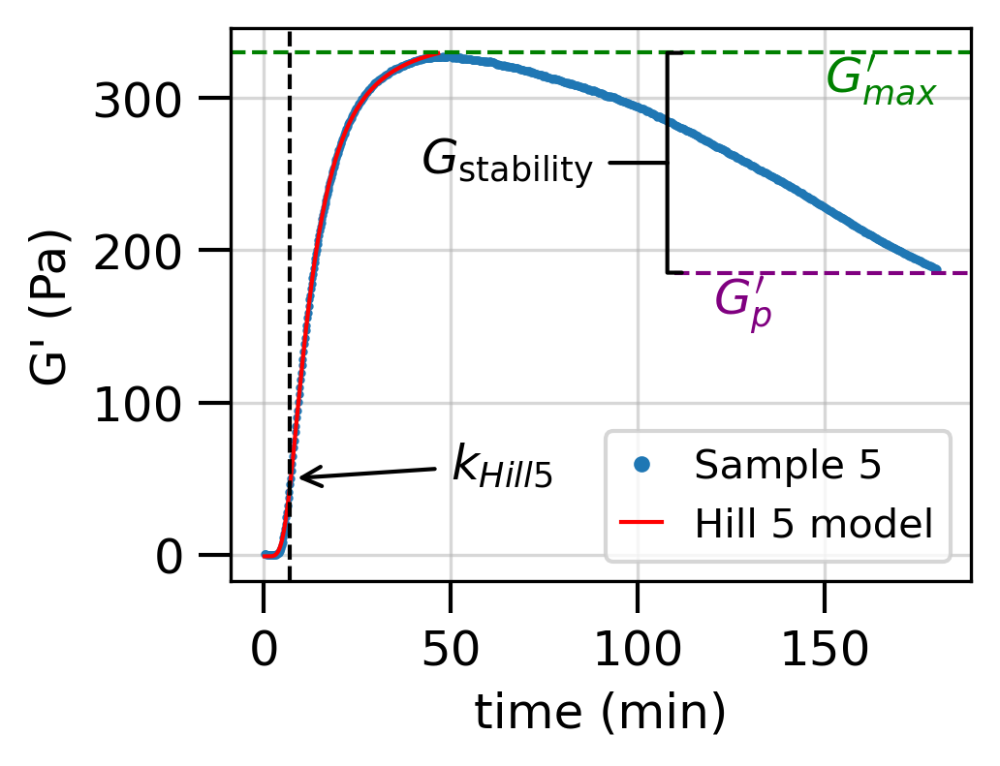

In [153]:
fig, ax = plt.subplots(nrows=1, ncols=1)
ax.plot(exp_5_x, exp_5_y, label="Sample 5", marker="o", lw=0, ms=1)
ax.plot(exp5_hill_x, exp_5_hill_y, c="r", lw=1, marker=None, label="Hill 5 model")

ax.set(xlabel="time (min)", ylabel="G' (Pa)")

# ax.legend()

ymin = -1.06
ymax = 330
Gplat = 185
k = 6.83
n = 2.27
E = 3

# ax.axhline(ymin, c="g", ls="--")
ax.axhline(ymax, c="g", ls="--")
ax.axhline(Gplat, c="purple", ls="--", xmin=0.6)
# ax.arrow(120, Gplat, 0, ymax - Gplat, length_includes_head=True, ls='--', color='purple', head_width=5, overhang=0)

ax.text(150, ymax, r"$G_{max}'$", va="top", color='g')
# ax.text(150, ymin, r"$G_{min}'$", va="bottom", color='g')
ax.text(120, Gplat, r"$G_{p}'$", va="top", color='purple')
ax.annotate(
    text=r"$G_\mathrm{stability}$",
    xy=[110, (ymax + Gplat) / 2],
    xytext=[65, (ymax + Gplat) / 2],
    arrowprops={"arrowstyle": "-[, widthB=2.27, lengthB=0.3"},
    ha='center',
    va='center'
)

plt.axvline(k, color='k', ls='--')
plt.annotate(text=r'$k_{Hill5}$', xy=[k, 50], xytext=[50, 50], arrowprops={'arrowstyle': '->'})

ax.grid(alpha=0.5)

plt.legend(fontsize='small', markerscale=3, handlelength=1)
plt.tight_layout()
plt.savefig('Example_Hill_Am5.png')

## NMR - paired graph

In [154]:
from pathlib import Path
from itertools import chain, cycle
from datetime import datetime
cmap = plt.cm.viridis

In [155]:
dps = list(Path('./simple_gel').glob('*dps'))
contin = list(Path('./simple_gel').glob('*txt'))
dps.sort(key = lambda x: int(str(x.stem).split('_')[1]))
contin.sort(key = lambda x: int(str(x.stem).split('_')[1]))

def get_datetime(path):
    return path.stem.split('_')[2]

time_format = '%Y%m%d%H%M%S'
first_time = datetime.strptime(get_datetime(contin[0]), time_format)
final_time = datetime.strptime(get_datetime(contin[-1]), time_format)
total_separation = (final_time - first_time).total_seconds() + 1

In [156]:
import matplotlib.patches as patches
from scipy.optimize import curve_fit
width, height = plt.rcParams['figure.figsize']

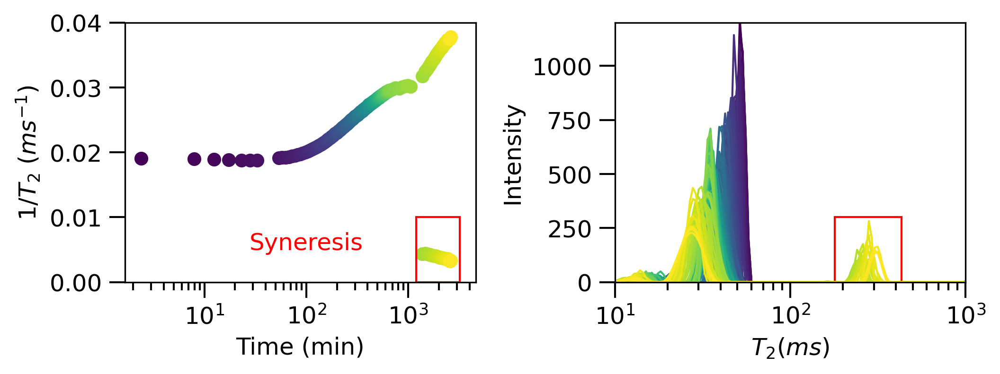

In [157]:
break_ = 136

fig, [ax1, ax2] = plt.subplots(nrows=1, ncols=2, figsize=(width * 2, height))
colors = cycle(list([cmap(x) for x in np.linspace(0, 1, len(contin))]))

for i in range(0, len(dps)):
    df_dps = pd.read_csv(dps[i], sep="\t", names=["index", "t", "I"])
    df_contin = (
        pd.read_csv(contin[i], sep="\t", names=["t2", "I"])
        .sort_values(by="t2")
        .reset_index(drop=True)
    )
    current_time = datetime.strptime(get_datetime(contin[i]), time_format)
    elapsed_time = current_time - first_time
    color = next(colors)

    if i >= break_:
        popt, pcov = curve_fit(
            lambda x, a, b, c, d: a * np.exp(-x / b) + c * np.exp(-x / d),
            df_dps["t"],
            df_dps["I"],
            p0=(70, 2000, 70, 3000),
            bounds=([0, 0, 0, 0], [np.inf, np.inf, np.inf, np.inf]),
        )
        ax1.scatter(elapsed_time.total_seconds() / 60, 1 / popt[1], color=color)
        ax1.scatter(elapsed_time.total_seconds() / 60, 1 / popt[3], color=color)
    else:
        popt, pcov = curve_fit(
            lambda x, a, b: a * np.exp(-x / b),
            df_dps["t"],
            df_dps["I"],
            p0=(70, 1000),
            bounds=([0, 0], [np.inf, np.inf]),
        )
        ax1.scatter(elapsed_time.total_seconds() / 60, 1 / popt[1], color=color)

    ax2.plot(df_contin["t2"], df_contin["I"], color=color)

    ax1.set_ylim(0, 0.04)
    ax2.set_xscale("log")
    ax2.set_xlim(10, 1000)
    ax2.set_ylim(-0.05, 1200)
    ax1.set(xlabel="Time (min)", ylabel=r"$1/T_2$ ($ms^{-1}$)")
    ax2.set(xlabel="$T_2 (ms)$", ylabel=r"Intensity")
    
    

rect1 = patches.Rectangle((1200, 0), 2000, 0.01, linewidth=1, edgecolor='r', facecolor='none')
rect2 = patches.Rectangle((180, 0), 250, 300, linewidth=1, edgecolor='r', facecolor='none')
ax1.add_patch(rect1)
ax2.add_patch(rect2)
ax1.text(100, 0.005, 'Syneresis', color='r', ha='center')

ax1.set_xscale('log')
    
plt.tight_layout()
plt.savefig('evolution NMR.png', dpi=300)

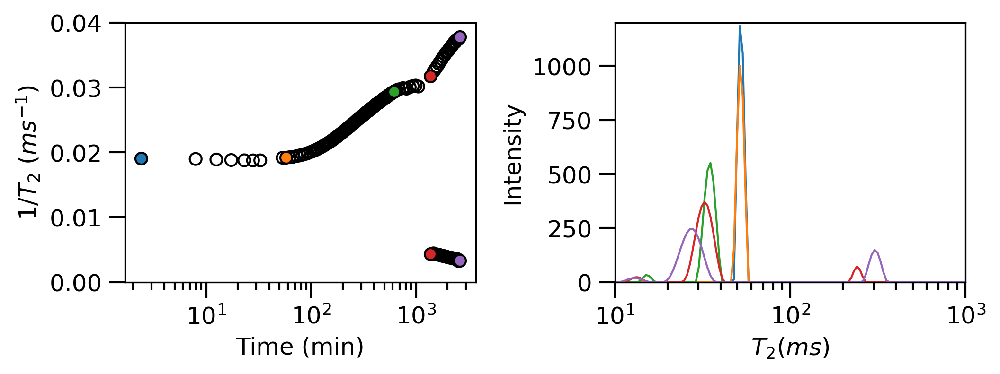

In [158]:
break_ = 136
points_of_interest = [1, 9, 120, 136, 158]

fig, [ax1, ax2] = plt.subplots(nrows=1, ncols=2, figsize=(width * 2, height))
colors = cycle(list([cmap(x) for x in np.linspace(0, 1, len(contin))]))
special_colors = ['C0', 'C1', 'C2', 'C3', 'C4']
special_colors.reverse()

for i in range(0, len(dps)):
    df_dps = pd.read_csv(dps[i], sep="\t", names=["index", "t", "I"])
    df_contin = (
        pd.read_csv(contin[i], sep="\t", names=["t2", "I"])
        .sort_values(by="t2")
        .reset_index(drop=True)
    )
    current_time = datetime.strptime(get_datetime(contin[i]), time_format)
    elapsed_time = current_time - first_time
    color = special_colors.pop() if i in points_of_interest else 'none'

    if i >= break_:
        popt, pcov = curve_fit(
            lambda x, a, b, c, d: a * np.exp(-x / b) + c * np.exp(-x / d),
            df_dps["t"],
            df_dps["I"],
            p0=(70, 2000, 70, 3000),
            bounds=([0, 0, 0, 0], [np.inf, np.inf, np.inf, np.inf]),
        )
        if i in points_of_interest:
            ax1.scatter(elapsed_time.total_seconds() / 60, 1 / popt[1], color=color, edgecolor='k', zorder=1000)
            ax1.scatter(elapsed_time.total_seconds() / 60, 1 / popt[3], color=color, edgecolor='k', zorder=1000)
        else:
            ax1.scatter(elapsed_time.total_seconds() / 60, 1 / popt[1], color=color, edgecolor='k')
            ax1.scatter(elapsed_time.total_seconds() / 60, 1 / popt[3], color=color, edgecolor='k')
    else:
        popt, pcov = curve_fit(
            lambda x, a, b: a * np.exp(-x / b),
            df_dps["t"],
            df_dps["I"],
            p0=(70, 1000),
            bounds=([0, 0], [np.inf, np.inf]),
        )
        if i in points_of_interest:
            ax1.scatter(elapsed_time.total_seconds() / 60, 1 / popt[1], color=color, edgecolor='k', zorder=1000)
        else:
            ax1.scatter(elapsed_time.total_seconds() / 60, 1 / popt[1], color=color, edgecolor='k')
            

    if i in points_of_interest:
        ax2.plot(df_contin["t2"], df_contin["I"], color=color)

    ax1.set_ylim(0, 0.04)

    ax2.set_xscale("log")
    ax2.set_xlim(10, 1000)
    ax2.set_ylim(-0.05, 1200)
    ax1.set(xlabel="Time (min)", ylabel=r"$1/T_2$ ($ms^{-1}$)")
    ax2.set(xlabel="$T_2 (ms)$", ylabel=r"Intensity")

ax1.set_xscale('log')
    
plt.tight_layout()
plt.savefig('evolution NMR 2.png', dpi=300)

## Rheology - frequency sweep plateau

In [159]:
freq = [
    0.01,
    0.013335,
    0.017783,
    0.023714,
    0.031623,
    0.04217,
    0.056234,
    0.074989,
    0.1,
    0.133352,
    0.177828,
    0.237137,
    0.316228,
    0.421697,
    0.562341,
    0.749894,
    1,
    1.333521,
    1.778279,
    2.371374,
    3.162278,
    4.216965,
    5.623414,
    7.498942,
    10,
    13.335215,
    17.782795,
    23.713737,
    31.622778,
    42.169651,
    56.234135,
    74.989426,
    100,
]

Gprime = [
    175.851242,
    168.466248,
    161.545242,
    157.455917,
    153.640915,
    151.650497,
    149.033371,
    148.481369,
    147.434189,
    146.835037,
    146.565247,
    146.761215,
    147.188034,
    147.280518,
    147.719376,
    148.18454,
    148.234207,
    149.251785,
    149.85231,
    150.844864,
    152.286469,
    153.70961,
    151.736954,
    151.853958,
    148.329529,
    146.095978,
    141.422531,
    132.521744,
    101.679443,
    55.694092,
    12.178955,
    133.929688,
    447.31543,
]

G2prime = [
    1.925061,
2.674054,
2.599262,
2.839545,
2.72255,
3.03762,
3.215199,
3.344923,
3.551399,
3.591871,
3.724262,
4.009283,
4.359306,
4.689814,
5.078311,
5.687166,
6.230894,
6.890125,
7.693941,
8.624026,
9.734721,
11.059431,
11.506454,
12.913249,
14.148866,
15.603765,
17.955463,
20.937845,
25.072252,
25.739649,
3.976532,
94.331871,
1233.101196,
]

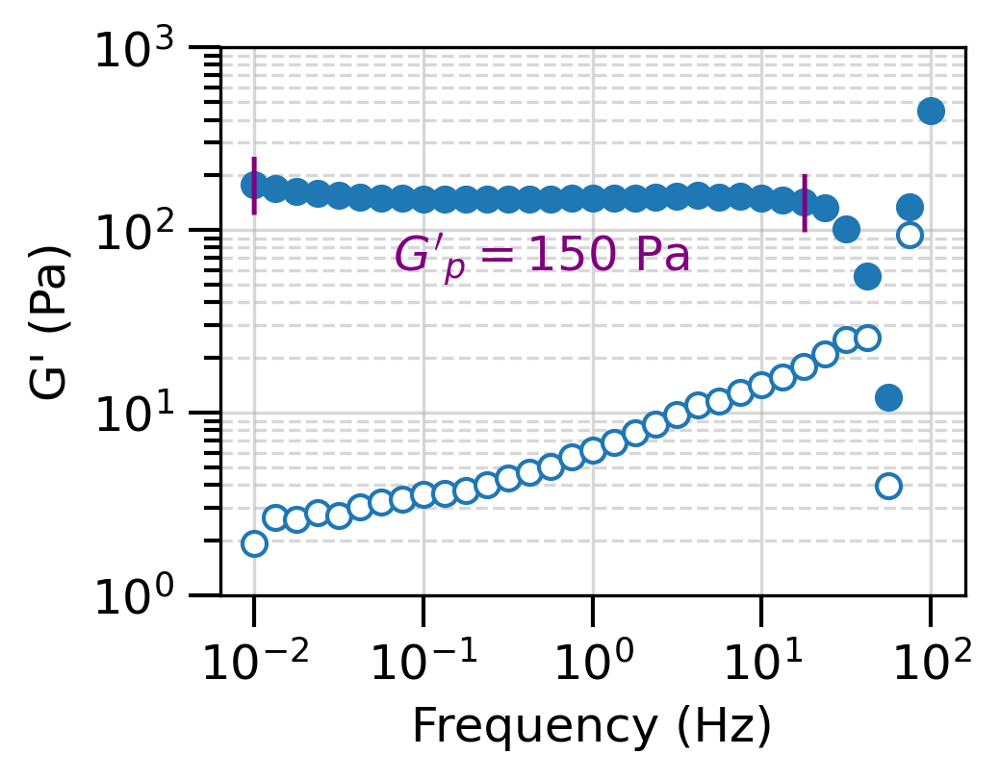

In [160]:
plt.plot(freq, Gprime, marker='o', lw=0, color='C0')
plt.plot(freq, G2prime, marker='o', lw=0, color='C0', mfc='w')
plt.yscale('log')
plt.xscale('log')
plt.xlabel('Frequency (Hz)')
plt.ylabel("G' (Pa)")
plt.tight_layout()
plt.ylim(1E0, 1E3)
plt.xticks([1E-2, 1E-1, 1E0, 1E1, 1E2])
plt.grid(which='major', axis='both', alpha=0.5, ls='-')
plt.grid(which='minor', axis='both', alpha=0.5, ls='--')

start = 0
stop = -7
average = np.mean(Gprime[start:stop+1])
average = 150
plt.text(freq[start], Gprime[start], '|', c='purple', fontsize='large', ha='center', va='center')
plt.text(freq[stop], Gprime[stop], '|', c='purple', fontsize='large', ha='center', va='center')
plt.text(0.5, 60, "$G'_{p}=$"+ f'{average:.0f} Pa', ha='center', color='purple')
plt.savefig('oscillatory_example_sample5.png')